<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/signals-and-predictability.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Signals and their predictability

*Deep Learning for Scientific Discovery, Jagiellonian University. Author Marcin Płodzień.*

A time series $s_1,s_2,\dots,s_N$ is a sequence of measurements of one quantity taken at equal time intervals $\Delta t$. The forecasting task depends on properties of the signal. We measure its memory of past values, the frequencies that carry its power, the number of past values needed to determine the present state of the generating system, the rate at which nearby states separate, and the effective degrees of freedom explored by the motion. These properties constrain forecasting accuracy and help us choose between linear and neural models.

Records of this kind come from every field of the doctoral school, for example a temperature station, a concentration in a chemical reactor, a population count in an ecosystem or a gene expression level sampled over a cell cycle. We develop the tools on three signals of known origin, so that every property measured from a record can be checked against the system that produced it, and the same tools apply unchanged to records from any field.

We work with three signals that are used throughout the time-series notebooks. The first is the $x$ coordinate of the Lorenz-63 model of thermal convection, a three-dimensional chaotic flow, that is, three coupled differential equations whose deterministic solutions are unpredictable beyond a finite time. The second is the Mackey–Glass delay equation for blood-cell production at three values of the feedback delay, which give a periodic orbit and two chaotic regimes. The third is the intensity of a chaotic far-infrared laser measured in the laboratory, the Santa Fe data set A. In all three cases each measured value $s_k$ is a function $h$ of a hidden state $\mathbf x_k$ of the system with more components than the record, a compressed projection of that state, and the methods of signal analysis recover properties of the hidden state from the record alone. The generated records (Section 1) allow us to compare time-series tasks on easy, chaotic and stochastic signals (Section 2). The physical equations of the three benchmark signals (Section 3) provide known dynamics against which to compare estimates made from measurements. The autocorrelation function (ACF) and power spectral density (PSD) describe their linear statistics using standard signal-processing methods (Sections 4 and 5). Delay embedding reconstructs the state space from a single measured coordinate (Section 6). The logistic map gives a simple example of deterministic chaos (Section 7). The Lyapunov exponents measure the average exponential rates at which nearby states separate or approach each other, and we compute them for the flows and the measured laser data (Section 8). They give a prediction horizon and the Kaplan–Yorke dimension of the attractor, the set of states on which the motion settles (Section 9). We collect these quantities in a numerical table (Section 10) to compare their implications for forecasting (Section 11). The Lyapunov algorithms of Section 8 (Benettin, Rosenstein, Sano–Sawada) go deeper than the lecture, which uses only their results.

All computations use JAX in double precision (`jax_enable_x64`). Where a standard library offers the same quantity (statsmodels for the ACF, scipy for periodograms, the Welch estimate and nearest-neighbour search) we compute it with both and compare.

> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. Execution starts with `JAX_PLATFORMS=cpu`, and all cells together run in a few minutes on a multi-core CPU.
> 2. `jax`, `scipy`, `statsmodels`, `pandas` and `matplotlib` are pre-installed in Colab.
> 3. Upload the Santa Fe data file (`santafe_laser.txt`) into a folder `data` next to the notebook.
> 4. Run the cells *in order*, since later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import scipy.signal
import scipy.stats
import scipy.optimize
from scipy.spatial import cKDTree
from statsmodels.tsa.stattools import acf as sm_acf

import jax
jax.config.update("jax_enable_x64", True)   # all signals and exponents in float64
import jax.numpy as jnp

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.3, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
COL = {"lorenz": UJBlue, "mg15": "#F2A65A", "mg25": DSOrange, "mg35": "#8C2D04", "santafe": "#2E7D32"}
LABEL = {"lorenz": "Lorenz $x$", "mg15": r"MG $\tau_{\rm MG}=15$", "mg25": r"MG $\tau_{\rm MG}=25$",
         "mg35": r"MG $\tau_{\rm MG}=35$", "santafe": "Santa Fe"}
KEYS = ["lorenz", "mg15", "mg25", "mg35", "santafe"]

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    """Save a slide figure as PDF (for the slides) and PNG; it is created at its printed size."""
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                                   # every number a slide may quote
t_start = time.time()
print("jax", jax.__version__, "| devices", jax.devices(), "| float64", jax.config.jax_enable_x64)

jax 0.11.0 | devices [CpuDevice(id=0)] | float64 True


<hr/>
## 1. Signals and protocol

The signal generators are shared by all time-series notebooks, so that every model is trained and tested on the same numbers. They integrate the equations with the fourth-order Runge–Kutta method (RK4) in `jax.lax.scan` and return $N=4000$ samples per signal. The same code defines the common protocol of the forecasting notebooks, a chronological split into a training block of 3000 samples, whose last 500 serve for validation, and a test block of the final 1000 samples, with rescaling to $[0,1]$ fitted on the training block only.

In [2]:
# Lorenz-63 with sigma = 10, rho = 28, beta = 8/3. RK4 with h = 0.01, one sample every 2 steps (dt = 0.02).
# Initial state (1, 1, 1); the first 2500 samples (50 time units) are discarded. We keep the x component.
def lorenz_rhs(u, sigma=10.0, rho=28.0, beta=8.0/3.0):
    x, y, z = u
    return jnp.array([sigma*(y - x), x*(rho - z) - y, x*y - beta*z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    """Returns array (n_samples, 3) sampled every `sub` RK4 steps (dt = sub*h)."""
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass dx/dt = beta x(t-tau)/(1 + x(t-tau)^n) - gamma x with beta = 0.2, gamma = 0.1, n = 10.
# RK4 with h = 0.1; the delayed value at the half step is the linear interpolation of the two stored values.
# Constant history x = 1.2 on [-tau, 0]; the first 3000 fine steps are discarded and every 10th point is kept
# (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) is the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Common protocol of the lecture: N = 4000 samples per signal; training block = first 3000 samples
# (its last 500 = validation), test block = last 1000; rescaling to [0, 1] with the training min/max.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

In [3]:
lor_states = np.asarray(lorenz_trajectory(N_SAMPLES))          # (4000, 3): x, y, z of Lorenz-63
sf_full = santafe()                                              # all measured samples of data set A
S = {"lorenz": lor_states[:, 0],
     "mg15": mackey_glass(15, N_SAMPLES), "mg25": mackey_glass(25, N_SAMPLES), "mg35": mackey_glass(35, N_SAMPLES),
     "santafe": sf_full[:N_SAMPLES]}
DT = {"lorenz": 0.02, "mg15": 1.0, "mg25": 1.0, "mg35": 1.0, "santafe": 1.0}   # sampling interval (time units)
UNIT = {"lorenz": "time unit", "mg15": "time unit", "mg25": "time unit", "mg35": "time unit", "santafe": "sample"}
for k in KEYS:
    assert S[k].shape == (N_SAMPLES,) and np.all(np.isfinite(S[k]))
    print(f"{LABEL[k]:22s} N = {len(S[k])}  mean = {S[k].mean():8.4f}  std = {S[k].std():8.4f}  "
          f"min = {S[k].min():8.4f}  max = {S[k].max():8.4f}")
print("Santa Fe record length:", len(sf_full))

Lorenz $x$             N = 4000  mean =  -0.4944  std =   7.8980  min = -18.0840  max =  17.9165
MG $\tau_{\rm MG}=15$  N = 4000  mean =   0.9370  std =   0.2163  min =   0.4919  max =   1.2827
MG $\tau_{\rm MG}=25$  N = 4000  mean =   0.9156  std =   0.2557  min =   0.2480  max =   1.3838
MG $\tau_{\rm MG}=35$  N = 4000  mean =   0.8859  std =   0.2926  min =   0.2069  max =   1.3932
Santa Fe               N = 4000  mean =  59.8158  std =  48.7465  min =   2.0000  max = 255.0000
Santa Fe record length: 10093


<hr/>
## 2. Time-series tasks and kinds of signals

### Recall and forecast

At the current step $k$ a model has seen the values $s_1,\dots,s_k$. Two tasks are defined by the target. In a recall task the target is a past value $y_k=s_{k-\tau}$, which tests memory. In a forecasting task the target is a future value $y_k=s_{k+\tau}$, and $\tau$ is called the horizon. We mark both on a stretch of the Santa Fe laser record, rescaled to $[-1,1]$ for the drawing.

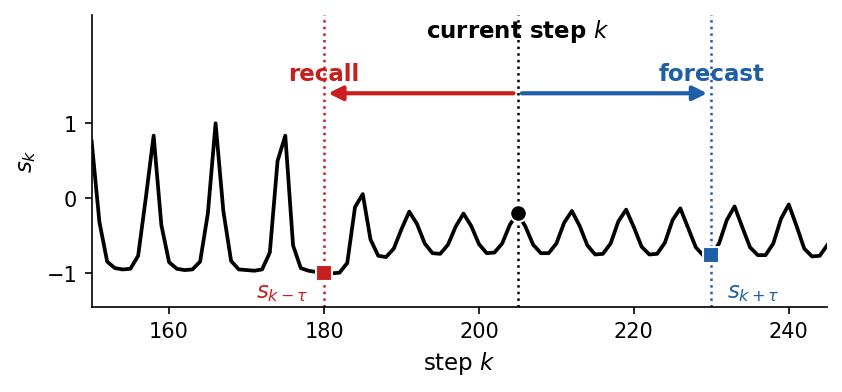

In [4]:
# a stretch of the Santa Fe record around a collapse, rescaled to [-1, 1] for the drawing only
seg = sf_full[150:246]
s_seg = 2 * (seg - seg.min()) / (seg.max() - seg.min()) - 1
k_seg = np.arange(150, 150 + len(seg))
K_NOW, TAU_DEMO = 205, 25                                 # current step k and the shift tau of the drawing
RED, BLUE = "#C81E1E", "#1F5FA8"                          # recall = red, forecast = blue
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5), layout="constrained")
    ax.plot(k_seg, s_seg, color="k", lw=1.8, zorder=2)
    for x, col, mk in [(K_NOW, "k", "o"), (K_NOW - TAU_DEMO, RED, "s"), (K_NOW + TAU_DEMO, BLUE, "s")]:
        i = x - k_seg[0]
        ax.axvline(x, color=col, ls=":", lw=1.2, zorder=1)
        ax.plot(x, s_seg[i], mk, color=col, ms=8, mec="white", mew=1.0, zorder=4)
    ax.text(K_NOW, 2.05, "current step $k$", ha="center", va="bottom", fontsize=11, fontweight="bold")
    for x1, col, lab in [(K_NOW - TAU_DEMO, RED, "recall"), (K_NOW + TAU_DEMO, BLUE, "forecast")]:
        ax.annotate("", xy=(x1, 1.4), xytext=(K_NOW, 1.4),
                    arrowprops=dict(arrowstyle="-|>", lw=2.0, color=col, mutation_scale=14))
        ax.text(x1, 1.5, lab, color=col, ha="center", va="bottom", fontsize=11, fontweight="bold")
    ax.text(K_NOW - TAU_DEMO - 2, -1.25, r"$s_{k-\tau}$", color=RED, ha="right", va="center", fontsize=11)
    ax.text(K_NOW + TAU_DEMO + 2, -1.25, r"$s_{k+\tau}$", color=BLUE, ha="left", va="center", fontsize=11)
    ax.set_xlim(k_seg[0], k_seg[-1]); ax.set_ylim(-1.45, 2.45); ax.set_yticks([-1, 0, 1])
    ax.set_xlabel("step $k$"); ax.set_ylabel("$s_k$")
    save(fig, "fig_task_recall_forecast"); plt.show()

### Memory tasks

A memory task tests what a model keeps of its own input. The input $s_k$ is a sequence of independent random numbers, so no value can be inferred from the others, and the only way to output an old input is to have stored it. In the recall task on such an input the target is $y_k=s_{k-\tau}$. In the NARMA-$n$ task (nonlinear autoregressive moving average of order $n$, Atiya and Parlos 2000) a fixed nonlinear system driven by $s$ produces the target

$$
\begin{aligned}
y_k &= 0.3\,y_{k-1}+0.05\,y_{k-1}\sum_{i=1}^{n}y_{k-i}\\
&\quad+1.5\,s_{k-n}\,s_{k-1}+0.1,\qquad s_k\in[0,0.5].
\end{aligned}
$$

The model sees only $s$ and has to reproduce $y_k$ at every step. The product $s_{k-n}s_{k-1}$ needs a memory of $n$ steps and a nonlinear feature, and the terms $y_{k-1},\dots,y_{k-n}$ are built from still older inputs, so a larger $n$ gives a harder task. We plot one input sequence together with its NARMA targets for $n=2,5,10$.

The two kinds of task are scored differently. A forecast is judged by the Pearson correlation $r$ between prediction and target and by the capacity $C=r^2$, which ask whether the forecast follows the shape of the signal. The recall task uses the same capacity $C(\tau)$, and its sum over $\tau$ is the memory capacity. NARMA asks for the values themselves, so it is scored by the normalised mean-square error

$$\mathrm{NMSE}=\frac{\sum_k (y_k-\hat y_k)^2}{\sum_k (y_k-\bar y)^2},$$

which is 0 for a perfect output and 1 for the constant output $\hat y_k=\bar y$.

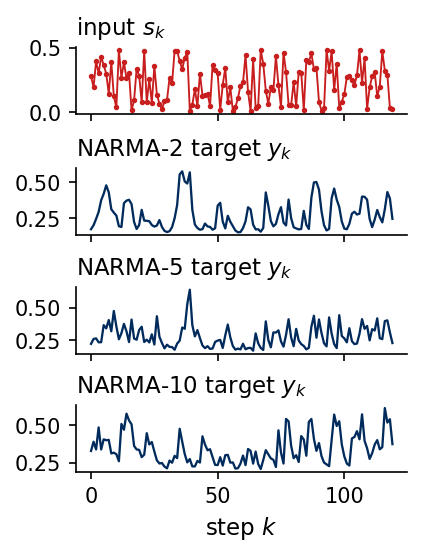

In [5]:
# memory tasks: independent random input s_k in [0, 0.5] and the NARMA-n targets driven by it
def narma(s, n):
    """NARMA-n target y driven by the input s (Atiya and Parlos 2000 form)."""
    y = np.zeros_like(s)
    for k in range(n, len(s)):
        y[k] = 0.3 * y[k-1] + 0.05 * y[k-1] * y[k-n:k].sum() + 1.5 * s[k-n] * s[k-1] + 0.1
    return y

rng_mem = np.random.default_rng(1)
s_mem = rng_mem.uniform(0, 0.5, 1200)
WASH, SHOW = 200, 120                                     # discarded transient, steps shown
k_show = np.arange(SHOW)
RED = "#C81E1E"
with mpl.rc_context(SLIDE_RC):
    # drawn for half the width of a slide, next to the text of the task
    fig, axs = plt.subplots(4, 1, figsize=(2.7, 3.6), sharex=True, layout="constrained")
    axs[0].plot(k_show, s_mem[WASH:WASH + SHOW], color=RED, lw=0.9, marker="o", ms=1.6)
    axs[0].set_title(r"input $s_k$", loc="left")
    for ax, n in zip(axs[1:], (2, 5, 10)):
        y_mem = narma(s_mem, n)
        assert np.all(np.isfinite(y_mem)) and y_mem.max() < 10, f"NARMA-{n} diverged"
        ax.plot(k_show, y_mem[WASH:WASH + SHOW], color=UJNavy, lw=1.1)
        ax.set_title(rf"NARMA-{n} target $y_k$", loc="left")
    for ax in axs:
        ax.locator_params(axis="y", nbins=2)
    axs[-1].set_xlabel("step $k$")
    save(fig, "fig_memory_tasks"); plt.show()


### Signals that are easy to forecast

Some signals are forecast without error once their rule is recognised. A constant is forecast by its last value (persistence). A periodic signal with period $P$ is forecast by the value one period earlier, $\hat s_{k+\tau}=s_{k+\tau-P}$ for $\tau\le P$. A quasi-periodic signal, a sum of sines whose frequencies have an irrational ratio, never repeats itself. A sum of two sines nevertheless obeys a linear recurrence of order four, $s_k=\sum_{j=1}^{4}a_js_{k-j}$, because each sine $\sin(\omega k)$ satisfies $s_k=2\cos\omega\,s_{k-1}-s_{k-2}$. We fit the four coefficients by least squares on the past and iterate the recurrence. We draw the past in black, the true continuation in grey and the forecast as a dashed blue line.

constant        max forecast error over 40 steps: 0.0e+00
periodic        max forecast error over 40 steps: 7.2e-15
quasi-periodic  max forecast error over 40 steps: 7.4e-12
fitted recurrence coefficients: [ 3.864533 -5.732744  3.864533 -1.      ]


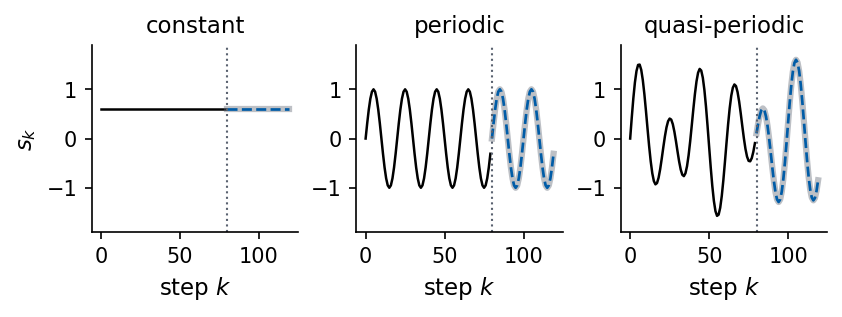

In [6]:
# three predictable signals: a constant, a periodic and a quasi-periodic one, each forecast from its past
k = np.arange(120); K0 = 80                                # the past is k < 80, the forecast covers k >= 80
P_DEMO = 20                                                # period of the periodic signal
GOLD = (1 + np.sqrt(5)) / 2                                # an irrational ratio of the two frequencies
sig_const = np.full(k.shape, 0.6)
sig_per = np.sin(2 * np.pi * k / P_DEMO)
sig_qp = np.sin(2 * np.pi * k / P_DEMO) + 0.6 * np.sin(2 * np.pi * k / (P_DEMO * GOLD))

fc_const = np.full(k.shape, sig_const[K0 - 1])             # persistence: the last value
fc_per = sig_per.copy()
for i in range(K0, len(k)):
    fc_per[i] = fc_per[i - P_DEMO]                          # repeat the value one period ago

# a sum of two sines obeys an exact linear recurrence of order 4; fit it on the past by least squares, then iterate
p = 4
X = np.stack([sig_qp[p - 1 - j:K0 - 1 - j] for j in range(p)], axis=1)
coef = np.linalg.lstsq(X, sig_qp[p:K0], rcond=None)[0]
fc_qp = sig_qp.copy()
for i in range(K0, len(k)):
    fc_qp[i] = coef @ fc_qp[i - 1:i - 1 - p:-1]
for name, s_, f_ in [("constant", sig_const, fc_const), ("periodic", sig_per, fc_per), ("quasi-periodic", sig_qp, fc_qp)]:
    print(f"{name:15s} max forecast error over 40 steps: {np.abs(s_[K0:] - f_[K0:]).max():.1e}")
print("fitted recurrence coefficients:", np.round(coef, 6))
nums["qp_coef"] = coef.tolist()

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.0), layout="constrained", sharex=True)
    for ax, s_, f_, title in zip(axs, (sig_const, sig_per, sig_qp), (fc_const, fc_per, fc_qp),
                                 ("constant", "periodic", "quasi-periodic")):
        ax.plot(k[:K0], s_[:K0], color="k", lw=1.2)
        ax.plot(k[K0:], s_[K0:], color=UJGray, lw=3.0, alpha=0.4)
        ax.plot(k[K0:], f_[K0:], "--", color=UJBlue, lw=1.3)
        ax.axvline(K0, color=UJGray, ls=":", lw=1.0)
        ax.set_title(title); ax.set_xlabel("step $k$"); ax.set_ylim(-1.9, 1.9)
    axs[0].set_ylabel("$s_k$")
    save(fig, "fig_trivial_signals"); plt.show()

All three forecasts agree with the true continuation to round-off. Such signals are trivial forecasting tasks, and a useful benchmark must be harder. A chaotic signal is produced by known deterministic equations, without any randomness, and still cannot be forecast far ahead because small errors grow exponentially (Sections 7 to 9). A stochastic signal is hard to forecast for a different reason. It is irregular because each new value contains a random part that no model can know in advance.

### Stochastic processes

A stochastic process is a family of random variables $s_k$ indexed by time. The simplest one is white noise, independent values $\varepsilon_k$ with zero mean and variance $\sigma^2$. Its best forecast is the mean, and no model can do better. Summing white noise gives the random walk $s_k=s_{k-1}+\varepsilon_k$, the discrete version of Brownian motion. Its variance grows as $k\sigma^2$, so it is not stationary, and its best forecast is the last value. The autoregressive process AR(1), $s_k=\phi s_{k-1}+\varepsilon_k$ with $|\phi|<1$, lies in between. It forgets its past at the rate $\phi$ per step, has the stationary variance $\sigma^2/(1-\phi^2)$, and its best forecast $\hat s_{k+\tau}=\phi^\tau s_k$ relaxes to the mean. It is the discrete form of the Ornstein–Uhlenbeck process, the velocity of a Brownian particle with friction. A process is (weakly) stationary when its mean and its covariances $\mathrm{cov}(s_k,s_{k+n})$ do not depend on $k$. We draw 20 realisations of each process (grey, one in blue) with $\sigma=1$ and $\phi=0.9$. The dashed lines are $\pm2$ standard deviations of the process, constant for white noise and AR(1) and growing as $2\sqrt{k}$ for the random walk.

random walk: ensemble std at k = 99 and 299: 8.4, 13.3 (sqrt(k+1) = 10.0, 17.3); 20 realisations only
AR(1) with phi = 0.9: stationary std 1/sqrt(1 - phi^2) = 2.29, sample std over all realisations 2.33


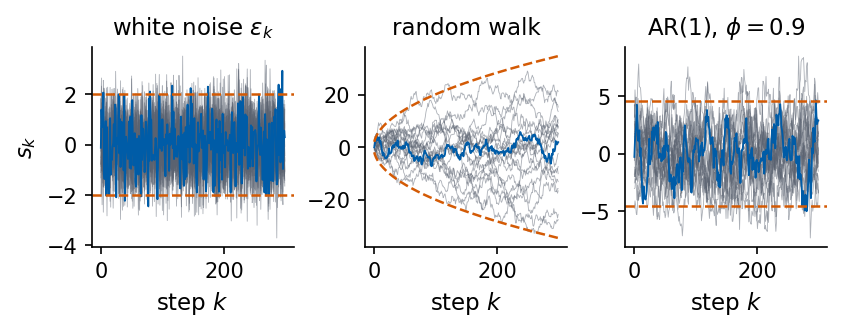

In [7]:
# three stochastic processes driven by independent Gaussian increments eps_k ~ N(0, 1)
PHI = 0.9                                                  # AR(1) coefficient
n_real, n_step = 20, 300
eps = np.asarray(jax.random.normal(jax.random.key(11), (n_real, n_step)))
white = eps
walk = np.cumsum(eps, axis=1)                              # s_k = s_{k-1} + eps_k, s_0 = eps_0
ar1 = np.zeros_like(eps)
ar1[:, 0] = eps[:, 0] / np.sqrt(1 - PHI**2)                # start in the stationary distribution
for i in range(1, n_step):
    ar1[:, i] = PHI * ar1[:, i - 1] + eps[:, i]
kk = np.arange(n_step)
print(f"random walk: ensemble std at k = 99 and 299: {walk[:, 99].std():.1f}, {walk[:, 299].std():.1f}"
      f" (sqrt(k+1) = {np.sqrt(100):.1f}, {np.sqrt(300):.1f}); 20 realisations only")
print(f"AR(1) with phi = {PHI}: stationary std 1/sqrt(1 - phi^2) = {1/np.sqrt(1 - PHI**2):.2f},"
      f" sample std over all realisations {ar1.std():.2f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.1), layout="constrained", sharex=True)
    for ax, data, title in zip(axs, (white, walk, ar1),
                               (r"white noise $\varepsilon_k$", "random walk", f"AR(1), $\\phi={PHI}$")):
        for r_ in range(1, n_real):
            ax.plot(kk, data[r_], color=UJGray, lw=0.4, alpha=0.5)
        ax.plot(kk, data[0], color=UJBlue, lw=0.9)
        ax.set_title(title); ax.set_xlabel("step $k$")
    axs[1].plot(kk, 2 * np.sqrt(kk + 1), "--", color=DSOrange, lw=1.2)
    axs[1].plot(kk, -2 * np.sqrt(kk + 1), "--", color=DSOrange, lw=1.2)
    for s_ in (+1, -1):
        axs[2].axhline(s_ * 2 / np.sqrt(1 - PHI**2), color=DSOrange, ls="--", lw=1.2)
        axs[0].axhline(s_ * 2, color=DSOrange, ls="--", lw=1.2)
    axs[0].set_ylabel("$s_k$")
    save(fig, "fig_stochastic_processes"); plt.show()

### Memory and frequencies of the kinds of signals

Two statistics introduced in Sections 4 and 5 already separate these kinds of signals, the autocorrelation function (ACF) $\rho(n)$, which measures how strongly the signal remembers its value $n$ steps ago, and the power spectral density (PSD), which shows how its variance is distributed over frequencies. Both are plotted in two rows. The top row holds three signals of known type, a periodic signal with period 20, white noise and AR(1) with $\phi=0.9$. The bottom row holds the three chaotic signals of this lecture, Lorenz $x$, Mackey–Glass with $\tau_{\rm MG}=25$ and the Santa Fe laser, which are described in Section 3. Dashed lines are the analytical results, $\rho(n)=\phi^n$ and $S(f)=2\sigma^2/|1-\phi e^{-2\pi if}|^2$ for AR(1) and the flat $S(f)=2\sigma^2$ for white noise (one-sided densities with unit sampling rate).

periodic signal: Welch peak at f = 0.0508 (1/P = 0.0500)


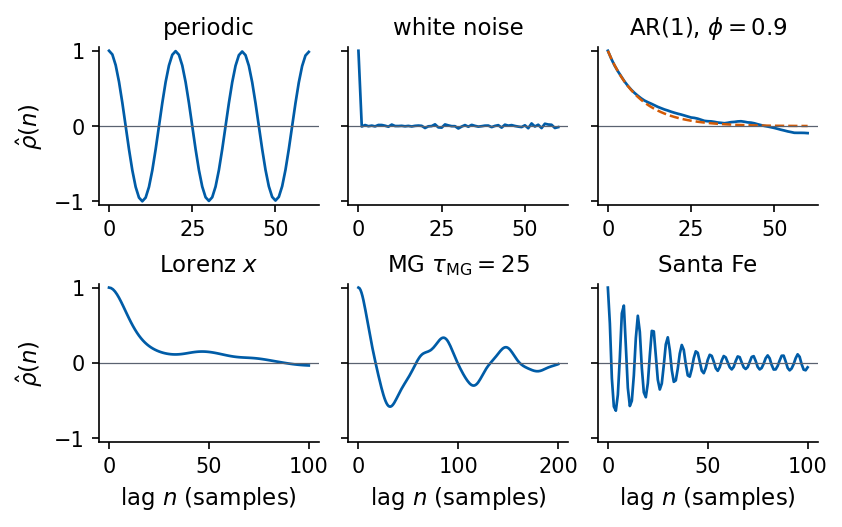

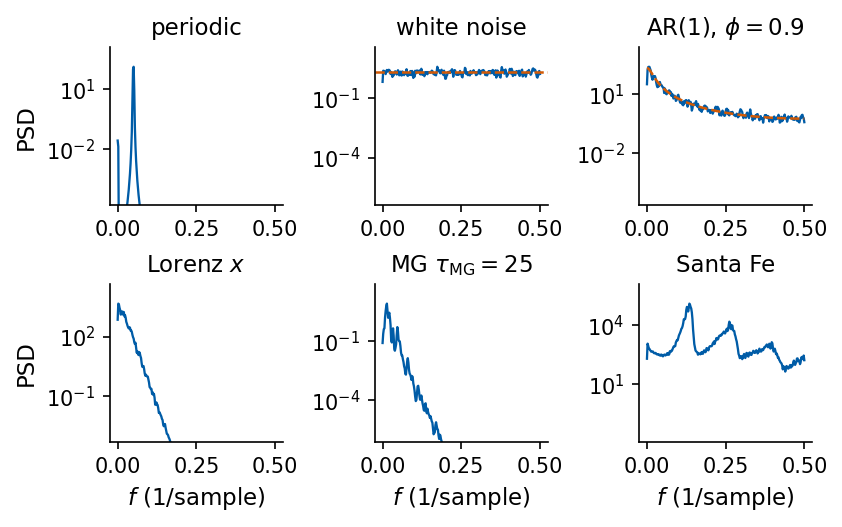

In [8]:
# ACF and power spectrum of three signals of known type and three chaotic signals, N = 4000 samples each
N_K = 4000
kinds = {"periodic": np.sin(2 * np.pi * np.arange(N_K) / P_DEMO),
         "white noise": np.asarray(jax.random.normal(jax.random.key(12), (N_K,)))}
e_ = np.asarray(jax.random.normal(jax.random.key(13), (N_K,)))
a_ = np.zeros(N_K); a_[0] = e_[0] / np.sqrt(1 - PHI**2)
for i in range(1, N_K):
    a_[i] = PHI * a_[i - 1] + e_[i]
kinds[f"AR(1), $\\phi={PHI}$"] = a_
chaotic = {"Lorenz $x$": S["lorenz"], LABEL["mg25"]: S["mg25"], "Santa Fe": S["santafe"]}
LAGS_CHAOS = {"Lorenz $x$": 100, LABEL["mg25"]: 200, "Santa Fe": 100}   # lags in samples, a few correlation times each

def acf_simple(x, n_lags):
    """rho_hat(n) = sum_k (x_k - m)(x_{k+n} - m) / sum_k (x_k - m)^2."""
    x = x - x.mean()
    return np.array([np.dot(x[:len(x) - n], x[n:]) for n in range(n_lags + 1)]) / np.dot(x, x)

# top row: signals of known type; bottom row: the chaotic signals of this lab
LAGS = 60
rows = [[(name, x, LAGS) for name, x in kinds.items()],
        [(name, x, LAGS_CHAOS[name]) for name, x in chaotic.items()]]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.4), layout="constrained", sharey=True)
    for ax_row, row in zip(axs, rows):
        for ax, (name, x, n_lag) in zip(ax_row, row):
            r_ = acf_simple(x, n_lag)
            ax.plot(np.arange(n_lag + 1), r_, color=UJBlue, lw=1.3)
            if name.startswith("AR"):
                ax.plot(np.arange(n_lag + 1), PHI ** np.arange(n_lag + 1), "--", color=DSOrange, lw=1.2)
            ax.axhline(0, color=UJGray, lw=0.6)
            ax.set_title(name)
    for ax in axs[1]:
        ax.set_xlabel("lag $n$ (samples)")
    for ax in axs[:, 0]:
        ax.set_ylabel(r"$\hat\rho(n)$")
    axs[0, 0].set_ylim(-1.05, 1.05)
    save(fig, "fig_kinds_acf"); plt.show()

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.4), layout="constrained")
    for ax_row, row in zip(axs, rows):
        for ax, (name, x, _) in zip(ax_row, row):
            f, P = scipy.signal.welch(x - x.mean(), fs=1.0, nperseg=512)
            ax.semilogy(f, P, color=UJBlue, lw=1.1)
            if name.startswith("AR"):        # exact one-sided PSD of AR(1): 2 / |1 - phi e^{-2 pi i f}|^2
                ax.semilogy(f, 2 / np.abs(1 - PHI * np.exp(-2j * np.pi * f))**2, "--", color=DSOrange, lw=1.2)
            if name == "white noise":
                ax.axhline(2.0, color=DSOrange, ls="--", lw=1.2)
            ax.set_ylim(P.max() * 1e-7, P.max() * 10)
            ax.set_title(name); ax.set_xticks([0, 0.25, 0.5])
    for ax in axs[1]:
        ax.set_xlabel("$f$ (1/sample)")
    for ax in axs[:, 0]:
        ax.set_ylabel("PSD")
    save(fig, "fig_kinds_psd"); plt.show()
f_qp, P_qp = scipy.signal.welch(kinds["periodic"], fs=1.0, nperseg=512)
print(f"periodic signal: Welch peak at f = {f_qp[np.argmax(P_qp)]:.4f} (1/P = {1/P_DEMO:.4f})")

The comparison uses six signals, plotted over their first 300 samples. The top row holds three signals whose type is known by construction, a sine wave with period 20, white noise and the AR(1) process with $\phi=0.9$. The bottom row holds the three chaotic signals of this lecture, the $x$ coordinate of Lorenz-63, Mackey–Glass with $\tau_{\rm MG}=25$ and the Santa Fe laser.

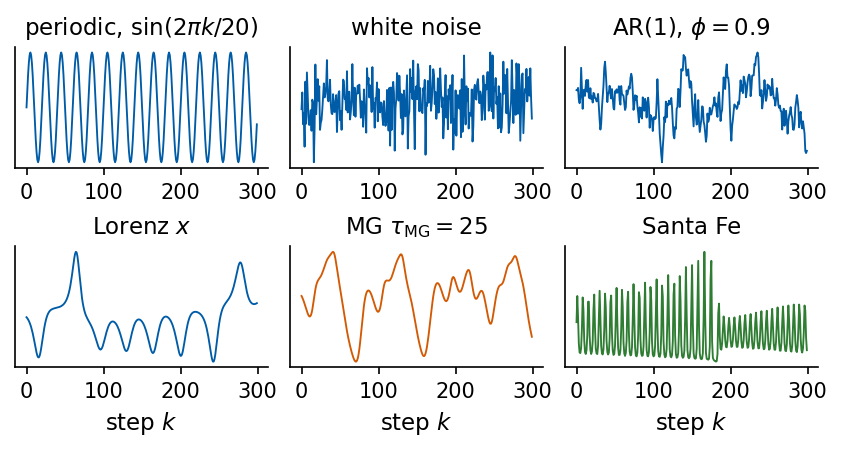

In [9]:
# the six test signals of the ACF and PSD comparison: three of known type (top) and the three chaotic signals (bottom)
six = [("periodic, $\\sin(2\\pi k/20)$", kinds["periodic"], UJBlue),
       ("white noise", kinds["white noise"], UJBlue),
       (f"AR(1), $\\phi={PHI}$", kinds[f"AR(1), $\\phi={PHI}$"], UJBlue),
       ("Lorenz $x$", S["lorenz"], COL["lorenz"]),
       (LABEL["mg25"], S["mg25"], COL["mg25"]),
       ("Santa Fe", S["santafe"], COL["santafe"])]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 2.9), layout="constrained")
    for ax, (name, x, col) in zip(axs.ravel(), six):
        ax.plot(np.arange(300), x[:300], color=col, lw=0.9)
        ax.set_title(name); ax.set_yticks([])
    for ax in axs[1]:
        ax.set_xlabel("step $k$")
    save(fig, "fig_six_signals"); plt.show()


The periodic signal keeps its correlation forever and puts its power into one line at $f=1/20$ (with leakage of the Welch window around it). White noise forgets immediately and has a flat spectrum. AR(1) forgets exponentially and has a smooth spectrum concentrated at low frequencies. Lorenz $x$ forgets more slowly than AR(1) and has a broad spectrum without sharp lines, so from the ACF and the PSD alone it resembles a coloured random process. Telling chaos apart from noise requires the tools of Sections 6 to 9.

<hr/>
## 3. Physics of the three signals

### Lorenz-63 convection model

A horizontal fluid layer heated from below starts to convect when the temperature difference across it exceeds a threshold (Rayleigh–Bénard convection). Above the threshold warm fluid rises and cool fluid sinks in rotating cylinders called convection rolls. Lorenz expanded the velocity and temperature fields in spatial Fourier modes, kept only the three of largest scale, and obtained [E. N. Lorenz, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2)]
$$
\dot x=\sigma(y-x),\qquad \dot y=x(\rho-z)-y,\qquad \dot z=xy-\beta z .
$$
The variable $x$ measures the rate of convective circulation, $y$ the horizontal temperature difference between rising and sinking fluid, and $z$ the deviation of the vertical temperature profile from linear conduction. The Prandtl number $\sigma$ is the ratio of viscosity to thermal diffusivity, a material property that compares how fast the fluid evens out differences of velocity with how fast it evens out differences of temperature. The normalised Rayleigh number $\rho$ measures the heating, the strength of the buoyancy drive relative to friction and heat conduction, scaled so that convection starts at $\rho=1$. The parameter $\beta$ is a geometric factor set by the width-to-height ratio of the convection rolls. We use the standard values $\sigma=10$, $\rho=28$, $\beta=8/3$, and we observe only $x(t)$, sampled every $\Delta t=0.02$ time units.

The state of the model is the point $\mathbf u=(x,y,z)$, and the space of all such points is the state space, also called phase space. The equations assign to every state a velocity $\mathbf F(\mathbf u)$, the vector field, and a fixed point is a state that does not change in time. For $\rho>1$ the vector field has three fixed points $\mathbf F(\mathbf u^*)=0$, the conducting state at the origin and two states of steady convection $C_\pm=(\pm\sqrt{\beta(\rho-1)},\pm\sqrt{\beta(\rho-1)},\rho-1)$ with opposite senses of rotation. Their stability follows from the eigenvalues of the Jacobian $J_{ij}=\partial F_i/\partial u_j$ at the fixed point. A small perturbation grows along every eigenvector whose eigenvalue has a positive real part. We obtain $J$ with `jax.jacfwd` and locate numerically the value $\rho_c$ at which $C_\pm$ lose stability.

In [10]:
sigma, rho, beta = 10.0, 28.0, 8.0 / 3.0
jac_rhs = jax.jacfwd(lorenz_rhs)                     # Jacobian J = dF/du of the vector field, shape (3, 3)

def fixed_points(rho):
    c = np.sqrt(beta * (rho - 1.0))
    return {"origin": np.zeros(3), "C+": np.array([c, c, rho - 1.0]), "C-": np.array([-c, -c, rho - 1.0])}

for name, u in fixed_points(rho).items():
    assert np.allclose(lorenz_rhs(jnp.array(u)), 0.0, atol=1e-12)      # F(u*) = 0
    ev = np.linalg.eigvals(np.asarray(jac_rhs(jnp.array(u))))
    print(f"{name:7s} u* = {np.round(u, 3)}   eigenvalues of J: {np.round(np.sort_complex(ev), 3)}")

# the largest real part of the eigenvalues at C+ as a function of rho; its zero is the loss of stability
def max_re(r):
    u = fixed_points(r)["C+"]
    return np.linalg.eigvals(np.asarray(jax.jacfwd(lambda v: lorenz_rhs(v, rho=r))(jnp.array(u)))).real.max()
rho_c = scipy.optimize.brentq(max_re, 15.0, 28.0)
ev_c = np.linalg.eigvals(np.asarray(jac_rhs(jnp.array(fixed_points(rho)["C+"]))))
omega_c = np.abs(ev_c.imag).max()
nums["lorenz_rho_c"] = rho_c
nums["lorenz_Cplus_eig"] = [float(ev_c.real.min()), float(ev_c.real.max()), float(omega_c)]
nums["lorenz_div"] = -(sigma + 1 + beta)
print(f"C+ and C- lose stability at rho_c = {rho_c:.3f}")
print(f"at rho = 28: complex pair at C+ has Re = {ev_c.real.max():.4f}, Im = {omega_c:.4f}, "
      f"rotation frequency Im/(2 pi) = {omega_c/(2*np.pi):.4f} per time unit")
print(f"trace of J (= div F, the same at every point) = {np.trace(np.asarray(jac_rhs(jnp.array([1., 2., 3.])))):.4f}"
      f" ; -(sigma + 1 + beta) = {-(sigma + 1 + beta):.4f}")

origin  u* = [0. 0. 0.]   eigenvalues of J: [-22.828+0.j  -2.667+0.j  11.828+0.j]
C+      u* = [ 8.485  8.485 27.   ]   eigenvalues of J: [-13.855 +0.j      0.094-10.195j   0.094+10.195j]
C-      u* = [-8.485 -8.485 27.   ]   eigenvalues of J: [-13.855 +0.j      0.094-10.195j   0.094+10.195j]
C+ and C- lose stability at rho_c = 24.737
at rho = 28: complex pair at C+ has Re = 0.0940, Im = 10.1945, rotation frequency Im/(2 pi) = 1.6225 per time unit
trace of J (= div F, the same at every point) = -13.6667 ; -(sigma + 1 + beta) = -13.6667


At $\rho=28$ the origin has one unstable direction (eigenvalue 11.828), and $C_\pm$ have one strongly contracting direction (eigenvalue $-13.855$) and a complex pair $0.094\pm10.195\,i$. The trajectory therefore spirals outwards around $C_+$ or $C_-$ with angular frequency 10.19, which is $1.62$ rotations per time unit, until it is thrown over to the other lobe. Both convective states lose stability at $\rho_c=24.737$. The trace of $J$ equals $-(\sigma+1+\beta)=-13.667$ at every point, a fact we use in Section 7.

We draw the attractor, the set of states that the trajectory visits after the initial transient has died out, in the full state space with $C_\pm$ marked by dots (left panel), and the observed coordinate $x(t)$ over 20 time units (right panel). The dashed lines are the values $\pm\sqrt{\beta(\rho-1)}$ of $x$ at $C_\pm$. The signal oscillates around one of them with growing amplitude and jumps irregularly to the other.

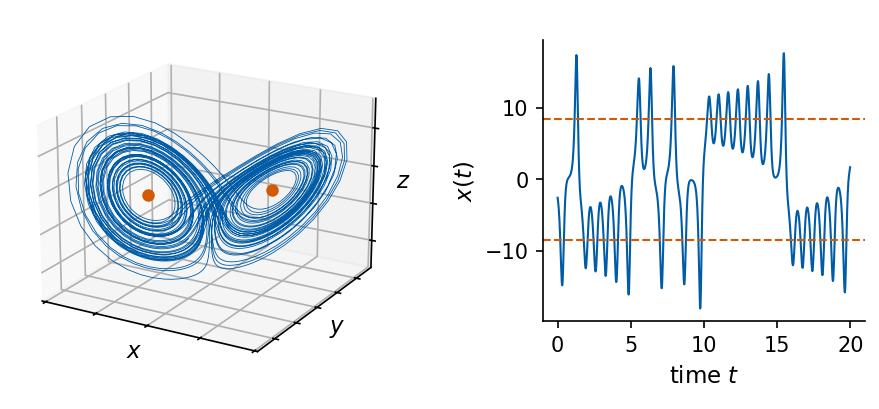

In [11]:
t_lor = np.arange(N_SAMPLES) * DT["lorenz"]
fp = fixed_points(rho)
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.6))
    ax = fig.add_axes([-0.04, 0.0, 0.46, 1.0], projection="3d")
    ax.plot(*lor_states[:2500].T, lw=0.4, color=UJBlue)
    for name in ("C+", "C-"):
        ax.scatter(*fp[name], color=DSOrange, s=25, zorder=5)
    ax.set_xlabel("$x$", labelpad=-12); ax.set_ylabel("$y$", labelpad=-12); ax.set_zlabel("$z$", labelpad=-12)
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([]); ax.view_init(elev=20, azim=-60)
    ax2 = fig.add_axes([0.6, 0.2, 0.39, 0.72])
    ax2.plot(t_lor[:1000], S["lorenz"][:1000], color=UJBlue, lw=1.0)
    for s_ in (+1, -1):
        ax2.axhline(s_ * np.sqrt(beta * (rho - 1)), color=DSOrange, ls="--", lw=1.0)
    ax2.set_xlabel("time $t$"); ax2.set_ylabel("$x(t)$")
    save(fig, "fig_lorenz_attractor"); plt.show()

### Mackey–Glass delay equation

Mackey and Glass modelled the concentration $x(t)$ of circulating blood cells, whose production is regulated by the concentration at an earlier time, because new cells need a maturation time $\tau_{\rm MG}$ [M. C. Mackey and L. Glass, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)],
$$
\dot x(t)=\frac{\beta\,x(t-\tau_{\rm MG})}{1+x(t-\tau_{\rm MG})^{n}}-\gamma\,x(t).
$$
The cells decay at rate $\gamma$, and the production term grows for small delayed concentration and is suppressed for large delayed concentration, with sharpness set by $n$. We use $\beta=0.2$ (unrelated to the Lorenz $\beta$), $\gamma=0.1$, $n=10$ and vary only the delay. To integrate the equation from time $t$ onwards we need the whole history $x(t')$ for $t'\in[t-\tau_{\rm MG},t]$, so the state of the system is a function on an interval and the state space is infinite-dimensional. The RK4 scheme with step $h=0.1$ stores this history as the vector $(x_{i-L},\dots,x_i)$ of length $L+1$ with $L=\tau_{\rm MG}/h$, the delay window in the generator code. As the delay grows, the constant solution (the fixed point) loses stability and a self-sustained oscillation appears, a transition called a Hopf bifurcation. The oscillation traces a closed curve in state space, a limit cycle, and at larger delays the motion becomes chaotic. We use $\tau_{\rm MG}=15$, 25 and 35, which give a limit cycle and two chaotic signals. Section 9 shows that the attractor at 35 has the higher dimension, while nearby states separate faster at 25, so a longer delay does not make the signal less predictable. The signal is sampled once per time unit.

We plot 600 samples of each signal in the upper row and the plane $(x(t-\tau_{\rm MG}),x(t))$ in the lower row. For $\tau_{\rm MG}=15$ the curve closes after two loops of different size, and for $\tau_{\rm MG}=25$ and 35 it fills a band that becomes wider with the delay.

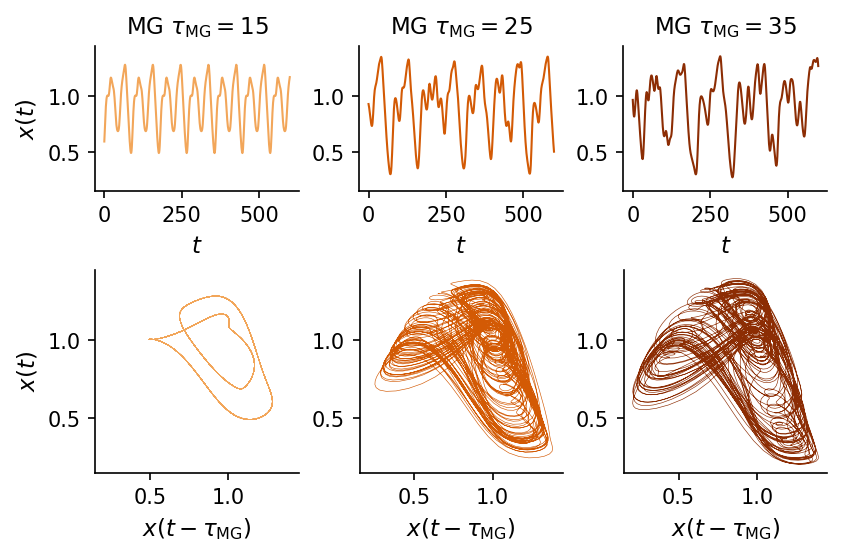

In [12]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.6), layout="constrained",
                            gridspec_kw=dict(height_ratios=[1, 1.4]))
    for c, (k, tau) in enumerate([("mg15", 15), ("mg25", 25), ("mg35", 35)]):
        x = S[k]
        axs[0, c].plot(np.arange(600), x[:600], color=COL[k], lw=1.0)
        axs[0, c].set_title(LABEL[k]); axs[0, c].set_xlabel("$t$"); axs[0, c].set_ylim(0.15, 1.45)
        axs[1, c].plot(x[:-tau], x[tau:], color=COL[k], lw=0.3)     # unit sampling, so the delay is tau samples
        axs[1, c].set_xlabel(r"$x(t-\tau_{\rm MG})$"); axs[1, c].set_aspect("equal")
        axs[1, c].set_xlim(0.15, 1.45); axs[1, c].set_ylim(0.15, 1.45)
    axs[0, 0].set_ylabel("$x(t)$"); axs[1, 0].set_ylabel("$x(t)$")
    save(fig, "fig_mackey_glass_taus"); plt.show()

The lower panels plot $x(t-\tau_{\rm MG})$ against $x(t)$, a two-dimensional projection of the orbit in which the delay of the plot equals the delay of the equation. For $\tau_{\rm MG}=15$ the orbit is a limit cycle, a closed curve that the signal traces again in every period, and its projection is a single closed line. The state of a delay equation is the whole history $x(s)$ for $t-\tau_{\rm MG}\le s\le t$, so its phase space has infinitely many dimensions, and a longer delay leaves room for more active directions. For $\tau_{\rm MG}=25$ and $35$ the orbit is chaotic and never closes. Its attractor has the Kaplan–Yorke dimensions 3.16 and 3.41 computed in Section 9, estimates of the fractal dimension of the attractor from its Lyapunov exponents, both larger than 2, and a set of dimension larger than 2 projected onto a plane covers an area. Successive loops pass close to each other without coinciding, and together they fill a band that looks like a surface. The growth of the attractor dimension with the delay was found by Farmer [J. D. Farmer, Physica D **4**, 366 (1982), [doi:10.1016/0167-2789(82)90042-2](https://doi.org/10.1016/0167-2789(82)90042-2)].

The kinds of attractor, the sets on which the motion settles after a transient, are easiest to see in three systems. A damped pendulum loses energy and comes to rest, so its attractor is a fixed point. The Van der Pol oscillator $\ddot x=(1-x^2)\dot x-x$ pumps energy in at small amplitude and removes it at large amplitude. Orbits started inside and outside (grey) both end on the same closed curve (orange), a limit cycle, which the motion traces once per period. Lorenz-63 settles on a strange attractor, called strange because the motion on it is chaotic, with an orbit that never closes and nearby orbits that separate, and because the set itself is a fractal, a sheet folded over and over with a dimension that is not a whole number.

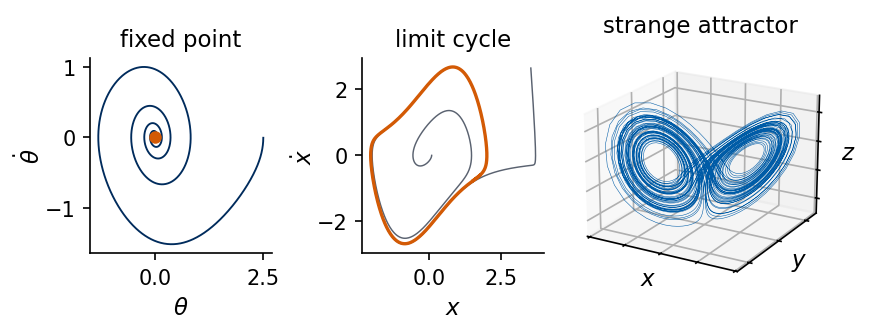

In [13]:
# three kinds of attractor: fixed point (damped pendulum), limit cycle (Van der Pol oscillator), strange attractor (Lorenz-63)
def rk4_orbit(f, u0, dt, n):
    """RK4 orbit of u' = f(u) from u0; returns n states."""
    u = np.array(u0, float); out = np.empty((n, len(u)))
    for i in range(n):
        k1 = f(u); k2 = f(u + 0.5 * dt * k1); k3 = f(u + 0.5 * dt * k2); k4 = f(u + dt * k3)
        u = u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4); out[i] = u
    return out
pendulum = lambda u: np.array([u[1], -np.sin(u[0]) - 0.25 * u[1]])        # theta'' = -sin(theta) - 0.25 theta'
van_der_pol = lambda u: np.array([u[1], (1 - u[0]**2) * u[1] - u[0]])     # x'' = (1 - x^2) x' - x
pend = rk4_orbit(pendulum, [2.5, 0.0], 0.01, 6000)
vdp_in, vdp_out = rk4_orbit(van_der_pol, [0.1, 0.0], 0.01, 4000), rk4_orbit(van_der_pol, [3.5, 3.0], 0.01, 4000)
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.0))
    ax1 = fig.add_axes([0.10, 0.22, 0.22, 0.65])
    ax1.plot(pend[:, 0], pend[:, 1], color=UJNavy, lw=0.9)
    ax1.plot(0, 0, "o", color=DSOrange, ms=5)
    ax1.set_xlabel(r"$\theta$"); ax1.set_ylabel(r"$\dot\theta$", labelpad=0); ax1.set_title("fixed point")
    ax2 = fig.add_axes([0.43, 0.22, 0.22, 0.65])
    ax2.plot(*vdp_in.T, color=UJGray, lw=0.7); ax2.plot(*vdp_out.T, color=UJGray, lw=0.7)
    ax2.plot(*vdp_in[-700:].T, color=DSOrange, lw=1.6)                     # the last period: the cycle itself
    ax2.set_xlabel("$x$"); ax2.set_ylabel(r"$\dot x$", labelpad=0); ax2.set_title("limit cycle")
    ax3 = fig.add_axes([0.68, 0.0, 0.32, 1.0], projection="3d")
    ax3.plot(*lor_states[:3000].T, lw=0.25, color=UJBlue)
    ax3.set_title("strange attractor", pad=-2)
    ax3.set_xticklabels([]); ax3.set_yticklabels([]); ax3.set_zticklabels([])
    for setter, lab in zip((ax3.set_xlabel, ax3.set_ylabel, ax3.set_zlabel), ("$x$", "$y$", "$z$")):
        setter(lab, labelpad=-12)
    ax3.view_init(elev=20, azim=-60)
    save(fig, "fig_attractor_types"); plt.show()


### Santa Fe laser data

The third signal is measured. It is the output intensity of a far-infrared ammonia (NH$_3$) laser in a regime of chaotic pulsations, data set A of the Santa Fe Institute time-series competition. The chaotic pulsations of this laser are described by Hübner, Abraham and Weiss [U. Hübner, N. B. Abraham and C. O. Weiss, Phys. Rev. A **40**, 6354 (1989), [doi:10.1103/PhysRevA.40.6354](https://doi.org/10.1103/PhysRevA.40.6354)]. A laser consists of an amplifying medium of molecules placed between mirrors, the cavity, and supplied with energy, the pump. A single-mode laser, which oscillates at one frequency, is described by the Maxwell–Bloch equations, in which the light is a classical field and each molecule a system with two energy levels. They couple the cavity field $E$, the polarisation $P$ of the medium, which is the oscillating electric dipole moment that the field induces in the molecules, and the population inversion $D$, the excess of molecules in the upper level over the lower one, which allows the light to be amplified,
$$
\dot E=-\gamma_c(E-gP),\qquad \dot P=-\gamma_\perp(P-ED),\qquad \dot D=-\gamma_\parallel(D-D_0+EP),
$$
with cavity decay rate $\gamma_c$, polarisation decay rate $\gamma_\perp$, inversion relaxation rate $\gamma_\parallel$, coupling $g$ and pump $D_0$. After a linear rescaling these equations have the algebraic form of Lorenz-63. In most lasers the three rates differ by orders of magnitude, the fast variables follow the slow ones, and the dynamics reduce to one or two dimensions where chaos cannot occur. In the NH$_3$ laser the three rates are comparable, all three variables stay active, and chaotic pulsations appear as the pump is raised. The detector measures the intensity $I\propto E^2$, one scalar and compressed projection of the three-dimensional hidden state.

The data are integers, recorded by an 8-bit converter, and the measurement noise and the finite resolution are part of the signal. We characterise the first 4000 of the 10093 samples. The sampling interval is one sample, and we quote all times in samples.

all samples integer: True; range 0 .. 255; distinct values 243 of 256 possible 8-bit levels


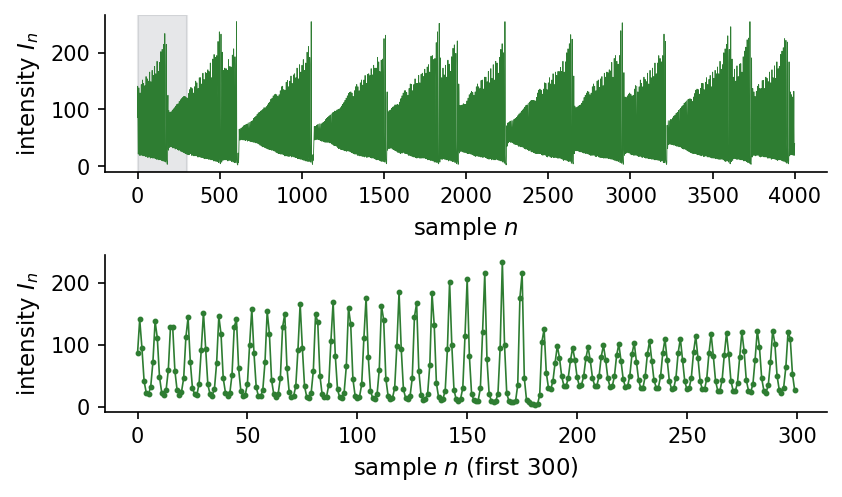

In [14]:
sf = S["santafe"]
is_int = np.all(sf_full == np.round(sf_full))
print(f"all samples integer: {is_int}; range {sf_full.min():.0f} .. {sf_full.max():.0f}; "
      f"distinct values {len(np.unique(sf_full))} of 256 possible 8-bit levels")
nums["santafe_len_full"] = int(len(sf_full))
nums["santafe_distinct_levels"] = int(len(np.unique(sf_full)))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.2), layout="constrained")
    axs[0].plot(np.arange(N_SAMPLES), sf, color=COL["santafe"], lw=0.4)
    axs[0].axvspan(0, 300, color=UJGray, alpha=0.15)
    axs[0].set_ylabel("intensity $I_n$"); axs[0].set_xlabel("sample $n$")
    axs[1].plot(np.arange(300), sf[:300], "-o", color=COL["santafe"], lw=0.8, ms=1.8)
    axs[1].set_ylabel("intensity $I_n$"); axs[1].set_xlabel("sample $n$ (first 300)")
    save(fig, "fig_santafe_trace"); plt.show()

All 10093 values are integers between 0 and 255 and 243 of the 256 levels occur. The enlarged stretch (lower panel, the shaded part of the upper one) contains the characteristic cycle. The pulsations grow slowly over about 20 periods while the pump rebuilds the inversion, the field then depletes the inversion and the pulsation collapses within a few samples, after which the build-up starts again.

We plot the five signals on a common scale. Each is rescaled to $[0,1]$ with the minimum and maximum of its training block, and the dotted and dashed lines mark the ends of the training part (sample 2500) and of the validation part (sample 3000). The table lists the sampling interval $\Delta t$, the duration $N\Delta t$ of the record, the Nyquist frequency $f_{\rm Ny}=1/(2\Delta t)$ (the highest frequency a sampled signal can represent) and the frequency resolution $1/(N\Delta t)$. Lorenz times are in model time units and Mackey–Glass times in the units of the equation.

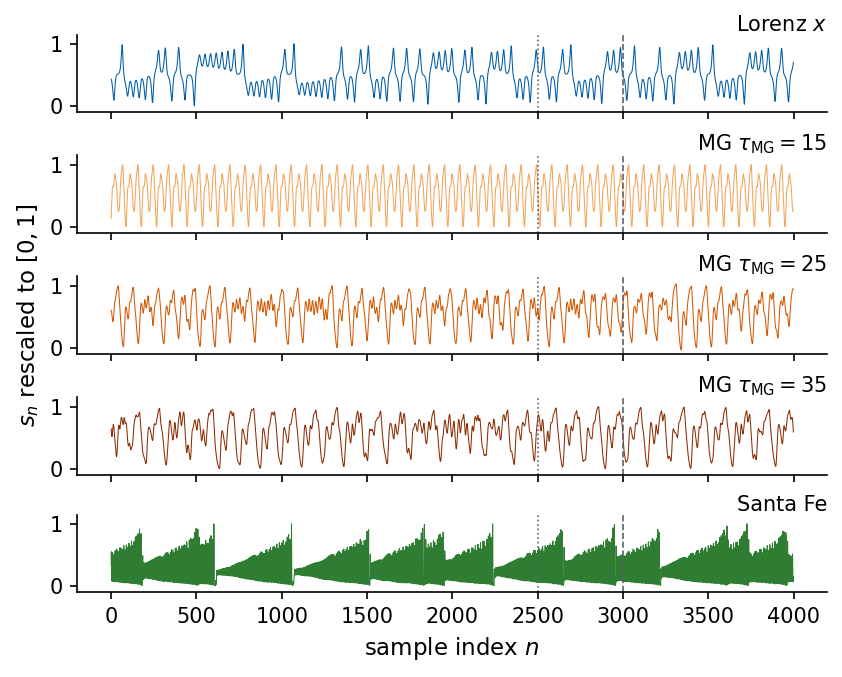

,sampling interval,record length (time),Nyquist frequency,resolution 1/(N dt),unit
signal,,,,,
Lorenz $x$,0.02,80.0,25.0,0.01250,time unit
MG $\tau_{\rm MG}=15$,1.00,4000.0,0.5,0.00025,time unit
MG $\tau_{\rm MG}=25$,1.00,4000.0,0.5,0.00025,time unit
MG $\tau_{\rm MG}=35$,1.00,4000.0,0.5,0.00025,time unit
Santa Fe,1.00,4000.0,0.5,0.00025,sample


In [15]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(5, 1, figsize=(5.5, 4.4), sharex=True, layout="constrained")
    for ax, k in zip(axs, KEYS):
        ax.plot(np.arange(N_SAMPLES), rescale01(S[k]), color=COL[k], lw=0.5)
        ax.axvline(N_TRAIN - N_VAL, color=UJGray, lw=0.8, ls=":"); ax.axvline(N_TRAIN, color=UJGray, lw=0.8, ls="--")
        ax.set_yticks([0, 1]); ax.set_ylim(-0.1, 1.15)
        ax.text(1.0, 1.0, LABEL[k], transform=ax.transAxes, ha="right", va="bottom", fontsize=10)
    axs[2].set_ylabel(r"$s_n$ rescaled to $[0,1]$")
    axs[-1].set_xlabel("sample index $n$")
    save(fig, "fig_signals_overview"); plt.show()

rows = []
for k in KEYS:
    dt = DT[k]
    rows.append({"signal": LABEL[k], "sampling interval": dt, "record length (time)": N_SAMPLES * dt,
                 "Nyquist frequency": 1 / (2 * dt), "resolution 1/(N dt)": 1 / (N_SAMPLES * dt), "unit": UNIT[k]})
display(pd.DataFrame(rows).set_index("signal"))

<hr/>
## 4. Autocorrelation function

All linear statistics assume that the signal is **stationary**, which means that its statistical properties do not depend on the origin of time. The mean $\mu=\langle s(t)\rangle$ is constant and the autocovariance
$$
R(\tau)=\big\langle\,(s(t)-\mu)\,(s(t+\tau)-\mu)\,\big\rangle
$$
depends only on the lag $\tau$, with $R(-\tau)=R(\tau)$. The brackets denote an average over an ensemble of realisations of the process. The autocorrelation function (ACF) is the normalised autocovariance $\rho(\tau)=R(\tau)/R(0)$, with $\rho(0)=1$ and $|\rho(\tau)|\le1$.

From one record of $N$ samples we can only form time averages. The standard estimator at lag $k$ (in samples) is
$$
\hat\rho(k)=\frac{\sum_{n=1}^{N-k}(s_n-\bar s)(s_{n+k}-\bar s)}{\sum_{n=1}^{N}(s_n-\bar s)^2},\qquad \bar s=\frac1N\sum_{n=1}^N s_n .
$$
Replacing the ensemble average by a time average assumes ergodicity, that one long record visits all states with their ensemble weights. Our signals are stationary after the discarded transients, and the Santa Fe record is treated as stationary although its slow build-up cycles make 4000 samples a short record. The numerator divides by $N$ and runs over $N-k$ terms, so $\hat\rho$ is biased towards zero at large $k$. In return it is a positive-definite sequence, which makes it the Fourier partner of the periodogram in Section 5.

Our JAX implementation computes all lags at once with `jax.vmap`, and we compare it with `statsmodels.tsa.stattools.acf` with the same normalisation (`adjusted=False`).

In [16]:
@partial(jax.jit, static_argnums=1)
def acf_jax(x, max_lag):
    """rho_hat(k) = sum_{n<N-k} (x_n - xbar)(x_{n+k} - xbar) / sum_n (x_n - xbar)^2,  k = 0..max_lag."""
    x = x - x.mean()
    N = x.shape[0]
    n = jnp.arange(N)
    def num(k):
        # x_n x_{n+k}, with the wrapped-around terms (n >= N-k) masked out
        return jnp.sum(jnp.where(n < N - k, x * jnp.roll(x, -k), 0.0))
    return jax.vmap(num)(jnp.arange(max_lag + 1)) / jnp.dot(x, x)

MAX_LAG = 400
RHO = {k: np.asarray(acf_jax(jnp.asarray(S[k]), MAX_LAG)) for k in KEYS}
for k in KEYS:
    ref = sm_acf(S[k], nlags=MAX_LAG, adjusted=False, fft=False)
    print(f"{LABEL[k]:22s} max |rho_JAX - rho_statsmodels| = {np.abs(RHO[k] - ref).max():.2e}")
    assert np.abs(RHO[k] - ref).max() < 1e-10

Lorenz $x$             max |rho_JAX - rho_statsmodels| = 2.22e-16
MG $\tau_{\rm MG}=15$  max |rho_JAX - rho_statsmodels| = 5.55e-16
MG $\tau_{\rm MG}=25$  max |rho_JAX - rho_statsmodels| = 3.33e-16
MG $\tau_{\rm MG}=35$  max |rho_JAX - rho_statsmodels| = 3.33e-16
Santa Fe               max |rho_JAX - rho_statsmodels| = 2.22e-16


Both implementations agree to machine precision. A single number for the memory of a signal, the correlation time, has several definitions that agree only for a simple exponential decay. We compute the first zero crossing of $\hat\rho$, the first lag at which $\hat\rho<1/e$, and, for oscillating ACFs, the first lag at which the envelope (the sequence of local maxima of $\hat\rho$) falls below $1/e$.

Lorenz $x$             first zero   89 samples =    1.78 time units | 1/e   15 samples =    0.30 time units | envelope 1/e   47 samples =    0.94 time units
MG $\tau_{\rm MG}=15$  first zero   11 samples =   11.00 time units | 1/e    9 samples =    9.00 time units | envelope 1/e none
MG $\tau_{\rm MG}=25$  first zero   18 samples =   18.00 time units | 1/e   12 samples =   12.00 time units | envelope 1/e   85 samples =   85.00 time units
MG $\tau_{\rm MG}=35$  first zero   24 samples =   24.00 time units | 1/e   15 samples =   15.00 time units | envelope 1/e  174 samples =  174.00 time units
Santa Fe               first zero    2 samples =    2.00 samples | 1/e    2 samples =    2.00 samples | envelope 1/e   30 samples =   30.00 samples


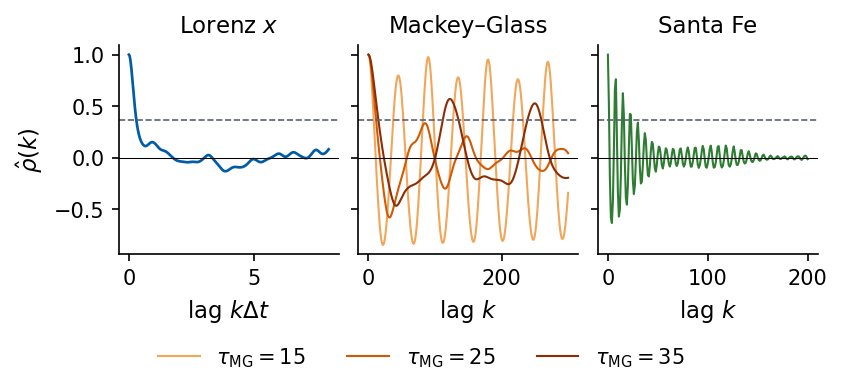

In [17]:
def correlation_times(rho):
    """First zero crossing, first drop below 1/e, and the lag where the envelope (the local maxima of rho)
    first falls below 1/e. All in samples; None if not reached within the computed lags."""
    zero = int(np.argmax(rho <= 0)) if np.any(rho <= 0) else None
    e1 = int(np.argmax(rho < np.exp(-1))) if np.any(rho < np.exp(-1)) else None
    pk, _ = scipy.signal.find_peaks(rho)
    below = pk[rho[pk] < np.exp(-1)]
    env = int(below[0]) if len(below) else None
    return zero, e1, env

CT = {}
for k in KEYS:
    CT[k] = correlation_times(RHO[k])
    z, e, env = CT[k]
    fmt = lambda v: "none" if v is None else f"{v:4d} samples = {v*DT[k]:7.2f} {UNIT[k]}s"
    print(f"{LABEL[k]:22s} first zero {fmt(z)} | 1/e {fmt(e)} | envelope 1/e {fmt(env)}")
nums["corr_times_samples"] = {k: list(CT[k]) for k in KEYS}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.5), layout="constrained", sharey=True)
    lags = np.arange(MAX_LAG + 1)
    axs[0].plot(lags * DT["lorenz"], RHO["lorenz"], color=COL["lorenz"])
    axs[0].set_xlabel(r"lag $k\Delta t$"); axs[0].set_title(LABEL["lorenz"])
    for k in ("mg15", "mg25", "mg35"):
        axs[1].plot(lags[:301], RHO[k][:301], color=COL[k], label=k[2:], lw=1.0)
    axs[1].set_xlabel("lag $k$"); axs[1].set_title("Mackey–Glass")
    axs[2].plot(lags[:201], RHO["santafe"][:201], color=COL["santafe"], lw=1.0)
    axs[2].set_xlabel("lag $k$"); axs[2].set_title(LABEL["santafe"])
    for ax in axs:
        ax.axhline(0, color="k", lw=0.5); ax.axhline(np.exp(-1), color=UJGray, lw=0.8, ls="--")
    axs[0].set_ylabel(r"$\hat\rho(k)$")
    h, l = axs[1].get_legend_handles_labels()
    fig.legend(h, [r"$\tau_{\rm MG}=$" + s for s in l], loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_acf_signals"); plt.show()

The three definitions measure different things. For Lorenz $x$, $\hat\rho$ drops below $1/e$ after 15 samples (0.30 time units) but crosses zero only after 89 samples (1.78 time units), because the sign of $x$, the lobe, is remembered much longer than the phase of the rotation around $C_\pm$. The Mackey–Glass ACF oscillates. For $\tau_{\rm MG}=15$ the oscillation does not decay at all (the envelope never falls below $1/e$), which is the signature of a periodic signal. For $\tau_{\rm MG}=25$ and 35 the envelope reaches $1/e$ after 85 and 174 samples, so the chaotic signals forget their phase slowly. The Santa Fe ACF oscillates with the pulsation period, crosses zero after 2 samples, and its envelope decays to $1/e$ after 30 samples. In each panel the dashed line marks $1/e$.

<hr/>
## 5. Power spectrum

### Discrete Fourier transform and periodogram

The ACF tells how long a signal remembers, and the power spectral density (PSD) tells at which frequencies its variance sits. For a stationary signal the two are a Fourier pair (Wiener–Khinchin theorem, see the textbook of H. Kantz and T. Schreiber, *Nonlinear Time Series Analysis*, 2nd ed., Cambridge University Press, 2003),
$$
S(f)=\int_{-\infty}^{\infty}R(\tau)\,e^{-2\pi i f\tau}\,d\tau,\qquad
R(\tau)=\int_{-\infty}^{\infty}S(f)\,e^{2\pi i f\tau}\,df ,
$$
and at $\tau=0$ the second relation states that the total power equals the variance, $\int S(f)\,df=R(0)$.

For $N$ samples at spacing $\Delta t$ the discrete Fourier transform (DFT) of the demeaned series is
$$
X_q=\sum_{n=0}^{N-1}(s_n-\bar s)\,e^{-2\pi i qn/N},\qquad f_q=\frac{q}{N\Delta t},\quad q=0,1,\dots,N-1 ,
$$
computed by the fast Fourier transform (FFT) in $O(N\log N)$ operations. The frequencies are spaced by the resolution $\Delta f=1/(N\Delta t)$, and only $|f_q|\le f_{\rm Ny}=1/(2\Delta t)$ is meaningful because $q$ and $q-N$ describe the same sampled oscillation. A component above $f_{\rm Ny}$ would appear at a wrong, lower frequency (aliasing). The periodogram
$$
\hat S(f_q)=\frac{\Delta t}{N}\,|X_q|^2
$$
estimates the two-sided density. Real signals have $X_{-q}=X_q^*$, so we keep $f_q\ge0$ and double all bins except $f=0$ and $f_{\rm Ny}$ (the one-sided PSD). With this normalisation Parseval's theorem gives the discrete sum rule $\sum_q\hat S(f_q)\,\Delta f=\frac1N\sum_n(s_n-\bar s)^2$, the variance of the record. The unit of $\hat S$ is (unit of $s$)$^2$ per unit of frequency, and frequencies are in cycles per time unit for Lorenz and Mackey–Glass and in cycles per sample for Santa Fe.

We implement the periodogram with `jnp.fft.rfft`, compare it with `scipy.signal.periodogram` and check the sum rule.

We first compute the spectrum of a signal whose content we know. Two sine waves with frequencies $f_1=0.05$ and $f_2=0.15$ per sample and amplitudes 1 and 0.5 are added, together with a little white noise. The periodogram of the sum has a sharp peak at each of the two frequencies, with heights in the ratio of the squared amplitudes, $1:0.25$, on top of a flat floor that comes from the noise. The spectrum takes the measured signal apart into the oscillations it contains and tells how much variance each one carries. The record has 2000 samples, so both frequencies lie on the grid $f_q=q/N$ of the discrete Fourier transform and no power leaks into neighbouring frequencies.

peak height ratio S(f2)/S(f1) = 0.238 (squared amplitude ratio 0.250)


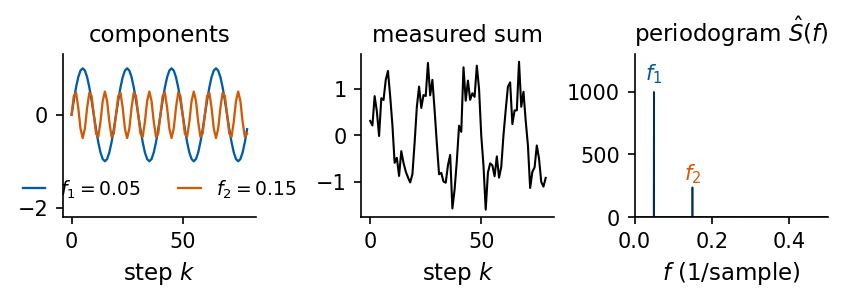

In [18]:
# sketch of the power spectrum: two sine components, their noisy sum, and the periodogram of the sum
N_SK, F1, F2, A1, A2 = 2000, 0.05, 0.15, 1.0, 0.5           # f * N integer: both lines fall on the frequency grid
k_sk = np.arange(N_SK)
comp1, comp2 = A1 * np.sin(2 * np.pi * F1 * k_sk), A2 * np.sin(2 * np.pi * F2 * k_sk)
s_sk = comp1 + comp2 + 0.3 * np.asarray(jax.random.normal(jax.random.key(7), (N_SK,)))
f_sk = np.fft.rfftfreq(N_SK, 1.0)[1:]
P_sk = (2.0 / N_SK) * np.abs(np.fft.rfft(s_sk - s_sk.mean()))[1:] ** 2      # one-sided periodogram, dt = 1
peak_ratio = P_sk[np.argmin(np.abs(f_sk - F2))] / P_sk[np.argmin(np.abs(f_sk - F1))]
print(f"peak height ratio S(f2)/S(f1) = {peak_ratio:.3f} (squared amplitude ratio {A2**2 / A1**2:.3f})")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 1.9), layout="constrained")
    show = slice(0, 80)
    axs[0].plot(k_sk[show], comp1[show], color=UJBlue, lw=1.1, label=f"$f_1={F1}$")
    axs[0].plot(k_sk[show], comp2[show], color=DSOrange, lw=1.1, label=f"$f_2={F2}$")
    axs[0].set_title("components"); axs[0].set_xlabel("step $k$")
    axs[0].legend(loc="lower center", ncol=2, fontsize=9, handlelength=1.2)
    axs[0].set_ylim(-2.2, 1.3)
    axs[1].plot(k_sk[show], s_sk[show], color="k", lw=1.0)
    axs[1].set_title("measured sum"); axs[1].set_xlabel("step $k$")
    axs[2].plot(f_sk, P_sk, color=UJNavy, lw=0.8)
    for f0, c, lab in ((F1, UJBlue, "$f_1$"), (F2, DSOrange, "$f_2$")):
        axs[2].text(f0, P_sk[np.argmin(np.abs(f_sk - f0))] * 1.05, lab, color=c, ha="center", va="bottom", fontsize=10)
    axs[2].set_ylim(0, P_sk.max() * 1.3)
    axs[2].set_title(r"periodogram $\hat S(f)$"); axs[2].set_xlabel("$f$ (1/sample)"); axs[2].set_xlim(0, 0.5)
    save(fig, "fig_psd_sketch"); plt.show()
nums["psd_sketch_peak_ratio"] = float(peak_ratio)


In [19]:
def periodogram_jax(x, dt):
    """One-sided periodogram. X_q = sum_n (x_n - xbar) e^{-2 pi i q n / N},  S_q = (dt/N) |X_q|^2 at f_q = q/(N dt),
    doubled for 0 < f_q < f_Nyquist so that sum_q S_q df = variance (df = 1/(N dt))."""
    x = jnp.asarray(x) - jnp.mean(x)
    N = x.shape[0]
    X = jnp.fft.rfft(x)                          # q = 0 .. N/2
    S2 = dt / N * jnp.abs(X) ** 2                # two-sided density at f_q >= 0
    w = jnp.ones_like(S2).at[1:].set(2.0)
    if N % 2 == 0:
        w = w.at[-1].set(1.0)                    # the Nyquist bin appears once
    return jnp.fft.rfftfreq(N, dt), w * S2

for k in KEYS:
    f, P = periodogram_jax(S[k], DT[k])
    f_sp, P_sp = scipy.signal.periodogram(S[k], fs=1 / DT[k], window="boxcar", detrend="constant", scaling="density")
    df = 1 / (N_SAMPLES * DT[k])
    print(f"{LABEL[k]:22s} max rel. diff to scipy {np.abs(P - P_sp).max() / P_sp.max():.1e} | "
          f"sum S df = {float(P.sum() * df):.6f}  variance = {S[k].var():.6f}")

Lorenz $x$             max rel. diff to scipy 2.8e-16 | sum S df = 62.379006  variance = 62.379006
MG $\tau_{\rm MG}=15$  max rel. diff to scipy 5.5e-18 | sum S df = 0.046802  variance = 0.046802
MG $\tau_{\rm MG}=25$  max rel. diff to scipy 2.0e-16 | sum S df = 0.065382  variance = 0.065382
MG $\tau_{\rm MG}=35$  max rel. diff to scipy 1.7e-16 | sum S df = 0.085611  variance = 0.085611
Santa Fe               max rel. diff to scipy 3.8e-16 | sum S df = 2376.225302  variance = 2376.225302


### Wiener–Khinchin theorem for the estimates

The theorem has a finite-$N$ counterpart that holds without approximation. With the biased autocovariance estimate $\hat R(k)=\frac1N\sum_{n}(s_n-\bar s)(s_{n+k}-\bar s)$ for $|k|<N$, the periodogram at every frequency equals
$$
\hat S(f)=\Delta t\sum_{k=-(N-1)}^{N-1}\hat R(k)\,e^{-2\pi i f k\Delta t}.
$$
We compute $\hat R$ through a zero-padded FFT, check it against its definition at a few lags, Fourier transform it, and compare with the periodogram on the grid $f_q$.

In [20]:
def autocov_biased(x):
    """R_hat(k) = (1/N) sum_{n<N-k} (x_n - xbar)(x_{n+k} - xbar) for k = 0..N-1 (via zero-padded FFT)."""
    x = jnp.asarray(x) - jnp.mean(x)
    N = x.shape[0]
    X = jnp.fft.fft(x, 2 * N)                    # zero padding to 2N removes the wrap-around
    return jnp.fft.ifft(jnp.abs(X) ** 2).real[:N] / N

for k in KEYS:
    x = S[k]; N = len(x); dt = DT[k]
    R = np.asarray(autocov_biased(x))
    # direct check of R_hat against the definition at a few lags
    xc = x - x.mean()
    assert all(abs(R[j] - np.dot(xc[:N - j], xc[j:]) / N) < 1e-9 * R[0] for j in (0, 1, 7, 100))
    # Fourier transform of R_hat over k = -(N-1)..N-1, evaluated on the grid f_q = q/(N dt)
    r_circ = np.concatenate([R, [0.0], R[:0:-1]])                 # length 2N, lags 0..N-1, (N), -(N-1)..-1
    S_wk = dt * np.fft.fft(r_circ).real[::2][: N // 2 + 1]       # every second bin = the N-point grid
    S_pg = dt / N * np.abs(np.fft.rfft(xc)) ** 2                  # two-sided periodogram
    print(f"{LABEL[k]:22s} max |S_WK - S_periodogram| / max S = {np.abs(S_wk - S_pg).max() / S_pg.max():.1e}")

Lorenz $x$             max |S_WK - S_periodogram| / max S = 2.8e-16
MG $\tau_{\rm MG}=15$  max |S_WK - S_periodogram| / max S = 1.8e-16
MG $\tau_{\rm MG}=25$  max |S_WK - S_periodogram| / max S = 3.9e-16
MG $\tau_{\rm MG}=35$  max |S_WK - S_periodogram| / max S = 2.6e-16
Santa Fe               max |S_WK - S_periodogram| / max S = 5.8e-16


The two sides agree to round-off for all five signals, so the ACF estimate and the periodogram carry the same information about the record.

### Spectral leakage and windows

The DFT treats the record as one period of an infinitely repeated signal. If a sinusoid does not complete an integer number of cycles in the record, the periodic continuation has a jump, and the jump spreads power over all frequencies (spectral leakage). Multiplying the data by a window $w_n$ that goes smoothly to zero at both ends removes the jump. The Hann window $w_n=\tfrac12-\tfrac12\cos(2\pi n/N)$ is the common choice, and the windowed periodogram is $\hat S(f_q)=\Delta t\,|\sum_n w_n(s_n-\bar s)e^{-2\pi iqn/N}|^2/\sum_n w_n^2$. The price is a wider main peak, and the frequency resolution decreases by about a factor of two. We compare the periodogram without window (rectangular) and with the Hann window for a sinusoid with 40.5 cycles in 512 samples (left panel, orange line at its frequency) and for the Mackey–Glass signal at $\tau_{\rm MG}=15$ (right panel), both normalised to the maximum.

rectangular  sinusoid: largest leakage at |f - f0| > 0.1 is 4.2e-05 of the peak
Hann         sinusoid: largest leakage at |f - f0| > 0.1 is 6.7e-12 of the peak


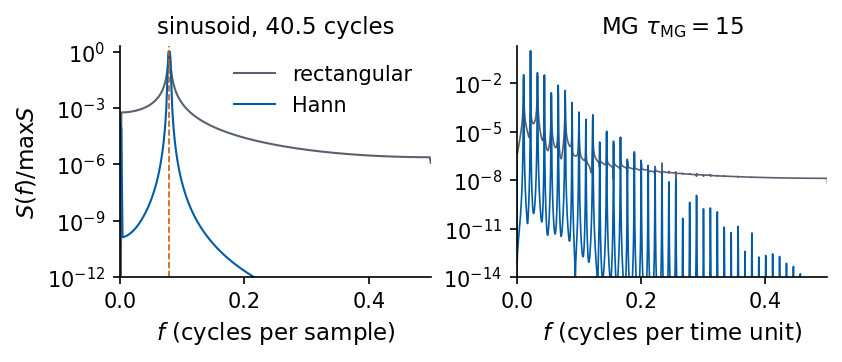

In [21]:
n_ = np.arange(512)
f0 = 40.5 / 512                                   # 40.5 cycles in the record: not on the frequency grid
sine = np.sin(2 * np.pi * f0 * n_)
win = {"rectangular": np.ones(512), "Hann": scipy.signal.windows.hann(512, sym=False)}

def windowed_periodogram(x, w, dt=1.0):
    """S_q = dt |sum_n w_n (x_n - xbar) e^{-2 pi i q n/N}|^2 / sum_n w_n^2  (one-sided, density)."""
    f, P = scipy.signal.periodogram(x, fs=1 / dt, window=w, detrend="constant", scaling="density")
    return f, P

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    for (name, w), c in zip(win.items(), (UJGray, UJBlue)):
        f, P = windowed_periodogram(sine, w)
        axs[0].semilogy(f, P / P.max(), color=c, lw=1.0, label=name)
        f, P = windowed_periodogram(S["mg15"], scipy.signal.windows.hann(N_SAMPLES, sym=False) if name == "Hann" else np.ones(N_SAMPLES))
        axs[1].semilogy(f, P / P.max(), color=c, lw=0.8, label=name)
    axs[0].axvline(f0, color=DSOrange, lw=0.8, ls="--")
    axs[0].set_xlim(0, 0.5); axs[0].set_ylim(1e-12, 2); axs[0].set_xlabel("$f$ (cycles per sample)")
    axs[0].set_ylabel(r"$S(f)/\max S$"); axs[0].set_title("sinusoid, 40.5 cycles"); axs[0].legend(loc="upper right")
    axs[1].set_xlim(0, 0.5); axs[1].set_ylim(1e-14, 2); axs[1].set_xlabel("$f$ (cycles per time unit)")
    axs[1].set_title(LABEL["mg15"])
    save(fig, "fig_leakage"); plt.show()
for name, w in win.items():
    f, P = windowed_periodogram(sine, w)
    far = np.abs(f - f0) > 0.1
    print(f"{name:12s} sinusoid: largest leakage at |f - f0| > 0.1 is {P[far].max() / P.max():.1e} of the peak")

Far from the peak, the rectangular window leaves a floor at $4\times10^{-5}$ of the peak, and the Hann window at $7\times10^{-12}$. For the periodic Mackey–Glass signal the floor of the rectangular window ($\sim10^{-8}$) hides all harmonics beyond the first few, while the Hann window reveals a comb of lines over more than ten decades.

### Variance of the periodogram and the Welch method

The periodogram has a large statistical scatter. At each frequency $\hat S(f_q)$ fluctuates around the true $S(f_q)$ with a standard deviation equal to its mean, for any record length, because a longer record gives more frequency bins with the same scatter. For Gaussian white noise $\hat S$ follows an exponential distribution, and we check this with $N=4000$ samples of unit variance, whose one-sided PSD is $S=2$. The Welch method trades resolution for variance. The record is cut into $K$ segments of length $L$ overlapping by $L/2$, each segment is demeaned and Hann-windowed, and the $K$ periodograms are averaged. The resolution becomes $1/(L\Delta t)$ and the relative scatter drops roughly as $1/\sqrt K$. We implement Welch in JAX, compare with `scipy.signal.welch`, and measure the scatter.

Lorenz $x$             segments 6, max rel. diff JAX vs scipy.signal.welch 4.6e-16
MG $\tau_{\rm MG}=15$  segments 6, max rel. diff JAX vs scipy.signal.welch 2.7e-16
MG $\tau_{\rm MG}=25$  segments 6, max rel. diff JAX vs scipy.signal.welch 2.6e-16
MG $\tau_{\rm MG}=35$  segments 6, max rel. diff JAX vs scipy.signal.welch 1.9e-16
Santa Fe               segments 6, max rel. diff JAX vs scipy.signal.welch 3.0e-16
white noise, raw periodogram : mean 1.982 (true 2), relative std 0.987
white noise, Welch L=1024    : mean 1.954 (true 2), relative std 0.451
white noise, Welch L=256     : mean 1.976 (true 2), relative std 0.190


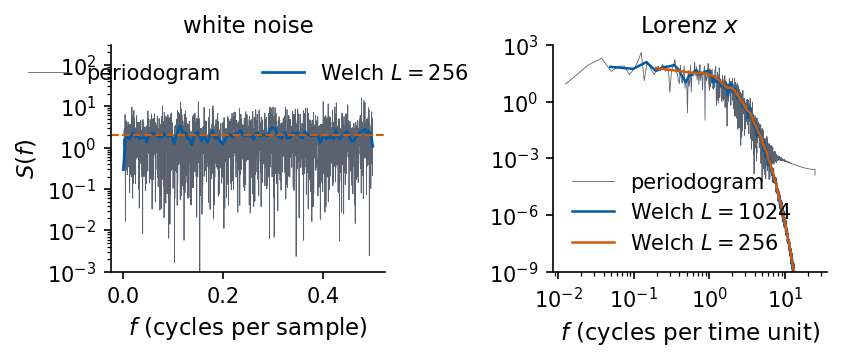

In [22]:
def welch_jax(x, dt, nperseg):
    """Welch estimate. Segments of length L = nperseg with 50% overlap, each demeaned and multiplied by the
    periodic Hann window w; S = average over segments of dt |sum_n w_n x_n e^{-2 pi i q n/L}|^2 / sum_n w_n^2."""
    x = jnp.asarray(x)
    step = nperseg // 2
    n_seg = (x.shape[0] - nperseg) // step + 1
    idx = jnp.arange(nperseg)[None, :] + step * jnp.arange(n_seg)[:, None]     # (n_seg, L) sample indices
    seg = x[idx]
    seg = seg - seg.mean(axis=1, keepdims=True)
    w = 0.5 - 0.5 * jnp.cos(2 * jnp.pi * jnp.arange(nperseg) / nperseg)        # periodic Hann window
    P = dt * jnp.abs(jnp.fft.rfft(seg * w, axis=1)) ** 2 / jnp.sum(w ** 2)
    P = P.mean(axis=0)
    P = P.at[1:-1].multiply(2.0) if nperseg % 2 == 0 else P.at[1:].multiply(2.0)  # one-sided
    return jnp.fft.rfftfreq(nperseg, dt), P, n_seg

for k in KEYS:
    f, P, nseg = welch_jax(S[k], DT[k], 1024)
    f_sp, P_sp = scipy.signal.welch(S[k], fs=1 / DT[k], window="hann", nperseg=1024, noverlap=512,
                                    detrend="constant", scaling="density")
    print(f"{LABEL[k]:22s} segments {nseg}, max rel. diff JAX vs scipy.signal.welch {np.abs(P - P_sp).max() / P_sp.max():.1e}")

# variance of the raw periodogram: white Gaussian noise, true one-sided density 2 sigma^2 dt = 2
noise = np.asarray(jax.random.normal(jax.random.key(0), (N_SAMPLES,)))
f_r, P_r = periodogram_jax(noise, 1.0); P_r = np.asarray(P_r)[1:-1]
stats = {"raw periodogram": P_r}
for L in (1024, 256):
    stats[f"Welch L={L}"] = np.asarray(welch_jax(noise, 1.0, L)[1])[1:-1]
for name, P in stats.items():
    print(f"white noise, {name:16s}: mean {P.mean():.3f} (true 2), relative std {P.std() / P.mean():.3f}")
nums["white_relstd"] = {name: float(P.std() / P.mean()) for name, P in stats.items()}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    axs[0].semilogy(f_r[1:-1], P_r, color=UJGray, lw=0.4, label="periodogram")
    fw, Pw, _ = welch_jax(noise, 1.0, 256)
    axs[0].semilogy(fw, Pw, color=UJBlue, lw=1.3, label="Welch $L=256$")
    axs[0].axhline(2.0, color=DSOrange, ls="--", lw=1.0)
    axs[0].set_xlabel("$f$ (cycles per sample)"); axs[0].set_ylabel("$S(f)$"); axs[0].set_title("white noise")
    axs[0].set_ylim(1e-3, 300); axs[0].legend(loc="upper center", ncol=2, fontsize=10)
    f, P = periodogram_jax(S["lorenz"], DT["lorenz"])
    axs[1].loglog(f[1:], P[1:], color=UJGray, lw=0.4, label="periodogram")
    for L, c in ((1024, UJBlue), (256, DSOrange)):
        fw, Pw, _ = welch_jax(S["lorenz"], DT["lorenz"], L)
        axs[1].loglog(fw[1:], Pw[1:], color=c, lw=1.2, label=f"Welch $L={L}$")
    axs[1].set_xlabel("$f$ (cycles per time unit)"); axs[1].set_title(LABEL["lorenz"]); axs[1].legend(fontsize=10, loc="lower left")
    axs[1].set_ylim(1e-9, 1e3)
    save(fig, "fig_welch"); plt.show()

For white noise the relative standard deviation is 0.987 for the raw periodogram, 0.451 for Welch with $L=1024$ (6 segments) and 0.190 for $L=256$. The same trade-off appears for Lorenz $x$ on logarithmic axes (right panel). The raw periodogram scatters by orders of magnitude between neighbouring bins, and its high-frequency tail flattens at about $10^{-4}$, the leakage floor of the rectangular window. The Welch estimates are smooth and follow the steep decay down to $10^{-9}$, and the shorter segments ($L=256$) give the smoother curve with the coarser frequency grid. We use the Welch estimate with $L=1024$, which resolves $1/1024$ cycles per sample.

### Spectra of the five signals

We look for peaks with `scipy.signal.find_peaks` on $\log_{10}\hat S$ and keep the peaks that stand out by more than one decade above their surroundings (prominence 1).

In [23]:
L_W = 1024
PSD = {k: tuple(np.asarray(a) for a in welch_jax(S[k], DT[k], L_W)[:2]) for k in KEYS}

def spectral_peaks(f, P, prominence=1.0, n_max=6):
    """Local maxima of log10 S standing out by more than `prominence` decades; the n_max highest."""
    idx, prop = scipy.signal.find_peaks(np.log10(P), prominence=prominence)
    idx = idx[np.argsort(P[idx])[::-1][:n_max]]
    return np.sort(idx)

rows = []
PEAKS = {}
for k in KEYS:
    f, P = PSD[k]
    pk = spectral_peaks(f[1:], P[1:]) + 1
    PEAKS[k] = pk
    for i in pk:
        rows.append({"signal": LABEL[k], "f (per " + UNIT[k] + ")": f[i], "period (" + UNIT[k] + "s)": 1 / f[i],
                     "period (samples)": 1 / (f[i] * DT[k]), "S(f)/S_max": P[i] / P.max()})
peak_table = pd.DataFrame(rows)
display(peak_table.round(4))
nums["psd_peaks"] = {k: [float(PSD[k][0][i]) for i in PEAKS[k]] for k in KEYS}

,signal,f (per time unit),period (time units),period (samples),S(f)/S_max,f (per sample)
0,MG $\tau_{\rm MG}=15$,0.0107,93.0909,93.0909,0.0392,NaN
1,MG $\tau_{\rm MG}=15$,0.0225,44.5217,44.5217,1.0000,NaN
2,MG $\tau_{\rm MG}=15$,0.0332,30.1176,30.1176,0.0601,NaN
3,MG $\tau_{\rm MG}=15$,0.0449,22.2609,22.2609,0.0263,NaN
4,MG $\tau_{\rm MG}=15$,0.0664,15.0588,15.0588,0.0064,NaN
5,MG $\tau_{\rm MG}=15$,0.0781,12.8000,12.8000,0.0043,NaN
6,MG $\tau_{\rm MG}=25$,0.0137,73.1429,73.1429,1.0000,NaN
7,MG $\tau_{\rm MG}=25$,0.0332,30.1176,30.1176,0.0661,NaN
8,MG $\tau_{\rm MG}=25$,0.0469,21.3333,21.3333,0.0739,NaN
9,MG $\tau_{\rm MG}=25$,0.0801,12.4878,12.4878,0.0016,NaN


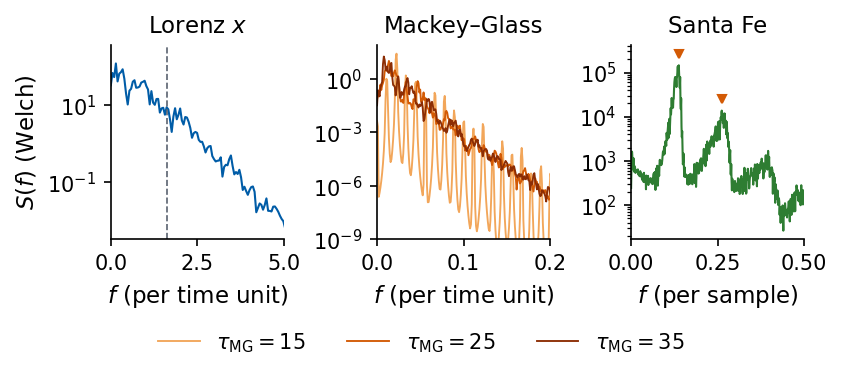

In [24]:
def ylim_visible(f, P, fmax, pad=3.0):
    v = P[(f > 0) & (f <= fmax)]
    return v.min() / pad, v.max() * pad
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.4), layout="constrained")
    f, P = PSD["lorenz"]
    axs[0].semilogy(f, P, color=COL["lorenz"], lw=1.0)
    axs[0].axvline(omega_c / (2 * np.pi), color=UJGray, ls="--", lw=0.8)
    axs[0].set_xlim(0, 5); axs[0].set_ylim(*ylim_visible(f, P, 5)); axs[0].set_xlabel("$f$ (per time unit)")
    axs[0].set_title(LABEL["lorenz"])
    lo, hi = np.inf, 0
    for k in ("mg15", "mg25", "mg35"):
        f, P = PSD[k]
        axs[1].semilogy(f, P, color=COL[k], lw=0.9, label=k[2:])
        a, b = ylim_visible(f, P, 0.2); lo, hi = min(lo, a), max(hi, b)
    axs[1].set_xlim(0, 0.2); axs[1].set_ylim(max(lo, 1e-9), hi); axs[1].set_xlabel("$f$ (per time unit)")
    axs[1].set_title("Mackey–Glass")
    f, P = PSD["santafe"]
    axs[2].semilogy(f, P, color=COL["santafe"], lw=1.0)
    axs[2].plot(f[PEAKS["santafe"]], P[PEAKS["santafe"]] * 1.8, "v", color=DSOrange, ms=4)
    axs[2].set_xlim(0, 0.5); axs[2].set_xlabel("$f$ (per sample)"); axs[2].set_title(LABEL["santafe"])
    axs[0].set_ylabel("$S(f)$ (Welch)")
    h, l = axs[1].get_legend_handles_labels()
    fig.legend(h, [r"$\tau_{\rm MG}=$" + s for s in l], loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_psd_signals"); plt.show()

The two statistics are two views of the same second-order structure, related by the Wiener–Khinchin theorem, and we plot them side by side. A peak of the autocorrelation at lag $k=P$ means that the signal resembles itself after $P$ samples, and the power spectrum shows the same repetition as a peak at $f=1/P$ and, for a non-sinusoidal shape, at its multiples. For the Santa Fe laser the autocorrelation returns near its maximum every 7 to 8 samples, and the spectrum has its main peak at $f\approx0.14$ per sample with a second one near $2f$. The flashes are sharp pulses, so their power is spread over the harmonics, and the irregular growth and collapse of the amplitude broadens every peak. The slow decay of the autocorrelation envelope and the width of the spectral peaks measure the same loss of memory.

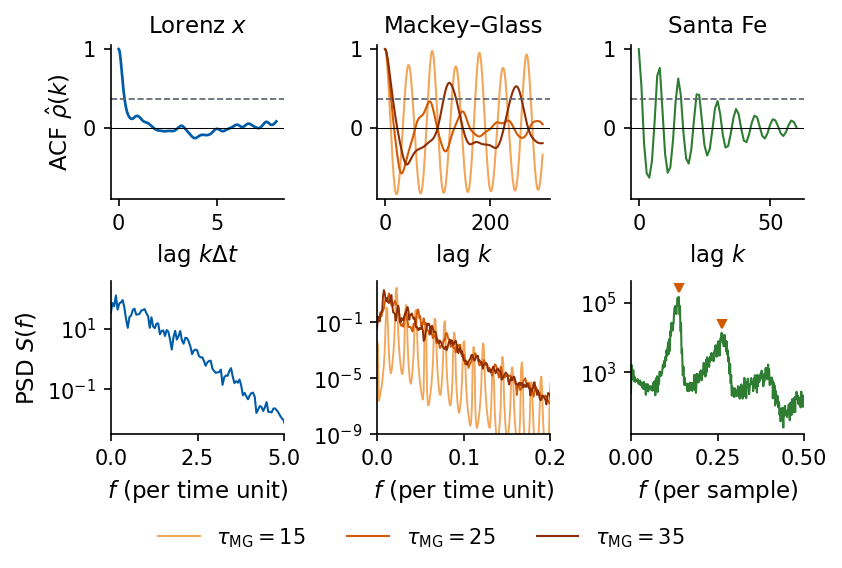

In [25]:
# slide figure: ACF (top row) and Welch PSD (bottom row) of the signals, drawn at slide size
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.7), layout="constrained")
    lags = np.arange(MAX_LAG + 1)
    axs[0, 0].plot(lags * DT["lorenz"], RHO["lorenz"], color=COL["lorenz"])
    axs[0, 0].set_xlabel(r"lag $k\Delta t$"); axs[0, 0].set_title(LABEL["lorenz"])
    for k in ("mg15", "mg25", "mg35"):
        axs[0, 1].plot(lags[:301], RHO[k][:301], color=COL[k], label=k[2:], lw=1.0)
    axs[0, 1].set_xlabel("lag $k$"); axs[0, 1].set_title("Mackey–Glass")
    axs[0, 2].plot(lags[:61], RHO["santafe"][:61], color=COL["santafe"], lw=1.0)
    axs[0, 2].set_xlabel("lag $k$"); axs[0, 2].set_title(LABEL["santafe"])
    for ax in axs[0]:
        ax.axhline(0, color="k", lw=0.5); ax.axhline(np.exp(-1), color=UJGray, lw=0.8, ls="--"); ax.set_ylim(-0.9, 1.05)
    axs[0, 0].set_ylabel(r"ACF $\hat\rho(k)$")
    f, P = PSD["lorenz"]
    axs[1, 0].semilogy(f, P, color=COL["lorenz"], lw=1.0)
    axs[1, 0].set_xlim(0, 5); axs[1, 0].set_ylim(*ylim_visible(f, P, 5)); axs[1, 0].set_xlabel("$f$ (per time unit)")
    lo, hi = np.inf, 0
    for k in ("mg15", "mg25", "mg35"):
        f, P = PSD[k]
        axs[1, 1].semilogy(f, P, color=COL[k], lw=0.9)
        a, b = ylim_visible(f, P, 0.2); lo, hi = min(lo, a), max(hi, b)
    axs[1, 1].set_xlim(0, 0.2); axs[1, 1].set_ylim(max(lo, 1e-9), hi); axs[1, 1].set_xlabel("$f$ (per time unit)")
    f, P = PSD["santafe"]
    axs[1, 2].semilogy(f, P, color=COL["santafe"], lw=1.0)
    axs[1, 2].plot(f[PEAKS["santafe"]], P[PEAKS["santafe"]] * 1.8, "v", color=DSOrange, ms=4)
    axs[1, 2].set_xlim(0, 0.5); axs[1, 2].set_xlabel("$f$ (per sample)")
    axs[1, 0].set_ylabel(r"PSD $S(f)$")
    h, l = axs[0, 1].get_legend_handles_labels()
    fig.legend(h, [r"$\tau_{\rm MG}=$" + s for s in l], loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_acf_psd_signals"); plt.show()


We plot the Welch PSD of each signal on a logarithmic scale. For Lorenz $x$ the dashed line marks the rotation frequency $1.62$ per time unit around $C_\pm$. To interpret the peaks of the Mackey–Glass and Santa Fe spectra we locate them on a finer frequency grid.

In [26]:
for k, tau in (("mg15", 15), ("mg25", 25), ("mg35", 35)):
    f, P = PSD[k]
    i_max = np.argmax(P[1:]) + 1
    print(f"{LABEL[k]:22s} highest Welch peak f = {f[i_max]:.5f} +- {0.5/L_W:.5f}, period {1/f[i_max]:6.1f} = {1/f[i_max]/tau:.2f} tau_MG")

# MG15: the maxima of x(t) take two values, so the orbit closes after two oscillations
x = S["mg15"]
pk, _ = scipy.signal.find_peaks(x)
print("MG15 heights of the maxima (rounded):", np.unique(np.round(x[pk], 3)))
mismatch = np.array([np.abs(x[T:] - x[:-T]).mean() for T in range(20, 121)])
T_best = 20 + int(np.argmin(mismatch))
print(f"MG15 shift T minimising <|x(t+T) - x(t)|> over T = 20..120: T = {T_best} (mismatch {mismatch.min():.4f});"
      f" at T = {T_best//2}: {np.abs(x[T_best//2:] - x[:-(T_best//2)]).mean():.4f}")
f, P = windowed_periodogram(x, scipy.signal.windows.hann(N_SAMPLES, sym=False))
i1 = np.argmax(P[(f > 0.005) & (f < 0.015)]) + np.argmax(f > 0.005)
i2 = np.argmax(P[1:]) + 1
print(f"MG15 full-record Hann periodogram: lowest line f = {f[i1]:.5f} (period {1/f[i1]:.1f}),"
      f" strongest line f = {f[i2]:.5f} (period {1/f[i2]:.2f} = {1/f[i2]/15:.3f} tau_MG), ratio {f[i2]/f[i1]:.3f}")
nums["mg15_period"] = float(1 / f[i1]); nums["mg15_strong_period"] = float(1 / f[i2])
# finer location of the dominant peak of the chaotic cases (full-record Hann periodogram, smoothed over 9 bins)
for k, tau in (("mg25", 25), ("mg35", 35)):
    f, P = windowed_periodogram(S[k], scipy.signal.windows.hann(N_SAMPLES, sym=False))
    Ps = np.convolve(P, np.ones(9) / 9, mode="same")
    band = (f > 0.004) & (f < 0.03)
    i = np.argmax(np.where(band, Ps, 0))
    print(f"{LABEL[k]:22s} smoothed full-record peak f = {f[i]:.5f}, period {1/f[i]:.1f} = {1/f[i]/tau:.2f} tau_MG")
    nums[f"{k}_peak_period"] = float(1 / f[i])
# Santa Fe: pulsation peak and the second peak
f, P = PSD["santafe"]
p1, p2 = f[PEAKS["santafe"][0]], f[PEAKS["santafe"][1]]
print(f"Santa Fe peaks f1 = {p1:.4f} (period {1/p1:.2f} samples), f2 = {p2:.4f}; f2/f1 = {p2/p1:.3f}")
nums["santafe_pulse_period"] = float(1 / p1); nums["santafe_f2_over_f1"] = float(p2 / p1)

MG $\tau_{\rm MG}=15$  highest Welch peak f = 0.02246 +- 0.00049, period   44.5 = 2.97 tau_MG
MG $\tau_{\rm MG}=25$  highest Welch peak f = 0.01367 +- 0.00049, period   73.1 = 2.93 tau_MG
MG $\tau_{\rm MG}=35$  highest Welch peak f = 0.00781 +- 0.00049, period  128.0 = 3.66 tau_MG
MG15 heights of the maxima (rounded): [1.006 1.167 1.168 1.281 1.282 1.283]
MG15 shift T minimising <|x(t+T) - x(t)|> over T = 20..120: T = 90 (mismatch 0.0040); at T = 45: 0.1201
MG15 full-record Hann periodogram: lowest line f = 0.01125 (period 88.9), strongest line f = 0.02225 (period 44.94 = 2.996 tau_MG), ratio 1.978
MG $\tau_{\rm MG}=25$  smoothed full-record peak f = 0.01375, period 72.7 = 2.91 tau_MG
MG $\tau_{\rm MG}=35$  smoothed full-record peak f = 0.00750, period 133.3 = 3.81 tau_MG
Santa Fe peaks f1 = 0.1377 (period 7.26 samples), f2 = 0.2617; f2/f1 = 1.901


The spectra fall into three types, which the time traces only suggest.

The Mackey–Glass signal at $\tau_{\rm MG}=15$ has a **line spectrum**. Its lowest line lies at $f_1=0.01125$ (period 88.9), and all other lines are integer multiples of it. The strongest line is the second harmonic $2f_1$ with period $44.94\approx3\tau_{\rm MG}$, and the maxima of $x(t)$ take two alternating heights, so the orbit closes after two oscillations of period close to $3\tau_{\rm MG}$. The shift $T=90$ maps the signal onto itself with mean mismatch 0.004 (the residue comes from the integer grid of shifts), while the shift $T=45$ leaves a mismatch of 0.12. This is a periodic orbit of twice the basic oscillation period.

For $\tau_{\rm MG}=25$ and 35 the lines merge into a **broadband** spectrum with broad peaks. The dominant peak of $\tau_{\rm MG}=25$ has period 72.7 $=2.91\,\tau_{\rm MG}$, close to the period of about $3\tau_{\rm MG}$ of the basic oscillation of the periodic signal at $\tau_{\rm MG}=15$. For $\tau_{\rm MG}=35$ the highest peak of our record lies at period 133.3 $=3.81\,\tau_{\rm MG}$ (128 in the Welch estimate, whose resolution is $\pm5\times10^{-4}$ in frequency), so the relation to $3\tau_{\rm MG}$ does not hold for this record at the resolution available.

The Lorenz spectrum is broadband without any line. The power is roughly flat up to about one cycle per time unit and decays steeply at higher frequencies, by about ten decades up to 12 cycles per time unit. The rotation around $C_\pm$ (dashed line) produces no peak, because its amplitude grows during each sequence of rotations and the irregular jumps between the lobes interrupt it. The jumps add power at low frequencies.

The Santa Fe spectrum has a sharp **pulsation peak** at $f_1=0.1377$ cycles per sample (period 7.26 samples) and a second peak at $f_2=0.2617$, slightly below $2f_1$ ($f_2/f_1=1.90$). A third broad hump lies near 0.4 cycles per sample. The rise of $\hat S$ towards $f=0$ comes from the slow build-up and collapse cycles, which last a few hundred samples.

<hr/>
## 6. Delay embedding

### Phase space from one coordinate

A harmonic oscillator has the state $(x,v)$, and we suppose that only the position $x(t)=\cos\omega t$ is measured. The finite difference $(x_k-x_{k-1})/\Delta t$ approximates the velocity, so the pair $(x_k,x_{k-\kappa})$ carries the same information as $(x,v)$. We plot the measured signal, the true phase portrait and the delay portrait with $\kappa=20$ samples, which is a deformed copy of the same closed curve. For Lorenz-63 the same works with derivatives up to second order. From $\dot x=\sigma(y-x)$ we get $y=x+\dot x/\sigma$, then $\dot y=\dot x+\ddot x/\sigma$ and from $\dot y=x(\rho-z)-y$ we get $z=\rho-(\dot y+y)/x$, so $(x,\dot x,\ddot x)$ determine $(x,y,z)$ wherever $x\neq0$. Delays approximate these derivatives and are less sensitive to noise. This observation is due to N. H. Packard, J. P. Crutchfield, J. D. Farmer and R. S. Shaw, Phys. Rev. Lett. **45**, 712 (1980), [doi:10.1103/PhysRevLett.45.712](https://doi.org/10.1103/PhysRevLett.45.712).

max |finite difference - v| = 0.025 (dt = 0.05)


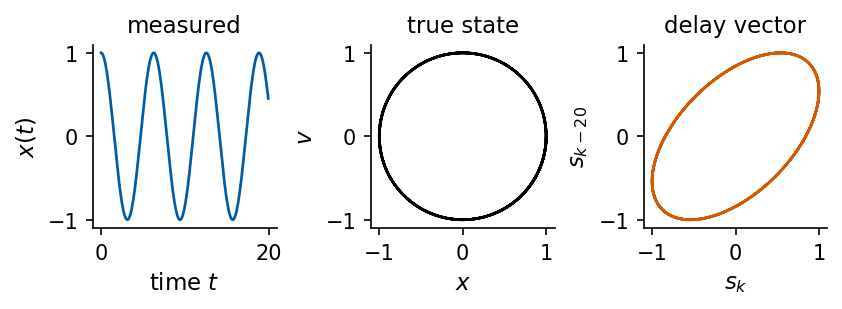

In [27]:
# harmonic oscillator x(t) = cos(omega t): the true phase portrait (x, v) and the delay portrait (x_k, x_{k-κ})
OMEGA, DT_OSC, L_OSC = 1.0, 0.05, 20                       # one period has 2 pi / (omega dt) = 126 samples; delay κ = 20 samples
t_osc = np.arange(400) * DT_OSC
x_osc, v_osc = np.cos(OMEGA * t_osc), -OMEGA * np.sin(OMEGA * t_osc)
v_fd = (x_osc[1:] - x_osc[:-1]) / DT_OSC                  # finite difference of the measured coordinate
print(f"max |finite difference - v| = {np.abs(v_fd - v_osc[1:]).max():.3f} (dt = {DT_OSC})")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 1.95), layout="constrained")
    axs[0].plot(t_osc, x_osc, color=UJBlue); axs[0].set_xlabel("time $t$"); axs[0].set_ylabel("$x(t)$")
    axs[0].set_title("measured")
    axs[1].plot(x_osc, v_osc, color="k"); axs[1].set_xlabel("$x$"); axs[1].set_ylabel("$v$"); axs[1].set_aspect("equal")
    axs[1].set_title("true state")
    axs[2].plot(x_osc[L_OSC:], x_osc[:-L_OSC], color=DSOrange); axs[2].set_xlabel("$s_k$"); axs[2].set_ylabel(f"$s_{{k-{L_OSC}}}$")
    axs[2].set_aspect("equal"); axs[2].set_title("delay vector")
    save(fig, "fig_delay_oscillator"); plt.show()

The same construction works for a chaotic flow. For Lorenz-63 we record only $x(t)$ and plot the delay vector $(x_k, x_{k-\kappa}, x_{k-2\kappa})$ with $\kappa=10$ samples, which is $0.2$ time units. The two lobes of the attractor reappear in a deformed but recognisable form. The delay $\kappa$ and the number of delays are chosen with the mutual information and with false nearest neighbours.

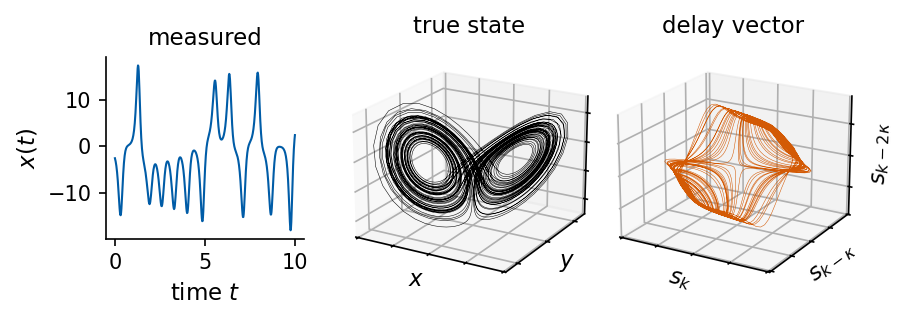

In [28]:
# Lorenz-63: measured x(t), the true state (x, y, z) and the delay vector (x_k, x_{k-κ}, x_{k-2κ})
L_LOR, N_SHOW = 10, 3000                                   # delay of 10 samples = 0.2 time units
x_l = S["lorenz"]
Y_lor = np.stack([x_l[2 * L_LOR:], x_l[L_LOR:-L_LOR], x_l[:-2 * L_LOR]], axis=1)
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.95))
    ax0 = fig.add_axes([0.08, 0.24, 0.24, 0.62])
    ax0.plot(np.arange(500) * DT["lorenz"], x_l[:500], color=UJBlue, lw=1.0)
    ax0.set_xlabel("time $t$"); ax0.set_ylabel("$x(t)$"); ax0.set_title("measured")
    for c, (Y, title, labs, col) in enumerate([(lor_states[:N_SHOW], "true state", ("$x$", "$y$", "$z$"), "k"),
                                               (Y_lor[:N_SHOW], "delay vector", ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$"), DSOrange)]):
        ax = fig.add_axes([0.36 + 0.32 * c, 0.0, 0.32, 0.95], projection="3d")
        ax.plot(*Y.T, lw=0.25, color=col)
        ax.set_title(title, pad=-4)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        for setter, lab in zip((ax.set_xlabel, ax.set_ylabel, ax.set_zlabel), labs):
            setter(lab, labelpad=-12)
        ax.view_init(elev=20, azim=-60)
    save(fig, "fig_delay_lorenz"); plt.show()


### Poincaré map

A continuous orbit can be reduced to a sequence of points. We choose a surface $\Sigma$ in phase space that the flow crosses transversally, a Poincaré section, and record the state at each crossing in one direction. The Poincaré map sends one crossing to the next,

$$P:\ \Sigma\to\Sigma,\qquad \mathbf x_{n+1}=P(\mathbf x_n).$$

A periodic orbit crosses $\Sigma$ at the same places again and again, so it appears as a finite set of points, a fixed point or a short cycle of $P$. A quasi-periodic orbit fills a closed curve, and a chaotic orbit gives infinitely many points that never repeat [H. Poincaré, *Les méthodes nouvelles de la mécanique céleste*, Gauthier-Villars (1892–1899); E. N. Lorenz, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020%3C0130:DNF%3E2.0.CO;2)].

For a measured signal a convenient section is $\dot s=0$ with $\ddot s<0$, the local maxima. The map of successive maxima $M_{n+1}$ against $M_n$ is the one Lorenz used for the maxima of $z$. Each maximum is located by a parabola through the largest sample and its two neighbours. We compute the map for Mackey–Glass at $\tau_{\rm MG}=15$ and $\tau_{\rm MG}=35$ and for the maxima of $z$ of Lorenz-63, each from a long run of the same equations.

MG $\tau_{\rm MG}=15$         1336 maxima, distinct values (rounded to 1e-3): 6
MG $\tau_{\rm MG}=35$         1247 maxima, distinct values (rounded to 1e-3): 511
Lorenz-63, maxima of $z$      1063 maxima, distinct values (rounded to 1e-3): 1009


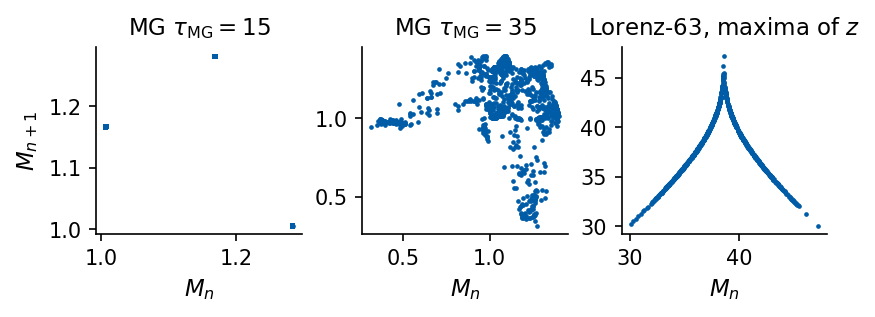

In [29]:
# Poincare map at the section ds/dt = 0, d2s/dt2 < 0: successive local maxima M_{n+1} against M_n
def local_maxima(x):
    """Values of the local maxima of a sampled signal, refined by a parabola through three samples."""
    k = np.flatnonzero((x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:])) + 1
    a, b, c = x[k - 1], x[k], x[k + 1]
    den = a - 2 * b + c
    return b - 0.125 * (c - a) ** 2 / np.where(den != 0, den, -1e-300)

N_POINC = 40000
poinc = {r"MG $\tau_{\rm MG}=15$": mackey_glass(15, N_POINC),
         r"MG $\tau_{\rm MG}=35$": mackey_glass(35, N_POINC),
         "Lorenz-63, maxima of $z$": np.asarray(lorenz_trajectory(N_POINC))[:, 2]}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.0), layout="constrained")
    for ax, (name, x) in zip(axs, poinc.items()):
        M = local_maxima(x)
        ax.plot(M[:-1], M[1:], ".", ms=2.5, color=UJBlue)
        ax.set_title(name); ax.set_xlabel("$M_n$")
        print(f"{name:28s} {len(M):5d} maxima, distinct values (rounded to 1e-3): {len(np.unique(np.round(M, 3)))}")
        nums.setdefault("poincare_maxima", {})[name] = int(len(M))
    axs[0].set_ylabel("$M_{n+1}$")
    save(fig, "fig_poincare_maxima"); plt.show()


The three maps separate the kinds of motion. For $\tau_{\rm MG}=15$ the 1336 maxima take only six distinct values after rounding to $10^{-3}$. The points of the map form a few tight clusters, and the orbit is periodic. For $\tau_{\rm MG}=35$ the 1247 maxima never repeat and spread over a two-dimensional region of the plane. Its attractor has the Kaplan–Yorke dimension 3.41 computed in Section 9, against 2.06 for Lorenz-63, so a single maximum does not fix the next one. The maxima of $z$ of Lorenz-63 also never repeat, but they lie on a thin cusp. The Lorenz attractor is strongly contracting, close to a surface, and the next maximum is almost a function of the previous one, a one-dimensional map with a slope steeper than 1 on both branches. This stretching is the origin of the positive Lyapunov exponent.

A single measured value does not fix the state of the system. We mark two moments at which the Lorenz signal has the same value, near $x=4.6$, once rising and once falling. The next values differ, although the measured value is the same, because the unmeasured coordinates $y$ and $z$ differ. To forecast $s_{k+1}$ we therefore need some past values, and we have to find how many of them, and at which spacing, fix the state.

x = 4.62 at k = 266 (next step +0.63) and x = 4.64 at k = 325 (next step -1.24)


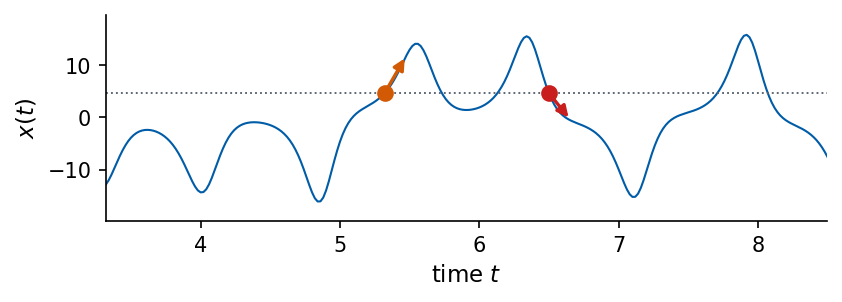

In [30]:
# one value does not fix the state: two moments of Lorenz x with the same value and opposite next steps
x_h = S["lorenz"][:1500]
dx = np.diff(x_h)
target = 5.0
near = np.flatnonzero(np.abs(x_h[:-1] - target) < 0.4)
ups, dns = near[dx[near] > 0], near[dx[near] < 0]
# a rising and a falling sample, close in time, whose values agree to within 0.1
pairs = [(i, j) for i in ups for j in dns if 0 < j - i < 60 and abs(x_h[i] - x_h[j]) < 0.1]
k_up, k_dn = pairs[0]
print(f"x = {x_h[k_up]:.2f} at k = {k_up} (next step +{dx[k_up]:.2f}) and x = {x_h[k_dn]:.2f} at k = {k_dn} (next step {dx[k_dn]:.2f})")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 1.9), layout="constrained")
    t_h = np.arange(len(x_h)) * DT["lorenz"]
    ax.plot(t_h, x_h, color=UJBlue, lw=1.0)
    ax.axhline(x_h[k_up], color=UJGray, ls=":", lw=0.9)
    for kk, c in ((k_up, DSOrange), (k_dn, "#C81E1E")):
        ax.plot(t_h[kk], x_h[kk], "o", color=c, ms=7, zorder=4)
        ax.annotate("", xy=(t_h[kk + 8], x_h[kk + 8]), xytext=(t_h[kk], x_h[kk]),
                    arrowprops=dict(arrowstyle="-|>", color=c, lw=1.6))
    ax.set_xlabel("time $t$"); ax.set_ylabel("$x(t)$")
    ax.set_xlim(t_h[min(k_up, k_dn)] - 2, t_h[max(k_up, k_dn)] + 2)
    save(fig, "fig_one_value_hook"); plt.show()


### Takens theorem

The spectra describe how the variance of a signal is distributed over frequencies. For a deterministic system we would like to see the state space itself, while we measure only one coordinate. Takens showed that this is possible [F. Takens, Lect. Notes Math. **898**, 366 (1981), [doi:10.1007/BFb0091924](https://doi.org/10.1007/BFb0091924)]. From the samples we form **delay vectors**
$$
\mathbf y_k=\big(s_k,\;s_{k-\kappa},\;s_{k-2\kappa},\;\dots,\;s_{k-(m-1)\kappa}\big)\in\mathbb R^m ,
$$
with delay $\kappa$ (in samples) and embedding dimension $m$. Let the dynamics take place on a smooth compact manifold of dimension $d$ and let the measured quantity be a smooth function of the state. Takens' theorem states that for a generic measurement function and a generic delay the map from the state to $\mathbf y_k$ is an embedding (one-to-one, smooth, with smooth inverse on its image) whenever $m\ge2d+1$. Sauer, Yorke and Casdagli extended the result to fractal attractors, where $m>2d_A$ suffices with $d_A$ the box-counting dimension of the attractor [T. Sauer, J. A. Yorke and M. Casdagli, J. Stat. Phys. **65**, 579 (1991), [doi:10.1007/BF01053745](https://doi.org/10.1007/BF01053745)]. The delay vectors therefore carry the full state of the system, and a forecasting model that receives $\mathbf y_k$ as input has all the information that the present state contains. Quantities that are invariant under smooth changes of coordinates, such as the Lyapunov exponents of Section 8, can be computed from the delay vectors.

The theorem leaves the choice of $\kappa$ and $m$ open. If $\kappa$ is too small, consecutive coordinates are almost equal and the vectors crowd near the diagonal. If $\kappa$ is too large in a chaotic signal, the coordinates become unrelated and the reconstructed attractor dissolves. We choose $\kappa$ from the mutual information and $m$ from false nearest neighbours.

The word embedding has a mathematical definition. A map $\mathcal E$ from the attractor into $\mathbb R^m$ is an embedding if different states go to different points and if nearby states go to nearby points and back. The image is then a faithful copy of the attractor, deformed smoothly but neither torn nor glued to itself. The simplest attractor shows how an embedding fails. A periodic signal lives on a closed curve, so $D=1$. In two delay coordinates the curve crosses itself. At the crossing two different states of the orbit share the same delay vector, and since their futures differ, no function of $(s_k,s_{k-\kappa})$ can forecast both. In three coordinates the two branches pass each other at a distance and the crossing is gone. Two pieces of dimension $D$ in $\mathbb R^m$ meet in general only if $D+D\ge m$, which is the origin of the condition $m>2D$.

self-crossings of the curve in m = 2: 1 | at states (samples) [(205, 294)]
state a = sample 205, state b = sample 294: distance in m = 2 0.013, in m = 3 1.819


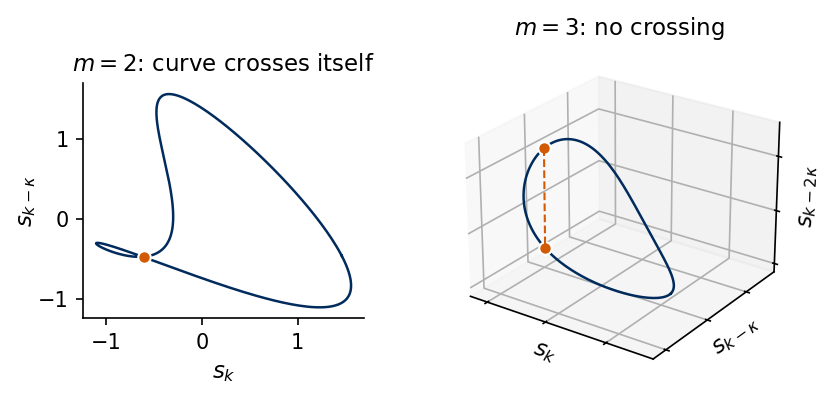

In [31]:
# a periodic signal (attractor = closed curve, D = 1) in delay coordinates m = 2 and m = 3
N_EMB, L_EMB = 400, 100                                     # samples per period, delay (a quarter period)
phase = 2 * np.pi * np.arange(N_EMB) / N_EMB                 # the state: one angle on the closed orbit
s_emb = np.cos(phase) + 0.6 * np.cos(2 * phase + 0.7)        # the measurement h of that state
y_emb = np.stack([s_emb, np.roll(s_emb, L_EMB), np.roll(s_emb, 2 * L_EMB)], axis=1)   # (s_k, s_{k-κ}, s_{k-2κ})

def self_crossings(P):
    """Pairs (i, j) of non-adjacent segments P_i P_{i+1} and P_j P_{j+1} of the closed curve P (n, 2) that cross."""
    A, B = P, np.roll(P, -1, axis=0)
    out = []
    for i in range(len(P)):
        for j in range(i + 2, len(P) - (i == 0)):
            d1, d2 = B[i] - A[i], B[j] - A[j]
            den = d1[0] * d2[1] - d1[1] * d2[0]
            if den == 0:
                continue
            r = A[j] - A[i]
            u, v = (r[0] * d2[1] - r[1] * d2[0]) / den, (r[0] * d1[1] - r[1] * d1[0]) / den
            if 0 <= u <= 1 and 0 <= v <= 1:
                out.append((i, j))
    return out

cross = self_crossings(y_emb[:, :2])
print("self-crossings of the curve in m = 2:", len(cross), "| at states (samples)", cross)
i_a, i_b = cross[0]
print(f"state a = sample {i_a}, state b = sample {i_b}: distance in m = 2 "
      f"{np.linalg.norm(y_emb[i_a, :2] - y_emb[i_b, :2]):.3f}, in m = 3 {np.linalg.norm(y_emb[i_a] - y_emb[i_b]):.3f}")
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.3))
    ax1 = fig.add_axes([0.10, 0.20, 0.34, 0.68])
    ax1.plot(*np.vstack([y_emb[:, :2], y_emb[:1, :2]]).T, color=UJNavy, lw=1.2)
    ax1.plot(*y_emb[i_a, :2], "o", color=DSOrange, ms=6, mec="white")
    ax1.set_xlabel("$s_k$"); ax1.set_ylabel(r"$s_{k-\kappa}$", labelpad=0)
    ax1.set_title("$m=2$: curve crosses itself")
    ax2 = fig.add_axes([0.52, 0.0, 0.46, 1.0], projection="3d")
    ax2.plot(*np.vstack([y_emb, y_emb[:1]]).T, color=UJNavy, lw=1.2)
    for i in (i_a, i_b):
        ax2.plot(*y_emb[i], "o", color=DSOrange, ms=6, mec="white")
    ax2.plot(*y_emb[[i_a, i_b]].T, color=DSOrange, ls="--", lw=1.0)
    ax2.set_title("$m=3$: no crossing", pad=-2)
    ax2.set_xticklabels([]); ax2.set_yticklabels([]); ax2.set_zticklabels([])
    for setter, lab in zip((ax2.set_xlabel, ax2.set_ylabel, ax2.set_zlabel), ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$")):
        setter(lab, labelpad=-12)
    ax2.view_init(elev=25, azim=-55)
    save(fig, "fig_embedding_crossing"); plt.show()


### Delay from the mutual information

A simple choice of $\kappa$ is the first zero of the ACF, at which neighbouring coordinates are linearly uncorrelated. Fraser and Swinney proposed a measure of general statistical dependence instead, the mutual information between $s_k$ and $s_{k-\kappa}$ [A. M. Fraser and H. L. Swinney, Phys. Rev. A **33**, 1134 (1986), [doi:10.1103/PhysRevA.33.1134](https://doi.org/10.1103/PhysRevA.33.1134)]. We divide the range of $s$ into 16 equal bins, estimate the probability $p_i$ of bin $i$ and the joint probability $p_{ij}(\kappa)$ that $s_{k-\kappa}$ falls in bin $i$ and $s_k$ in bin $j$, and compute
$$
\mathrm{MI}(\kappa)=\sum_{i,j}p_{ij}(\kappa)\,\ln\frac{p_{ij}(\kappa)}{p_i\,p_j}\quad\text{(in nats)} .
$$
$\mathrm{MI}(\kappa)\ge0$, and $\mathrm{MI}(\kappa)=0$ only for independent variables. The delay is the first local minimum of $\mathrm{MI}(\kappa)$, where the new coordinate adds the most new information while it is still dynamically related to the old one. Our JAX function builds all joint histograms with one `vmap` over the lags, using the same $N-\kappa_{\max}$ pairs for every lag.

In [32]:
@partial(jax.jit, static_argnums=(1, 2))
def mutual_information(x, max_lag, bins=16):
    """MI(κ) = sum_ij p_ij(κ) ln[p_ij(κ) / (p_i p_j)] for κ = 0..max_lag, from a bins x bins histogram of the
    pairs (x_n, x_{n+κ}), n = 0..N-max_lag-1 (the same pairs count for every lag)."""
    lo, hi = x.min(), x.max()
    s = jnp.clip(((x - lo) / (hi - lo) * bins).astype(jnp.int32), 0, bins - 1)     # bin index of each sample
    n = x.shape[0] - max_lag
    def mi(lag):
        a = jax.lax.dynamic_slice(s, (0,), (n,))
        b = jax.lax.dynamic_slice(s, (lag,), (n,))
        p = jnp.zeros((bins, bins)).at[a, b].add(1.0) / n                         # joint histogram p_ij
        pa, pb = p.sum(1, keepdims=True), p.sum(0, keepdims=True)                  # marginals p_i, p_j
        safe = jnp.where(p > 0, p, 1.0)
        return jnp.sum(jnp.where(p > 0, p * jnp.log(safe / (pa * pb)), 0.0))
    return jax.vmap(mi)(jnp.arange(max_lag + 1))

def first_local_min(c):
    for j in range(1, len(c) - 1):
        if c[j] < c[j - 1] and c[j] <= c[j + 1]:
            return j
    return None

MI = {k: np.asarray(mutual_information(jnp.asarray(S[k]), 100)) for k in KEYS}
LAG = {}
for k in KEYS:
    LAG[k] = first_local_min(MI[k])
    print(f"{LABEL[k]:22s} first MI minimum at κ = {LAG[k]:3d} samples ({LAG[k]*DT[k]:.2f} {UNIT[k]}s) | "
          f"first ACF zero at {CT[k][0]} samples | MI(0) = {MI[k][0]:.3f} nats, MI(κ*) = {MI[k][LAG[k]]:.3f} nats")

Lorenz $x$             first MI minimum at κ =  10 samples (0.20 time units) | first ACF zero at 89 samples | MI(0) = 2.621 nats, MI(κ*) = 0.788 nats
MG $\tau_{\rm MG}=15$  first MI minimum at κ =   8 samples (8.00 time units) | first ACF zero at 11 samples | MI(0) = 2.663 nats, MI(κ*) = 0.943 nats
MG $\tau_{\rm MG}=25$  first MI minimum at κ =  16 samples (16.00 time units) | first ACF zero at 18 samples | MI(0) = 2.600 nats, MI(κ*) = 0.221 nats
MG $\tau_{\rm MG}=35$  first MI minimum at κ =  26 samples (26.00 time units) | first ACF zero at 24 samples | MI(0) = 2.675 nats, MI(κ*) = 0.230 nats
Santa Fe               first MI minimum at κ =   2 samples (2.00 samples) | first ACF zero at 2 samples | MI(0) = 2.261 nats, MI(κ*) = 0.190 nats


The two criteria agree for Mackey–Glass and Santa Fe within a few samples, and differ by a factor of nine for Lorenz $x$, where the first MI minimum is at $\kappa=10$ (0.20 time units) and the ACF zero at 89 samples. The ACF zero of Lorenz $x$ measures the memory of the lobe, which is far longer than the time over which the state changes appreciably within one rotation.

### Embedding dimension from false nearest neighbours

If $m$ is too small, the reconstruction folds the attractor onto itself, and points that are far apart on the attractor appear as neighbours. Kennel, Brown and Abarbanel detect this directly [M. B. Kennel, R. Brown and H. D. I. Abarbanel, Phys. Rev. A **45**, 3403 (1992), [doi:10.1103/PhysRevA.45.3403](https://doi.org/10.1103/PhysRevA.45.3403)]. For every delay vector $\mathbf y_i^{(m)}$ we find its nearest neighbour $\mathbf y_j^{(m)}$, excluding all $j$ with $|i-j|\le w$ (Theiler window, here $w=50$ samples), because points close in time are trivially close in space. The neighbour is **false** if the added coordinate separates the two points strongly,
$$
\frac{|s_{i-m\kappa}-s_{j-m\kappa}|}{\|\mathbf y_i^{(m)}-\mathbf y_j^{(m)}\|}>R_{\rm tol}=15,
$$
and Kennel et al. add an absolute test, $\|\mathbf y_i^{(m+1)}-\mathbf y_j^{(m+1)}\|/\sigma_s>A_{\rm tol}=2$, with $\sigma_s$ the standard deviation of the signal. The fraction of false neighbours is plotted against $m$, and it drops to a low level once the attractor is unfolded.

The neighbour search is a dense distance computation in JAX over batches of points, which we first check against the $k$-d tree of `scipy.spatial.cKDTree`.

In [33]:
def delay_embed(x, m, lag):
    """Rows y_n = (x_n, x_{n-κ}, ..., x_{n-(m-1)κ}) for n = (m-1)κ .. N-1; shape (N-(m-1)κ, m)."""
    n = len(x) - (m - 1) * lag
    return np.stack([x[(m - 1) * lag - j * lag:(m - 1) * lag - j * lag + n] for j in range(m)], axis=1)

@partial(jax.jit, static_argnums=2)
def nearest_neighbour(Y, w, batch=500):
    """For every row i of Y the index j of its nearest neighbour with |i - j| > w (Theiler window) and the distance."""
    n = Y.shape[0]
    idx = jnp.arange(n)
    def one(i):
        d2 = jnp.sum((Y - Y[i]) ** 2, axis=1)
        d2 = jnp.where(jnp.abs(idx - i) <= w, jnp.inf, d2)
        j = jnp.argmin(d2)
        return j, jnp.sqrt(d2[j])
    return jax.lax.map(one, idx, batch_size=batch)

# sanity check of the neighbour search against a k-d tree (scipy) without Theiler window
Ytest = delay_embed(S["lorenz"], 3, 10)
j_jax, d_jax = nearest_neighbour(jnp.asarray(Ytest), 0)
d_kd, j_kd = cKDTree(Ytest).query(Ytest, k=2)
print("nearest-neighbour distances JAX vs cKDTree, max difference:", float(np.abs(np.asarray(d_jax) - d_kd[:, 1]).max()))

def fnn_fractions(x, lag, m_max=10, w=50, r_tol=15.0, a_tol=2.0):
    """False-nearest-neighbour fractions for m = 1..m_max (Kennel et al.). Returns the ratio test alone and
    the ratio test OR the absolute test."""
    sig = x.std()
    ratio, both = [], []
    for m in range(1, m_max + 1):
        Y = delay_embed(x, m + 1, lag)               # first m columns: y_n^(m); last column: the added x_{n-mκ}
        j, r = (np.asarray(a) for a in nearest_neighbour(jnp.asarray(Y[:, :m]), w))
        extra = np.abs(Y[:, m] - Y[j, m])            # |x_{i-mκ} - x_{j-mκ}|
        test1 = extra > r_tol * r
        test2 = np.sqrt(r ** 2 + extra ** 2) / sig > a_tol
        ratio.append(test1.mean()); both.append((test1 | test2).mean())
    return np.array(ratio), np.array(both)

FNN = {k: fnn_fractions(S[k], LAG[k]) for k in KEYS}
FNN_THRESHOLD = 0.05
EMB_M = {k: int(np.argmax(FNN[k][0] < FNN_THRESHOLD)) + 1 for k in KEYS}
for k in KEYS:
    print(f"{LABEL[k]:22s} κ = {LAG[k]:3d}  ratio test {np.round(FNN[k][0], 3)}")
    print(f"{'':22s}          both tests {np.round(FNN[k][1], 3)}  -> m = {EMB_M[k]}")

nearest-neighbour distances JAX vs cKDTree, max difference: 2.220446049250313e-16
Lorenz $x$             κ =  10  ratio test [0.959 0.178 0.064 0.038 0.03  0.026 0.021 0.019 0.014 0.008]
                                both tests [0.959 0.178 0.064 0.04  0.033 0.032 0.036 0.04  0.038 0.041]  -> m = 4
MG $\tau_{\rm MG}=15$  κ =   8  ratio test [0.165 0.003 0.    0.    0.    0.    0.    0.    0.    0.   ]
                                both tests [0.165 0.003 0.    0.    0.    0.    0.    0.    0.    0.   ]  -> m = 2
MG $\tau_{\rm MG}=25$  κ =  16  ratio test [0.991 0.418 0.105 0.039 0.024 0.019 0.012 0.011 0.011 0.01 ]
                                both tests [0.991 0.418 0.107 0.049 0.044 0.046 0.049 0.055 0.057 0.058]  -> m = 4
MG $\tau_{\rm MG}=35$  κ =  26  ratio test [0.986 0.524 0.084 0.019 0.01  0.003 0.001 0.001 0.    0.   ]
                                both tests [0.986 0.524 0.099 0.05  0.046 0.049 0.046 0.049 0.049 0.055]  -> m = 4
Santa Fe               κ =   2  ratio 

The ratio test drops below 5% at $m=4$ for Lorenz, $\tau_{\rm MG}=25$ and $\tau_{\rm MG}=35$, at $m=2$ for the periodic $\tau_{\rm MG}=15$ (a closed curve needs two dimensions to avoid self-crossings) and at $m=3$ for Santa Fe. The absolute test has a weakness for short records, as the combined fraction stops decreasing at about 4% and even grows with $m$ for Lorenz and Mackey–Glass. The distance between nearest neighbours grows with $m$ because each added coordinate adds to it, and with $N=4000$ points a fixed fraction of the neighbours sits at distances above $2\sigma_s$. We therefore choose $m$ as the smallest dimension at which the ratio test falls below 5% and report the combined fractions for comparison. For Lorenz, $m=4$ is consistent with the Sauer–Yorke–Casdagli bound $m>2d_A\approx4.1$ only marginally, and $m=3$ already gives 6.4% false neighbours. For the noisy Santa Fe record the answer depends on the variant of the test, and in Section 8 we use both $m=3$ and $m=4$.

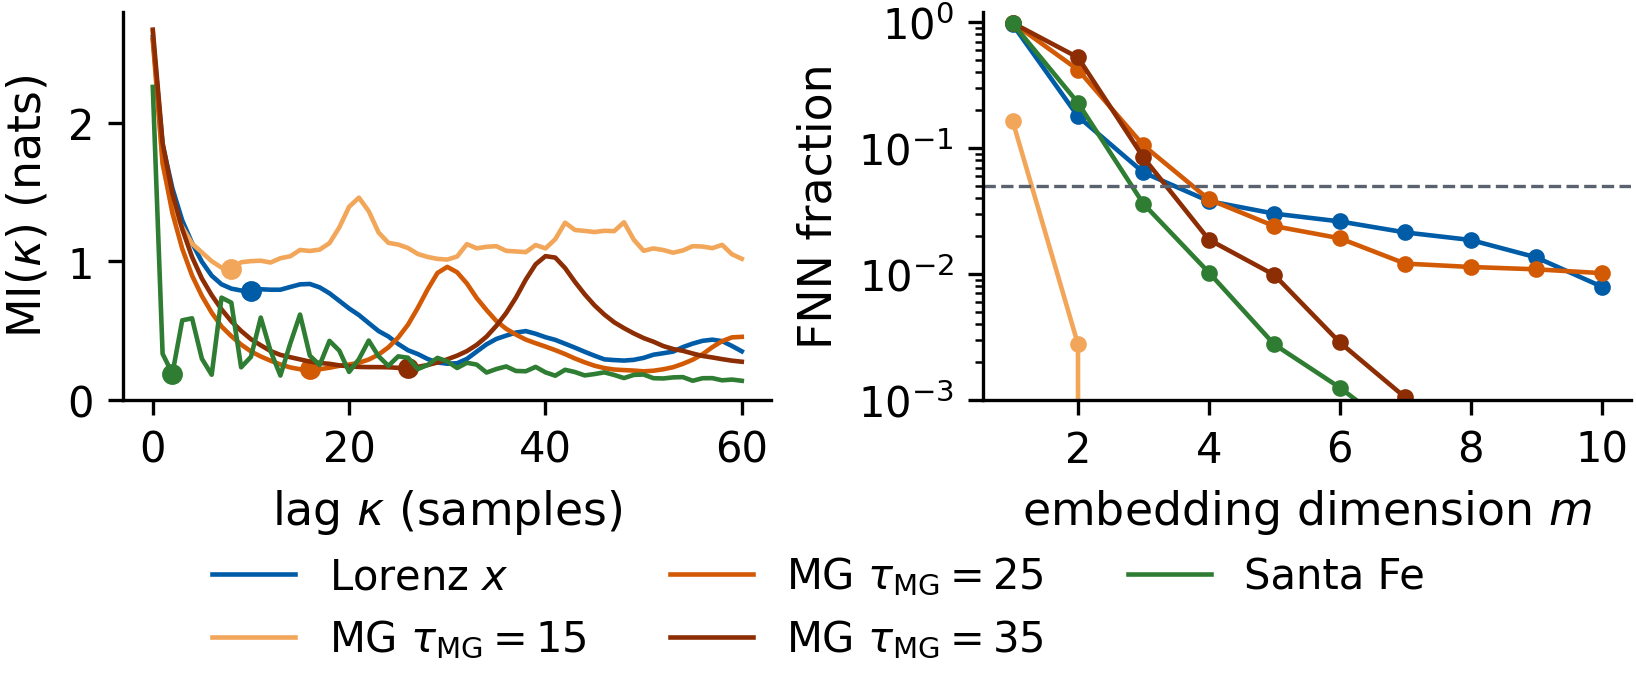

In [34]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    for k in KEYS:
        axs[0].plot(np.arange(61), MI[k][:61], color=COL[k], lw=1.1, label=LABEL[k])
        axs[0].plot(LAG[k], MI[k][LAG[k]], "o", color=COL[k], ms=4)
        axs[1].plot(np.arange(1, 11), FNN[k][0], "-o", color=COL[k], lw=1.1, ms=3)
    axs[0].set_xlabel(r"lag $\kappa$ (samples)"); axs[0].set_ylabel(r"$\mathrm{MI}(\kappa)$ (nats)"); axs[0].set_ylim(bottom=0)
    axs[1].axhline(FNN_THRESHOLD, color=UJGray, ls="--", lw=0.8)
    axs[1].set_yscale("log"); axs[1].set_ylim(1e-3, 1.2)
    axs[1].set_xlabel("embedding dimension $m$"); axs[1].set_ylabel("FNN fraction")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=10)
    save(fig, "fig_mi_fnn"); plt.show()

We plot $\mathrm{MI}(\kappa)$ with its first minimum marked by a dot (left panel) and the fraction of false neighbours of the ratio test against $m$ on a logarithmic scale, with the 5% threshold dashed (right panel).

### Lorenz attractor from one coordinate

We compare the true state $(x,y,z)$ with three-dimensional delay reconstructions from $x$ alone, with the MI delay $\kappa=10$ and with the ACF delay $\kappa=89$.

### Mutual information from a histogram

The mutual information is estimated from a two-dimensional histogram. The range of the signal is cut into 16 intervals of equal width. For a lag $\kappa$ we take every pair $(s_{k-\kappa},s_k)$ of the record, here $s_k=x(k\Delta t)$ of Lorenz-63, and count how many pairs fall into interval $i$ for the first value and interval $j$ for the second. Divided by the number of pairs, these counts are the joint probabilities $p_{ij}(\kappa)$, and the sums over one index give the probabilities $p_i$ and $p_j$ of a single value. If the two values were independent, the joint probability would factorise, $p_{ij}=p_i\,p_j$, and every logarithm in $\mathrm{MI}(\kappa)$ would vanish. We draw the histogram for Lorenz $x$ at a short lag, at the selected delay and at a long lag. The number of intervals is a choice. With about 4000 pairs, 16 intervals per value give $16\times16=256$ cells and about 16 pairs per cell on average, enough to estimate each $p_{ij}$, while many more cells would stay nearly empty.

lag  1: I from the histogram = 1.842 nats, from the JAX estimate = 1.845 nats
lag 10: I from the histogram = 0.786 nats, from the JAX estimate = 0.788 nats
lag 60: I from the histogram = 0.352 nats, from the JAX estimate = 0.351 nats


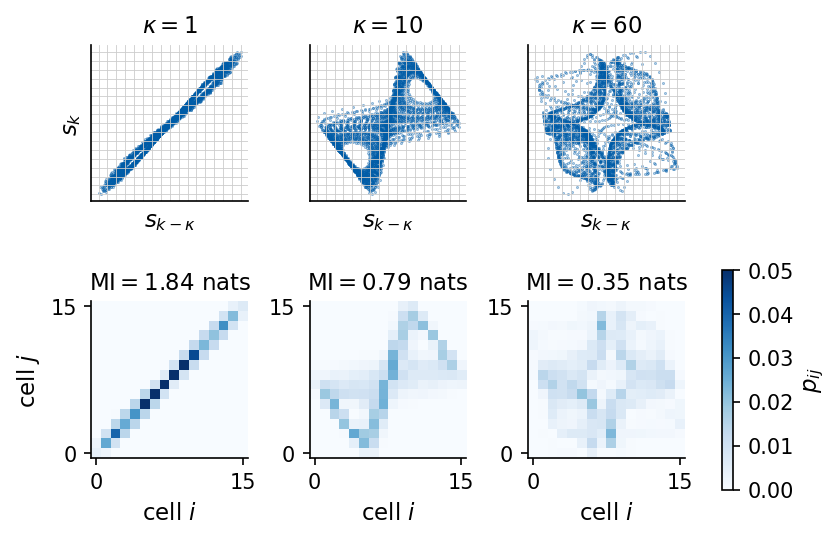

In [35]:
# joint histogram p_ij of the pairs (x_k, x_{k+κ}) of Lorenz x for three delays, and MI(κ) from it
def joint_hist(x, lag, bins=16):
    """p_ij of the pairs (x_k, x_{k+lag}) on a bins x bins grid over the range of x, and I = sum p ln p/(p_i p_j)."""
    edges = np.linspace(x.min(), x.max(), bins + 1)
    H, _, _ = np.histogram2d(x[:-lag], x[lag:], bins=[edges, edges])
    p = H / H.sum()
    pi, pj = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    return p, float(np.sum(p[nz] * np.log(p[nz] / (pi * pj)[nz]))), edges

x_l = S["lorenz"]
lags_demo = (1, LAG["lorenz"], 60)
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.6), layout="constrained")
    for col, lag in enumerate(lags_demo):
        p, I_np, edges = joint_hist(x_l, lag)
        ax = axs[0, col]                                   # top: the pairs and the grid of cells
        ax.plot(x_l[:-lag], x_l[lag:], ".", ms=0.8, color=UJBlue, alpha=0.5)
        for e in edges:
            ax.axvline(e, color="0.8", lw=0.4); ax.axhline(e, color="0.8", lw=0.4)
        ax.set_title(rf"$\kappa={lag}$"); ax.set_xlabel(r"$s_{k-\kappa}$"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_aspect("equal")
        ax = axs[1, col]                                   # bottom: fraction of pairs per cell
        im = ax.imshow(p.T, origin="lower", cmap="Blues", vmin=0, vmax=0.05)
        ax.set_title(rf"$\mathrm{{MI}}={I_np:.2f}$ nats"); ax.set_xlabel("cell $i$"); ax.set_xticks([0, 15]); ax.set_yticks([0, 15])
        print(f"lag {lag:2d}: I from the histogram = {I_np:.3f} nats, from the JAX estimate = {MI['lorenz'][lag]:.3f} nats")
        nums.setdefault("mi_demo_lorenz", {})[int(lag)] = I_np
    axs[0, 0].set_ylabel(r"$s_k$"); axs[1, 0].set_ylabel("cell $j$")
    fig.colorbar(im, ax=axs[1, :], shrink=0.9, label="$p_{ij}$")
    save(fig, "fig_mi_histogram"); plt.show()


The whole curve $\mathrm{MI}(\kappa)$ of Lorenz $x$ shows where the three histograms sit. The information shared by $s_{k-\kappa}$ and $s_k$ falls steeply over the first few samples and has its first minimum at $\kappa=10$. It rises again a little and then decays slowly towards zero, so a later lag can have a lower value, but there the coordinates no longer describe one rotation of the attractor.

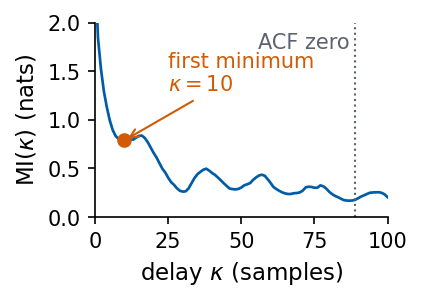

In [36]:
# MI(κ) of Lorenz x against the delay κ: first minimum, the three lags of the histograms, and the ACF zero
T_axis = np.arange(len(MI["lorenz"]))
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.7, 1.9), layout="constrained")
    ax.plot(T_axis, MI["lorenz"], color=UJBlue)
    ax.plot(LAG["lorenz"], MI["lorenz"][LAG["lorenz"]], "o", color=DSOrange, ms=6, zorder=3)
    ax.annotate(f"first minimum\n$\\kappa={LAG['lorenz']}$", (LAG["lorenz"], MI["lorenz"][LAG["lorenz"]]),
                xytext=(25, 1.3), fontsize=10, color=DSOrange, arrowprops=dict(arrowstyle="->", color=DSOrange))
    ax.axvline(CT["lorenz"][0], color=UJGray, ls=":", lw=1.0)
    ax.text(CT["lorenz"][0] - 2, 1.9, "ACF zero", ha="right", va="top", fontsize=10, color=UJGray)
    ax.set_xlabel(r"delay $\kappa$ (samples)"); ax.set_ylabel(r"$\mathrm{MI}(\kappa)$ (nats)")
    ax.set_xlim(0, 100); ax.set_ylim(0, 2.0)
    save(fig, "fig_mi_lorenz"); plt.show()


At $\kappa=1$ the pairs lie on the diagonal, because $x$ hardly changes in one sample, and knowing $x_k$ almost fixes $x_{k+1}$. At the selected delay the histogram has spread over a curved band, the pairs still depend on each other but each value adds new information. At $\kappa=60$ the histogram has spread further and $\mathrm{MI}$ has dropped to less than a fifth of its value at $\kappa=1$, although the two values are not yet independent. The two estimates of $\mathrm{MI}$ differ slightly because the JAX function uses the same number of pairs for every lag.

### False nearest neighbours

A delay plot is a projection of the attractor onto $m$ coordinates. If $m$ is too small, the projected orbit crosses itself, and two points from distant parts of the orbit appear next to each other. Adding one more delay coordinate separates them. Such a pair is called a pair of false nearest neighbours. For every point we find its nearest neighbour in $\mathbb R^m$, at distance $r$, and compute how much the added coordinate separates them. The neighbour is false if this extra distance exceeds 15 times $r$ or if the total distance exceeds twice the standard deviation of the signal [M. B. Kennel, R. Brown and H. D. I. Abarbanel, Phys. Rev. A **45**, 3403 (1992), [doi:10.1103/PhysRevA.45.3403](https://doi.org/10.1103/PhysRevA.45.3403)]. One such pair for Lorenz $x$ is close in the plane $(x_k,x_{k-\kappa})$ and far apart once $x_{k-2\kappa}$ is added.

pair 773, 459: distance in m = 2 is 0.20, in m = 3 it is 17.77 (ratio of the added coordinate 87)


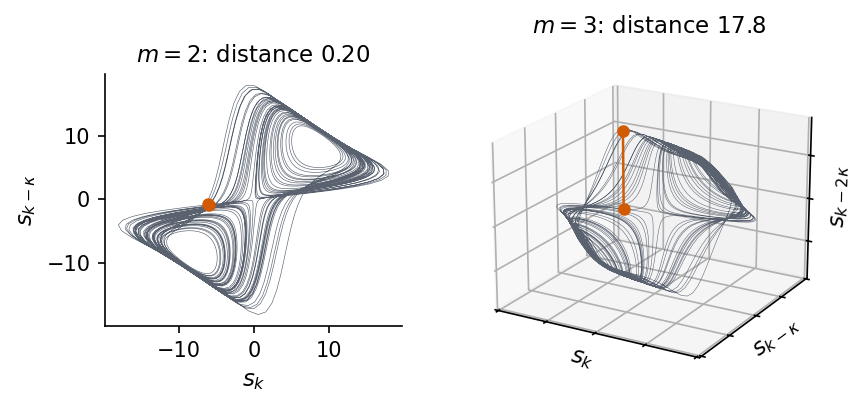

In [37]:
# one false nearest neighbour of Lorenz x: close in m = 2, far apart in m = 3
lag = LAG["lorenz"]
Y3 = delay_embed(x_l, 3, lag)                  # rows (x_n, x_{n-κ}, x_{n-2κ}), n = 2κ .. N-1
Y2 = Y3[:, :2]                                  # the same points in two coordinates
jn, rn = (np.asarray(a) for a in nearest_neighbour(jnp.asarray(Y2), 50))
extra = np.abs(Y3[:, 2] - Y3[jn, 2])
ratio = extra / np.maximum(rn, 1e-12)
a_pt = int(np.argmax(np.where(rn > 0.2, ratio, 0)))     # the most striking false neighbour with r > 0.2
b_pt = int(jn[a_pt])
print(f"pair {a_pt}, {b_pt}: distance in m = 2 is {rn[a_pt]:.2f}, in m = 3 it is "
      f"{np.linalg.norm(Y3[a_pt] - Y3[b_pt]):.2f} (ratio of the added coordinate {ratio[a_pt]:.0f})")
nums["fnn_demo"] = {"r2": float(rn[a_pt]), "r3": float(np.linalg.norm(Y3[a_pt] - Y3[b_pt]))}
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.4))
    ax = fig.add_axes([0.09, 0.2, 0.36, 0.7])
    ax.plot(Y2[:3000, 0], Y2[:3000, 1], color=UJGray, lw=0.3)
    ax.plot(*Y2[[a_pt, b_pt]].T, "o", color=DSOrange, ms=5)
    ax.set_xlabel("$s_k$"); ax.set_ylabel(r"$s_{k-\kappa}$"); ax.set_title(f"$m=2$: distance {rn[a_pt]:.2f}")
    ax3 = fig.add_axes([0.5, 0.0, 0.5, 1.0], projection="3d")
    ax3.plot(*Y3[:3000].T, color=UJGray, lw=0.25)
    ax3.plot(*Y3[[a_pt, b_pt]].T, "o-", color=DSOrange, ms=5, lw=1.2)
    ax3.set_title(f"$m=3$: distance {np.linalg.norm(Y3[a_pt] - Y3[b_pt]):.1f}", pad=-4)
    ax3.set_xticklabels([]); ax3.set_yticklabels([]); ax3.set_zticklabels([])
    for setter, lab in zip((ax3.set_xlabel, ax3.set_ylabel, ax3.set_zlabel), ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$")):
        setter(lab, labelpad=-12)
    ax3.view_init(elev=20, azim=-60)
    save(fig, "fig_fnn_demo"); plt.show()


The pair marked in orange is a typical false neighbour. In two coordinates the orbit passes through the same region from two different lobes, and the two points look close. The third coordinate shows that they belong to different parts of the attractor. Counting such pairs for every point gives the fraction of false neighbours, and the embedding dimension is the first $m$ at which it falls below 5 per cent.

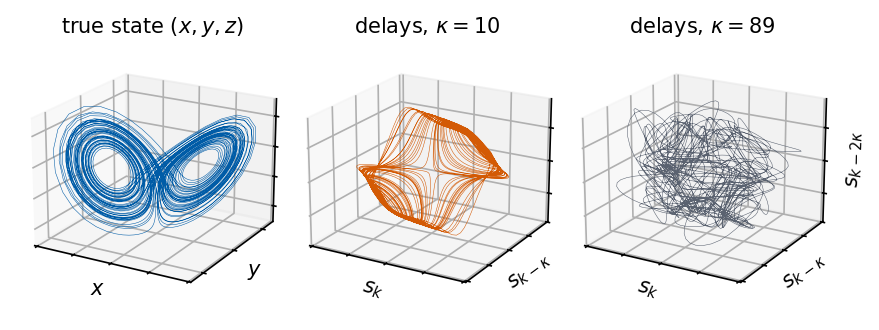

In [38]:
l_mi, l_acf = LAG["lorenz"], CT["lorenz"][0]
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.1))
    panels = [(lor_states[:, :3], "true state $(x, y, z)$", ("$x$", "$y$", "$z$")),
              (delay_embed(S["lorenz"], 3, l_mi), rf"delays, $\kappa={l_mi}$", ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$")),
              (delay_embed(S["lorenz"], 3, l_acf), rf"delays, $\kappa={l_acf}$", ("$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$"))]
    for c, (Y, title, labs) in enumerate(panels):
        ax = fig.add_axes([c / 3, 0.0, 1 / 3, 0.9], projection="3d")
        ax.plot(*Y[:3000].T, lw=0.25, color=UJBlue if c == 0 else DSOrange if c == 1 else UJGray)
        ax.set_title(title, fontsize=10, pad=-2)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        for setter, lab in zip((ax.set_xlabel, ax.set_ylabel, ax.set_zlabel), labs):
            setter(lab, labelpad=-12, fontsize=10)
        ax.view_init(elev=20, azim=-60)
    save(fig, "fig_takens_lorenz"); plt.show()

With $\kappa=10$ the two lobes and the switching between them are visible in a smoothly deformed image of the attractor. With $\kappa=89$ the three coordinates are almost unrelated within the chaotic motion and the reconstruction is a tangle in which the geometry is lost.

### Ratio test and absolute test

The ratio test of Kennel, Brown and Abarbanel compares the separation added by the next delay coordinate with the distance $r$ of the nearest neighbours. As the embedding dimension $m$ grows, $r$ grows too, because every coordinate adds to it, so the ratio becomes small for any record, also for a record without any deterministic law. The absolute test catches this case. A pair also counts as false if its distance in $m+1$ dimensions exceeds twice the standard deviation $\sigma_s$ of the record, so neighbours that are not close at all are counted as false. We compute both fractions for three records of 4000 samples, the x coordinate of Lorenz-63 sampled every 0.05 time units, the Mackey–Glass signal with $\tau_{\rm MG}=25$ sampled every time unit, and Gaussian white noise, which has no memory. Each record uses the delay at the first minimum of its mutual information and a Theiler window of 20 samples. The Mackey–Glass record is integrated here with the Euler method, so its numbers can differ slightly from those of the RK4 signals used in the other sections.

Lorenz x         kappa =  4   ratio test  [0.97  0.171 0.066 0.043 0.031 0.022 0.019 0.016]
                              both tests  [0.97  0.171 0.066 0.043 0.032 0.025 0.025 0.025]
Mackey-Glass 25  kappa = 17   ratio test  [0.988 0.332 0.048 0.007 0.002 0.003 0.002 0.002]
                              both tests  [0.988 0.332 0.05  0.007 0.005 0.005 0.005 0.008]
white noise      kappa =  2   ratio test  [0.992 0.705 0.201 0.022 0.002 0.001 0.    0.   ]
                              both tests  [0.992 0.71  0.248 0.174 0.178 0.198 0.222 0.275]


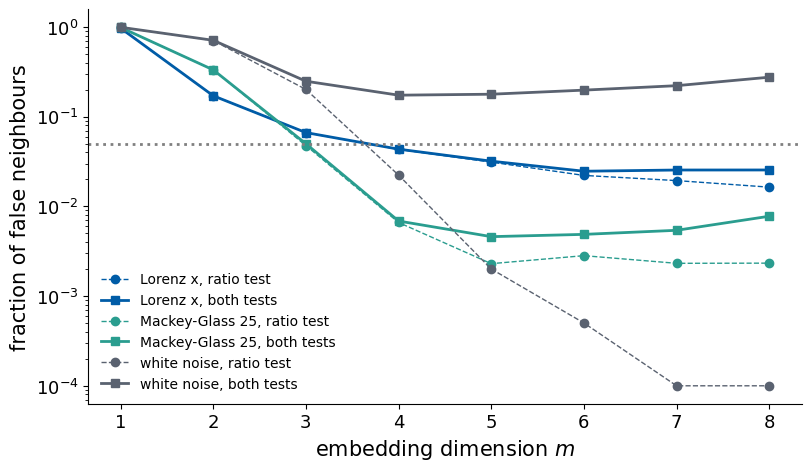

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

def mi_curve(x, max_lag, bins=16):
    edges = np.linspace(x.min(), x.max(), bins + 1)
    n = len(x) - max_lag
    out = []
    for lag in range(max_lag + 1):
        H, _, _ = np.histogram2d(x[:n], x[lag:lag + n], bins=[edges, edges])
        p = H / n
        pi, pj = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
        nz = p > 0
        out.append(np.sum(p[nz] * np.log(p[nz] / (pi * pj)[nz])))
    return np.array(out)

def first_min(c):
    for j in range(1, len(c) - 1):
        if c[j] < c[j - 1] and c[j] <= c[j + 1]:
            return j

def delay_rows(x, m, kappa):
    k0 = (m - 1) * kappa
    return np.stack([x[k0 - j * kappa:len(x) - j * kappa] for j in range(m)], axis=1)

def fnn_two_tests(x, kappa, m_max=8, w=20, r_tol=15.0, a_tol=2.0):
    # fraction of false neighbours with the ratio test, and with the ratio test or the absolute test
    sigma, ratio_only, both = x.std(), [], []
    for m in range(1, m_max + 1):
        Y = delay_rows(x, m + 1, kappa)
        Ym, nxt = Y[:, :m], Y[:, m]
        d, j = cKDTree(Ym).query(Ym, k=2 * w + 2)
        first = np.argmax(np.abs(j - np.arange(len(Ym))[:, None]) > w, axis=1)
        jj, r = j[np.arange(len(Ym)), first], d[np.arange(len(Ym)), first]
        ok = r > 0
        extra = np.abs(nxt[ok] - nxt[jj[ok]])
        t1 = extra / r[ok] > r_tol
        t2 = np.sqrt(r[ok] ** 2 + extra ** 2) / sigma > a_tol
        ratio_only.append(t1.mean()); both.append((t1 | t2).mean())
    return np.array(ratio_only), np.array(both)

def lorenz_x_record(n, every=5, h=0.01, n_discard=1000):
    F = lambda u: np.array([10.0 * (u[1] - u[0]), u[0] * (28.0 - u[2]) - u[1], u[0] * u[1] - 8.0 / 3.0 * u[2]])
    u, out = np.array([1.0, 1.0, 1.0]), np.empty(n + n_discard)
    for i in range((n + n_discard) * every):
        k1 = F(u); k2 = F(u + 0.5 * h * k1); k3 = F(u + 0.5 * h * k2); k4 = F(u + h * k3)
        u = u + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)
        if i % every == every - 1:
            out[i // every] = u[0]
    return out[n_discard:]

def mackey_glass_record(n, tau=25.0, h=0.1, every=10, n_discard=3000):
    d = int(round(tau / h))
    x = np.full(d + 1 + (n + n_discard) * every, 1.2)
    for i in range(d, len(x) - 1):
        x[i + 1] = x[i] + h * (0.2 * x[i - d] / (1 + x[i - d] ** 10) - 0.1 * x[i])
    return x[d + 1::every][n_discard:n_discard + n]

records = {"Lorenz x": lorenz_x_record(4000), "Mackey-Glass 25": mackey_glass_record(4000),
           "white noise": np.random.default_rng(3).standard_normal(4000)}
fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
for (name, x), col in zip(records.items(), ("#005CA7", "#2A9D8F", "#5A6270")):
    kap = first_min(mi_curve(x, 40)) or 1
    f_ratio, f_both = fnn_two_tests(x, kap)
    print(f"{name:16s} kappa = {kap:2d}   ratio test  {np.round(f_ratio, 3)}")
    print(f"{'':16s}              both tests  {np.round(f_both, 3)}")
    ax.semilogy(range(1, 9), np.maximum(f_ratio, 1e-4), "o--", color=col, lw=1, label=f"{name}, ratio test")
    ax.semilogy(range(1, 9), np.maximum(f_both, 1e-4), "s-", color=col, lw=2, label=f"{name}, both tests")
ax.axhline(0.05, color="0.5", ls=":")
ax.set_xlabel("embedding dimension $m$"); ax.set_ylabel("fraction of false neighbours"); ax.legend(fontsize=10)
plt.show()

With the ratio test alone all three records reach a fraction below 5% at $m=4$ and nearly zero at $m=8$, 0.016 for Lorenz $x$, 0.002 for Mackey–Glass and 0 for white noise, so the ratio test cannot tell the chaotic signals from noise. With both tests the two chaotic signals stay low, 0.025 for Lorenz and 0.008 for Mackey–Glass at $m=8$, while the fraction of the white noise stays at 0.174 at $m=4$ and grows to 0.275 at $m=8$. The nearest neighbours of a noise record remain far apart in every dimension, since every new coordinate brings a new random value. The ratio test chooses the embedding dimension, and the combined fraction distinguishes a record from a low-dimensional deterministic law from a stochastic one.

<hr/>
## 7. Deterministic chaos in one dimension

### Phase space, flow and dissipation

A deterministic system is defined by a state $\mathbf u$ in a phase space and a rule that maps the present state to the future one. For a flow the rule is a differential equation $\dot{\mathbf u}=\mathbf F(\mathbf u)$, and for a map it is $\mathbf u_{n+1}=\mathbf f(\mathbf u_n)$. A small volume $V$ of initial conditions changes under the flow at the rate $\dot V/V=\nabla\cdot\mathbf F$. For Lorenz-63 the divergence is constant, $\nabla\cdot\mathbf F=-(\sigma+1+\beta)=-13.667$, so every volume shrinks by the factor $e^{-13.667}$ per time unit. A system that contracts volumes is called dissipative. Its long-time motion lies on a set of zero volume, the attractor, which can still have a complicated, fractal structure. Chaos on such an attractor needs two ingredients, which the simplest example already shows.

### Logistic map

The logistic map [R. M. May, Nature **261**, 459 (1976), [doi:10.1038/261459a0](https://doi.org/10.1038/261459a0)]
$$
x_{n+1}=f(x_n)=r\,x_n(1-x_n),\qquad x_n\in[0,1],\ 0<r\le4,
$$
is a model of a population with limited resources. Two nearby initial conditions $x_0$ and $x_0+\delta_0$ separate after $n$ steps by $\delta_n\approx\delta_0\prod_{k<n}|f'(x_k)|$, by the chain rule. The Lyapunov exponent is the average logarithmic growth rate per step,
$$
\lambda=\lim_{N\to\infty}\frac1N\sum_{n=0}^{N-1}\ln|f'(x_n)|=\big\langle\ln|r(1-2x_n)|\big\rangle .
$$
$\lambda<0$ means that nearby orbits approach each other (a stable fixed point or cycle), $\lambda>0$ that they separate exponentially (chaos). For $r=4$ the substitution $x=\sin^2(\pi\theta)$ turns the map into $\theta_{n+1}=2\theta_n$ mod 1, which doubles every distance, so $\lambda=\ln2$. We iterate the map in JAX for 1201 values of $r$ at once with `vmap`, discard 1000 transient steps, keep 300 iterates for the bifurcation diagram and average $\ln|f'|$ over 20000 steps.

lambda(r=4) = 0.6931 (200000 iterates), ln 2 = 0.6931
first r on the grid with lambda > 1e-3: r = 3.570


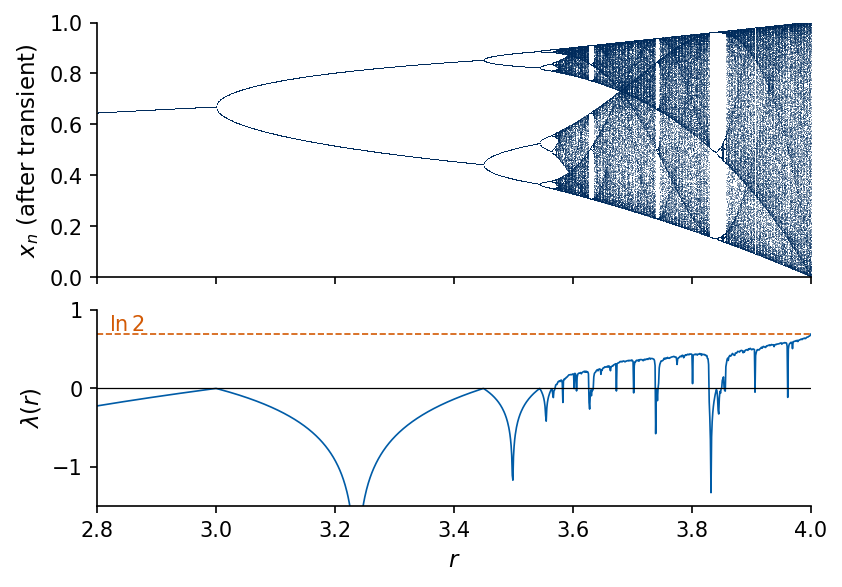

In [40]:
@partial(jax.jit, static_argnames=("n_transient", "n_keep", "n_lyap"))
def logistic_orbit_and_lyap(r, x0=0.3, n_transient=1000, n_keep=300, n_lyap=20000):
    """Iterate x_{n+1} = r x_n (1 - x_n). Returns the last n_keep iterates after the transient and
    lambda = (1/n_lyap) sum_n ln |f'(x_n)| = <ln |r (1 - 2 x_n)|> along the orbit."""
    f = lambda x: r * x * (1.0 - x)
    x = jax.lax.fori_loop(0, n_transient, lambda i, x: f(x), x0)
    def body(x, _):
        return f(x), (x, jnp.log(jnp.abs(r * (1.0 - 2.0 * x))))
    _, (orbit, logd) = jax.lax.scan(body, x, None, length=n_lyap)
    return orbit[-n_keep:], logd.mean()

r_grid = jnp.linspace(2.8, 4.0, 1201)
orbits, lyap_r = jax.vmap(lambda r: logistic_orbit_and_lyap(r))(r_grid)
orbits, lyap_r = np.asarray(orbits), np.asarray(lyap_r)
lam4 = float(logistic_orbit_and_lyap(4.0, n_lyap=200000)[1])
print(f"lambda(r=4) = {lam4:.4f} (200000 iterates), ln 2 = {np.log(2):.4f}")
r_onset = float(r_grid[np.argmax(lyap_r > 1e-3)])
print(f"first r on the grid with lambda > 1e-3: r = {r_onset:.3f}")
nums["logistic_lambda_r4"] = lam4; nums["logistic_r_onset"] = r_onset

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.8), sharex=True, layout="constrained",
                            gridspec_kw=dict(height_ratios=[1.3, 1]))
    rr = np.repeat(np.asarray(r_grid), orbits.shape[1])
    axs[0].plot(rr, orbits.ravel(), ",", color=UJNavy, alpha=0.4, rasterized=True)
    axs[0].set_ylabel("$x_n$ (after transient)"); axs[0].set_ylim(0, 1)
    axs[1].plot(np.asarray(r_grid), lyap_r, color=UJBlue, lw=0.8)
    axs[1].axhline(0, color="k", lw=0.6); axs[1].axhline(np.log(2), color=DSOrange, ls="--", lw=0.8)
    axs[1].text(2.82, np.log(2) + 0.05, r"$\ln 2$", color=DSOrange, fontsize=10)
    axs[1].set_ylim(-1.5, 1.0); axs[1].set_xlabel("$r$"); axs[1].set_ylabel(r"$\lambda(r)$"); axs[1].set_xlim(2.8, 4.0)
    save(fig, "fig_logistic_lyapunov"); plt.show()

The upper panel holds the bifurcation diagram, the set of values visited after the transient for each $r$. A single fixed point splits at $r=3$ into a cycle of period two, then four, and so on, and the cascade ends near $r\approx3.57$, beyond which the orbits fill whole intervals, interrupted by windows of periodic motion. The lower panel plots $\lambda(r)$ on the same $r$ axis. $\lambda$ touches zero at every period doubling, stays negative in the periodic windows, and is positive where the diagram is filled. The first grid point with $\lambda>10^{-3}$ is $r=3.570$, and at $r=4$ we obtain $\lambda=0.6931=\ln2$.

### Stretching and folding

At $r=4$ we follow two orbits that start $\delta_0=10^{-10}$ apart.

separation reaches 0.1 after n = 31 iterates; fitted growth rate 0.674 per iterate (ln 2 = 0.693); ln(0.1/d0)/ln 2 = 29.9


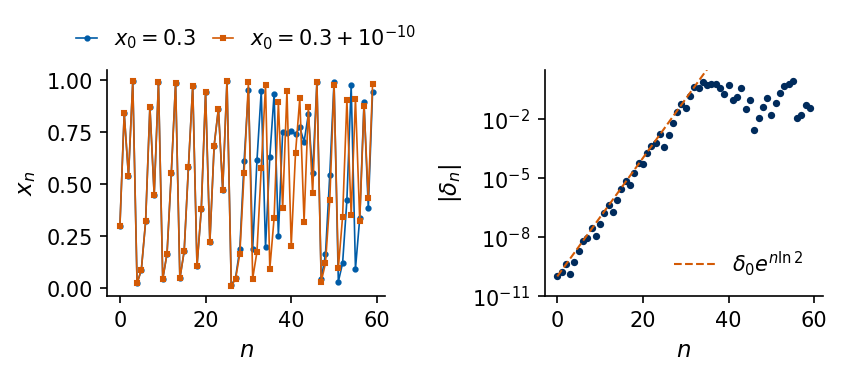

In [41]:
def logistic_orbit(x0, r=4.0, n=60):
    return np.asarray(jax.lax.scan(lambda x, _: (r * x * (1 - x), x), x0, None, length=n)[1])
d0 = 1e-10
a, b = logistic_orbit(0.3), logistic_orbit(0.3 + d0)
sep = np.abs(a - b)
n_sat = int(np.argmax(sep > 0.1))
slope = np.polyfit(np.arange(5, n_sat - 3), np.log(sep[5:n_sat - 3]), 1)[0]
print(f"separation reaches 0.1 after n = {n_sat} iterates; fitted growth rate {slope:.3f} per iterate (ln 2 = {np.log(2):.3f});"
      f" ln(0.1/d0)/ln 2 = {np.log(0.1 / d0) / np.log(2):.1f}")
nums["logistic_sep_n"] = n_sat
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    axs[0].plot(a, "-o", color=UJBlue, ms=2, lw=0.8, label="$x_0=0.3$")
    axs[0].plot(b, "-s", color=DSOrange, ms=2, lw=0.8, label="$x_0=0.3+10^{-10}$")
    axs[0].set_xlabel("$n$"); axs[0].set_ylabel("$x_n$"); axs[0].legend(fontsize=10, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 1.0), handlelength=1.0, columnspacing=0.8)
    n = np.arange(len(sep))
    axs[1].semilogy(n, sep, "o", color=UJNavy, ms=2.5)
    axs[1].semilogy(n, d0 * 2.0 ** n, "--", color=DSOrange, lw=1.0, label=r"$\delta_0 e^{n\ln 2}$")
    axs[1].set_ylim(1e-11, 3); axs[1].set_xlabel("$n$"); axs[1].set_ylabel(r"$|\delta_n|$"); axs[1].legend(fontsize=10)
    save(fig, "fig_logistic_separation"); plt.show()

The orbits are indistinguishable for about 25 steps and unrelated afterwards. The separation $|\delta_n|$ (right panel) grows like $\delta_0e^{n\ln2}$ (fitted rate 0.674 per step) and saturates when it reaches the size of the interval, after 31 steps, close to the estimate $\ln(0.1/\delta_0)/\ln2=29.9$ for reaching 0.1. The two ingredients of chaos are visible in the map itself. Where $|f'|>1$ the map **stretches** distances, which produces the sensitivity to initial conditions. The interval $[0,1]$ is nevertheless mapped into itself, because the parabola **folds** the stretched interval back onto itself, which keeps the motion bounded. Stretching without folding would only give an orbit escaping to infinity, and folding without stretching a stable orbit. The same mechanism acts in the Lorenz attractor, which stretches along the unstable direction, contracts along the strongly stable one, and folds the two lobes into each other.

<hr/>
## 8. Lyapunov spectrum of a flow

### Variational equation and the Benettin algorithm

In $n$ dimensions a small perturbation $\delta\mathbf u$ of a trajectory $\mathbf u(t)$ obeys the variational equation
$$
\delta\dot{\mathbf u}=J(\mathbf u(t))\,\delta\mathbf u,\qquad J_{ij}=\frac{\partial F_i}{\partial u_j},
$$
with the Jacobian evaluated along the trajectory. A small sphere of perturbations becomes an ellipsoid whose semi-axes grow as $e^{\lambda_it}$, and the rates $\lambda_1\ge\lambda_2\ge\dots\ge\lambda_n$ are the Lyapunov exponents. By Oseledets' multiplicative ergodic theorem [V. I. Oseledets, Trans. Moscow Math. Soc. **19**, 197 (1968)] they are the same for almost all initial conditions on the attractor. Their sum is the average volume contraction rate, $\sum_i\lambda_i=\langle\nabla\cdot\mathbf F\rangle$, and a bounded flow that is not a fixed point has one zero exponent, the direction along the trajectory.

Benettin et al. computed the whole spectrum by following $k$ perturbation vectors at once [G. Benettin, L. Galgani, A. Giorgilli and J.-M. Strelcyn, Meccanica **15**, 9 (1980), [doi:10.1007/BF02128236](https://doi.org/10.1007/BF02128236)]. Left alone, all vectors would turn towards the most unstable direction. Every interval $T_r$ we therefore orthonormalise them by a QR decomposition, $V=QR$, continue with the columns of $Q$, and accumulate the logarithms of the diagonal of $R$, which measure the growth of the successive volumes,
$$
\lambda_i=\frac{1}{K\,T_r}\sum_{j=1}^{K}\ln|R^{(j)}_{ii}| .
$$

### Lorenz-63 spectrum

Our signal is generated by the RK4 map $\boldsymbol\Phi_h$ with $h=0.01$, and we compute the exponents of this map. Automatic differentiation of one RK4 step with `jax.jacfwd` gives the $3\times3$ matrix $D\boldsymbol\Phi_h$ that propagates the perturbations, with QR every $T_r=0.1$ time units for 20000 time units. Ten independent segments of 2000 time units give the standard errors.

In [42]:
H = 0.01                                              # RK4 step of the Lorenz generator
lorenz_map = lambda u: rk4_step(lorenz_rhs, u, H)     # one RK4 step, R^3 -> R^3
jac_map = jax.jacfwd(lorenz_map)                      # its Jacobian, (3, 3)

@partial(jax.jit, static_argnums=(2, 3))
def benettin_lorenz(u, Q, n_blocks, steps_per_block=10):
    """Benettin QR: propagate the orthonormal frame Q (3, 3) with the Jacobian of the RK4 map for
    `steps_per_block` steps, re-orthonormalise by QR, record ln |R_ii|. Returns final (u, Q) and logs (n_blocks, 3)."""
    def block(carry, _):
        u, Q = carry
        def step(c, _):
            u, Q = c
            return (lorenz_map(u), jac_map(u) @ Q), None
        (u, Q), _ = jax.lax.scan(step, (u, Q), None, length=steps_per_block)
        Q, R = jnp.linalg.qr(Q)
        return (u, Q), jnp.log(jnp.abs(jnp.diag(R)))
    return jax.lax.scan(block, (u, Q), None, length=n_blocks)

T_BLOCK = 10 * H                                      # time between QR steps (0.1 time units)
n_blocks = 200000                                     # 20000 time units
t0 = time.time()
(_, _), logs_lor = benettin_lorenz(jnp.asarray(lor_states[-1]), jnp.eye(3), n_blocks)
logs_lor = np.asarray(logs_lor)
lam_lor = logs_lor.sum(0) / (n_blocks * T_BLOCK)
seg = logs_lor.reshape(10, -1, 3).sum(1) / (n_blocks // 10 * T_BLOCK)      # 10 independent segments of 2000 time units
err_lor = seg.std(0, ddof=1) / np.sqrt(10)
print(f"Benettin, T = {n_blocks*T_BLOCK:.0f} time units ({time.time()-t0:.1f} s)")
for i in range(3):
    print(f"  lambda_{i+1} = {lam_lor[i]: .4f} +- {err_lor[i]:.4f} per time unit")
print(f"  sum = {lam_lor.sum():.4f}; -(sigma + 1 + beta) = {-(sigma + 1 + beta):.4f}")
# the sum of exponents of the RK4 map is the time average of ln |det DPhi| / h
dets = jax.vmap(lambda u: jnp.log(jnp.abs(jnp.linalg.det(jac_map(u)))))(jnp.asarray(lor_states))
print(f"  <ln|det DPhi_h|>/h along the stored trajectory = {float(dets.mean()) / H:.4f}")
nums["lorenz_lyap"] = lam_lor.tolist(); nums["lorenz_lyap_err"] = err_lor.tolist(); nums["lorenz_lyap_sum"] = float(lam_lor.sum())

Benettin, T = 20000 time units (1.5 s)
  lambda_1 =  0.9068 +- 0.0009 per time unit
  lambda_2 =  0.0001 +- 0.0001 per time unit
  lambda_3 = -14.5734 +- 0.0009 per time unit
  sum = -13.6666; -(sigma + 1 + beta) = -13.6667
  <ln|det DPhi_h|>/h along the stored trajectory = -13.6666


We obtain $\lambda_1=0.907\pm0.001$, $\lambda_2=0.0001\pm0.0001$ and $\lambda_3=-14.573\pm0.001$ per time unit. The sum $-13.6666$ matches $-(\sigma+1+\beta)=-13.6667$, and the average of $\ln|\det D\boldsymbol\Phi_h|/h$ along the trajectory gives the same number, which tests the computation independently of the QR procedure. The zero exponent is resolved to $10^{-4}$.

### Mackey–Glass as a high-dimensional map

The state of the delay equation is the history segment, which the RK4 scheme stores as the vector $(x_{i-L},\dots,x_i)\in\mathbb R^{L+1}$, with $L=150$, 250 and 350 for $\tau_{\rm MG}=15$, 25 and 35. One RK4 step is a map of this vector, and the same Benettin algorithm applies to it. A full Jacobian of size $351\times351$ is unnecessary, because we only need its action on $k$ vectors. `jax.jvp` computes the product of the Jacobian with a tangent vector at the cost of about one extra step, and `vmap` does this for all $k=12$ vectors. We orthonormalise once per time unit (10 steps), discard 5000 time units and average over 200000 time units. We first check that the map, written as a separate function, reproduces the generator output.

### The linearised flow and its eigenproblem

The Benettin algorithm never forms the matrix that the exponents describe. We construct it explicitly for short times. The linearised flow $M_t$ maps a small initial error to the error at time $t$,
$$
\delta(t)=M_t\,\delta_0,\qquad (M_t)_{ij}=\frac{\partial x_i(t)}{\partial x_j(0)} .
$$
With the RK4 map $\mathbf x_{n+1}=\Phi(\mathbf x_n)$ the chain rule gives the product of the step Jacobians along the trajectory, $M_t=J(\mathbf x_{n-1})\cdots J(\mathbf x_1)J(\mathbf x_0)$ for $t=nh$. The squared length of the error is a quadratic form,
$$
|\delta(t)|^2=\delta_0^{\top}\tilde M_t\,\delta_0,\qquad \tilde M_t\coloneqq M_t^{\top}M_t ,
$$
and $\tilde M_t$ is symmetric with non-negative eigenvalues, $\tilde M_t\mathbf v_i=\sigma_i^2\mathbf v_i$. An initial error $\varepsilon\mathbf v_i$ has length $\varepsilon\sigma_i$ at time $t$, so $\sigma_i$ is its growth factor, and the finite-time exponents are $\lambda_i(t)=\ln\sigma_i(t)/t$. As $t$ grows they approach the Lyapunov exponents. We check that the product of step Jacobians equals the derivative of the whole map computed by automatic differentiation, that the finite-time exponents approach the Benettin values, and that their sum equals the divergence of the Lorenz flow, $\nabla\cdot\mathbf F=-(\sigma+1+\beta)=-41/3$, because $\sigma_1\sigma_2\sigma_3=|\det M_t|=e^{-41t/3}$ for any trajectory.

In [43]:
# explicit linearised flow M_t of Lorenz-63: product of RK4 step Jacobians, and the eigenproblem of M_t^T M_t
@partial(jax.jit, static_argnums=1)
def linearised_flow(u0, n_steps):
    """M_t = J(x_{n-1}) ... J(x_0) for t = n_steps * H, and ln|det M_t| summed over the RK4 steps."""
    def step(c, _):
        u, M, logdet = c
        J = jac_map(u)
        return (lorenz_map(u), J @ M, logdet + jnp.log(jnp.abs(jnp.linalg.det(J)))), None
    (u, M, logdet), _ = jax.lax.scan(step, (u0, jnp.eye(3), 0.0), None, length=n_steps)
    return M, logdet

# check 1: the product of step Jacobians equals the derivative of the composed map (automatic differentiation)
u_test = jnp.asarray(lor_states[-1])
flow_50 = lambda u: jax.lax.fori_loop(0, 50, lambda i, v: lorenz_map(v), u)
M_prod, _ = linearised_flow(u_test, 50)
print("t = 0.5: max |product of step Jacobians - jacfwd of the flow| =",
      float(jnp.abs(M_prod - jax.jacfwd(flow_50)(u_test)).max()))

# check 2 and 3: finite-time exponents from the eigenvalues of M_t^T M_t, averaged over 100 starting points
starts = jnp.asarray(lor_states[::40][:100])
FTLE = {}
for t_ft in (1.0, 2.0, 5.0, 10.0):
    n = int(round(t_ft / H))
    Ms, logdets = jax.vmap(lambda u: linearised_flow(u, n))(starts)
    sig2 = np.sort(np.asarray(jnp.linalg.eigvalsh(jnp.swapaxes(Ms, 1, 2) @ Ms)), axis=1)[:, ::-1]   # sigma_i^2, descending
    lam12 = 0.5 * np.log(sig2[:, :2]) / t_ft
    lam3 = np.asarray(logdets) / t_ft - lam12.sum(1)          # smallest exponent from the determinant
    FTLE[t_ft] = np.column_stack([lam12, lam3]).mean(0)
    print(f"t = {t_ft:4.1f}: lambda(t) = ({FTLE[t_ft][0]:.3f}, {FTLE[t_ft][1]:.3f}, {FTLE[t_ft][2]:.3f}),"
          f"  sum = {FTLE[t_ft].sum():.4f}")
print(f"Benettin, long run: ({lam_lor[0]:.3f}, {lam_lor[1]:.4f}, {lam_lor[2]:.3f}),  sum = {lam_lor.sum():.4f}"
      f"  | divergence -(sigma + 1 + beta) = {-(10 + 1 + 8/3):.4f}")
nums["ftle_lorenz"] = {str(t): [float(v) for v in FTLE[t]] for t in FTLE}


t = 0.5: max |product of step Jacobians - jacfwd of the flow| = 4.440892098500626e-16
t =  1.0: lambda(t) = (1.935, -0.794, -14.807),  sum = -13.6666
t =  2.0: lambda(t) = (1.375, -0.362, -14.679),  sum = -13.6666
t =  5.0: lambda(t) = (1.083, -0.127, -14.623),  sum = -13.6666
t = 10.0: lambda(t) = (0.998, -0.062, -14.602),  sum = -13.6666
Benettin, long run: (0.907, 0.0001, -14.573),  sum = -13.6666  | divergence -(sigma + 1 + beta) = -13.6667


The product of step Jacobians agrees with the derivative of the composed map to round-off, so $M_t$ is the matrix of the definition. The sum of the three finite-time exponents is $-13.6666$ at every time, and the long Benettin run gives the same sum. It differs from the volume contraction rate of the Lorenz flow, $-41/3=-13.6667$, because of the integration error. The finite-time exponents move towards the Benettin values as $t$ grows, slowly, because a finite stretch of trajectory visits only part of the attractor and the average over starting points converges only as $t\to\infty$. For long times the smallest eigenvalue of $\tilde M_t$, of order $e^{-2\cdot14.6\,t}$, falls below the round-off of the largest one, of order $e^{2\cdot0.9\,t}$, and can no longer be computed from $\tilde M_t$. For this reason the smallest exponent is taken from the determinant, and the Benettin algorithm re-orthonormalises the tangent vectors at short intervals instead of forming $M_t$ for long times.

In [44]:
def mg_step_factory(tau, h=0.1, beta=0.2, gamma=0.1, n=10):
    """The RK4 step of the Mackey-Glass generator as a map of the delay window
    buf = (x_{i-lag}, ..., x_i) in R^{lag+1}, lag = tau/h. The same arithmetic as in `mackey_glass`."""
    f = lambda x, xd: beta * xd / (1.0 + xd ** n) - gamma * x
    def step(buf):
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5 * h * k1, xdh); k3 = f(x + 0.5 * h * k2, xdh); k4 = f(x + h * k3, xd1)
        return jnp.concatenate([buf[1:], (x + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4))[None]])
    return step

# check: iterating the map from the constant history reproduces the generator output
step25 = mg_step_factory(25)
buf = jnp.full(251, 1.2)
xs_check = np.asarray(jax.lax.scan(lambda b, _: (step25(b), step25(b)[-1]), buf, None, length=3000 + 200 * 10)[1])
orbit = np.concatenate([np.full(251, 1.2), xs_check])          # same indexing as in mackey_glass
print("max |map orbit - mackey_glass(25)| over the first 200 samples:", np.abs(orbit[3000::10][:200] - S["mg25"][:200]).max())

max |map orbit - mackey_glass(25)| over the first 200 samples: 0.0


In [45]:
K_EXP = 12                                             # number of leading exponents
MG_TRANSIENT, MG_T = 5000, 200000                       # time units

def benettin_mg(tau, key, k=K_EXP):
    step = mg_step_factory(tau)
    lag = int(round(tau / 0.1))
    tangent = jax.vmap(lambda buf, v: jax.jvp(step, (buf,), (v,))[1], in_axes=(None, 1), out_axes=1)

    @partial(jax.jit, static_argnums=2)
    def run(buf, V, n_blocks):
        def block(carry, _):
            buf, V = carry
            def inner(c, _):
                buf, V = c
                return (step(buf), tangent(buf, V)), None        # state and k tangent vectors, 10 steps = 1 time unit
            (buf, V), _ = jax.lax.scan(inner, (buf, V), None, length=10)
            Q, R = jnp.linalg.qr(V)
            return (buf, Q), jnp.log(jnp.abs(jnp.diag(R)))
        return jax.lax.scan(block, (buf, V), None, length=n_blocks)

    V0 = jnp.linalg.qr(jax.random.normal(key, (lag + 1, k)))[0]
    (buf, V), _ = run(jnp.full(lag + 1, 1.2), V0, MG_TRANSIENT)
    (buf, V), logs = run(buf, V, MG_T)
    return np.asarray(logs)                                       # (MG_T, k), one row per time unit

LYAP_MG, ERR_MG, LOGS_MG = {}, {}, {}
for k, tau in (("mg15", 15), ("mg25", 25), ("mg35", 35)):
    t0 = time.time()
    LOGS_MG[k] = benettin_mg(tau, jax.random.key(tau))
    LYAP_MG[k] = LOGS_MG[k].mean(0)                               # per time unit (blocks of 1 time unit)
    seg = LOGS_MG[k].reshape(10, -1, K_EXP).mean(1)
    ERR_MG[k] = seg.std(0, ddof=1) / np.sqrt(10)
    print(f"{LABEL[k]:22s} lag = {int(tau/0.1)}, state dimension {int(tau/0.1)+1}, {time.time()-t0:.1f} s")
    print("   lambda_i     :", np.round(LYAP_MG[k][:6], 5))
    print("   standard err.:", np.round(ERR_MG[k][:6], 5))
nums["mg_lyap"] = {k: LYAP_MG[k].tolist() for k in LYAP_MG}
nums["mg_lyap_err"] = {k: ERR_MG[k].tolist() for k in ERR_MG}

MG $\tau_{\rm MG}=15$  lag = 150, state dimension 151, 6.6 s
   lambda_i     : [-0.      -0.01269 -0.02695 -0.07977 -0.09197 -0.10121]
   standard err.: [1.e-05 1.e-05 2.e-05 0.e+00 1.e-05 1.e-05]
MG $\tau_{\rm MG}=25$  lag = 250, state dimension 251, 10.8 s
   lambda_i     : [ 0.00995  0.      -0.00561 -0.02753 -0.0385  -0.04679]
   standard err.: [2.1e-04 1.0e-05 2.2e-04 2.8e-04 2.9e-04 2.4e-04]
MG $\tau_{\rm MG}=35$  lag = 350, state dimension 351, 13.5 s
   lambda_i     : [ 0.00294  0.00026 -0.00019 -0.00726 -0.01869 -0.02361]
   standard err.: [0.00036 0.00017 0.00022 0.00017 0.00029 0.00013]


For $\tau_{\rm MG}=15$ the leading exponent is zero within $10^{-5}$ and all others are negative, as for a stable periodic orbit. For $\tau_{\rm MG}=25$ we find $\lambda_1=0.0099\pm0.0002$ per time unit and a second exponent equal to zero, the flow direction. For $\tau_{\rm MG}=35$ we obtain $\lambda_1=0.0029\pm0.0004$, and the next two exponents are zero within their errors. The chaos of $\tau_{\rm MG}=35$ is weaker in $\lambda_1$ than that of $\tau_{\rm MG}=25$, although its attractor is larger (Section 9).

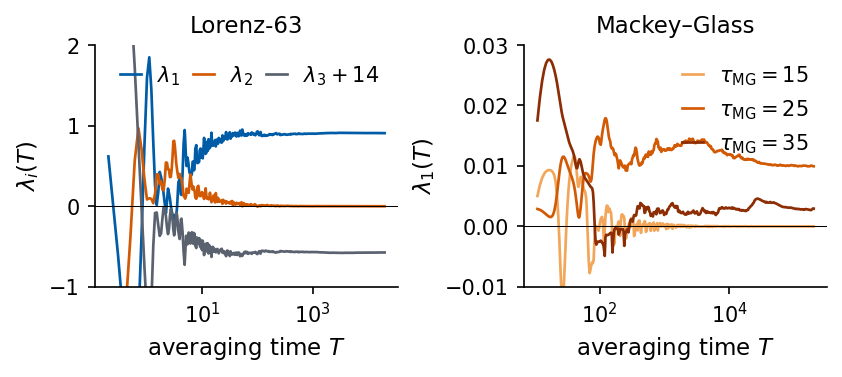

In [46]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    T = np.arange(1, n_blocks + 1) * T_BLOCK
    run_lor = np.cumsum(logs_lor, axis=0) / T[:, None]
    sl = np.unique(np.logspace(0, np.log10(n_blocks) - 1e-9, 400).astype(int))
    axs[0].semilogx(T[sl], run_lor[sl, 0], color=UJBlue, label=r"$\lambda_1$")
    axs[0].semilogx(T[sl], run_lor[sl, 1], color=DSOrange, label=r"$\lambda_2$")
    axs[0].semilogx(T[sl], (run_lor[sl, 2] + 14.0) , color=UJGray, label=r"$\lambda_3+14$")
    axs[0].axhline(0, color="k", lw=0.5)
    axs[0].set_ylim(-1.0, 2.0); axs[0].set_xlabel("averaging time $T$"); axs[0].set_ylabel(r"$\lambda_i(T)$")
    axs[0].set_title("Lorenz-63"); axs[0].legend(fontsize=10, loc="upper right", ncol=3, handlelength=1.0, columnspacing=0.6)
    Tm = np.arange(1, MG_T + 1)
    slm = np.unique(np.logspace(1, np.log10(MG_T) - 1e-9, 400).astype(int))
    for k, tau in (("mg15", 15), ("mg25", 25), ("mg35", 35)):
        run = np.cumsum(LOGS_MG[k][:, 0]) / Tm
        axs[1].semilogx(Tm[slm], run[slm], color=COL[k], label=rf"$\tau_{{\rm MG}}={tau}$")
    axs[1].axhline(0, color="k", lw=0.5); axs[1].set_ylim(-0.01, 0.03)
    axs[1].set_xlabel("averaging time $T$"); axs[1].set_ylabel(r"$\lambda_1(T)$"); axs[1].set_title("Mackey–Glass")
    axs[1].legend(fontsize=10, loc="upper right", ncol=1, handlelength=1.0)
    save(fig, "fig_lyap_convergence"); plt.show()

We plot the running averages $\lambda_i(T)=\frac1T\sum\ln|R_{ii}|$ against the averaging time $T$ on a logarithmic axis (for Lorenz the third exponent is shifted by 14 to fit the scale). Lorenz converges within about 100 time units. The Mackey–Glass exponents need $10^4$ time units, a hundred Lyapunov times of $\tau_{\rm MG}=25$, and the estimates for $\tau_{\rm MG}=35$ still wander by about $\pm0.001$ after $10^4$ time units.

### Exponents from data

For the laser we know no equations, and the exponents must come from the delay vectors. Rosenstein, Collins and De Luca estimate $\lambda_1$ directly [M. T. Rosenstein, J. J. Collins and C. J. De Luca, Physica D **65**, 117 (1993), [doi:10.1016/0167-2789(93)90009-P](https://doi.org/10.1016/0167-2789(93)90009-P)]. For each $\mathbf y_i$ we take its nearest neighbour $\mathbf y_{j(i)}$ outside the Theiler window and follow the distance of the two points $k$ steps later,
$$
\langle\ln d(k)\rangle=\frac{1}{N_{\rm pairs}}\sum_i\ln\big\|\mathbf y_{i+k}-\mathbf y_{j(i)+k}\big\| .
$$
In the range where the distance grows exponentially the curve is a straight line with slope $\lambda_1$ per sample. Before the range the pairs align with the unstable direction, after it the distance saturates at the size of the attractor. We first apply the method to Lorenz $x$, where we know the answer, and then to Santa Fe, with the embeddings of Section 6.

In [47]:
def rosenstein_curve(x, m, lag, w, k_max):
    """<ln d(k)> = mean over i of ln ||y_{i+k} - y_{j(i)+k}||, j(i) the nearest neighbour of y_i with |i - j| > w."""
    Y = delay_embed(x, m, lag)
    n = len(Y)
    j, _ = nearest_neighbour(jnp.asarray(Y), w)
    j = np.asarray(j); i = np.arange(n)
    out = []
    for k in range(k_max + 1):
        ok = (i + k < n) & (j + k < n)
        d = np.linalg.norm(Y[i[ok] + k] - Y[j[ok] + k], axis=1)
        out.append(np.log(d[d > 0]).mean())
    return np.array(out)

def slope(curve, k0, k1):
    return np.polyfit(np.arange(k0, k1 + 1), curve[k0:k1 + 1], 1)[0]

ROS = {}
ROS["lorenz"] = rosenstein_curve(S["lorenz"], EMB_M["lorenz"], LAG["lorenz"], 50, 150)
ROS["santafe"] = rosenstein_curve(S["santafe"], EMB_M["santafe"], LAG["santafe"], 50, 150)
FIT = {"lorenz": (25, 100), "santafe": (8, 40)}
lam_ros = {k: slope(ROS[k], *FIT[k]) for k in ROS}
print(f"Lorenz (m = {EMB_M['lorenz']}, κ = {LAG['lorenz']}): slope over k = 25..100 = {lam_ros['lorenz']:.4f} per sample"
      f" = {lam_ros['lorenz']/DT['lorenz']:.3f} per time unit (Benettin {lam_lor[0]:.3f})")
for k0, k1 in ((0, 25), (0, 50), (25, 100), (50, 100)):
    print(f"   Lorenz fit k = {k0:3d}..{k1:3d}: {slope(ROS['lorenz'], k0, k1)/DT['lorenz']:.3f} per time unit")
print(f"Santa Fe (m = {EMB_M['santafe']}, κ = {LAG['santafe']}): slope over k = 8..40 = {lam_ros['santafe']:.4f} per sample")
for k0, k1 in ((0, 8), (0, 40), (8, 40), (0, 150)):
    print(f"   Santa Fe fit k = {k0:3d}..{k1:3d}: {slope(ROS['santafe'], k0, k1):.4f} per sample")
# robustness of the Santa Fe slope against the embedding dimension
for m in (3, 4, 5, 6):
    c = rosenstein_curve(S["santafe"], m, LAG["santafe"], 50, 40)
    print(f"   Santa Fe m = {m}: slope k = 8..40 = {slope(c, 8, 40):.4f} per sample")
nums["rosenstein"] = {"lorenz_per_time": float(lam_ros["lorenz"] / DT["lorenz"]), "santafe_per_sample": float(lam_ros["santafe"])}

Lorenz (m = 4, κ = 10): slope over k = 25..100 = 0.0205 per sample = 1.026 per time unit (Benettin 0.907)
   Lorenz fit k =   0.. 25: 1.457 per time unit
   Lorenz fit k =   0.. 50: 1.421 per time unit
   Lorenz fit k =  25..100: 1.026 per time unit
   Lorenz fit k =  50..100: 0.953 per time unit
Santa Fe (m = 3, κ = 2): slope over k = 8..40 = 0.0291 per sample
   Santa Fe fit k =   0..  8: 0.0805 per sample
   Santa Fe fit k =   0.. 40: 0.0347 per sample
   Santa Fe fit k =   8.. 40: 0.0291 per sample
   Santa Fe fit k =   0..150: 0.0147 per sample
   Santa Fe m = 3: slope k = 8..40 = 0.0291 per sample
   Santa Fe m = 4: slope k = 8..40 = 0.0285 per sample
   Santa Fe m = 5: slope k = 8..40 = 0.0288 per sample
   Santa Fe m = 6: slope k = 8..40 = 0.0289 per sample


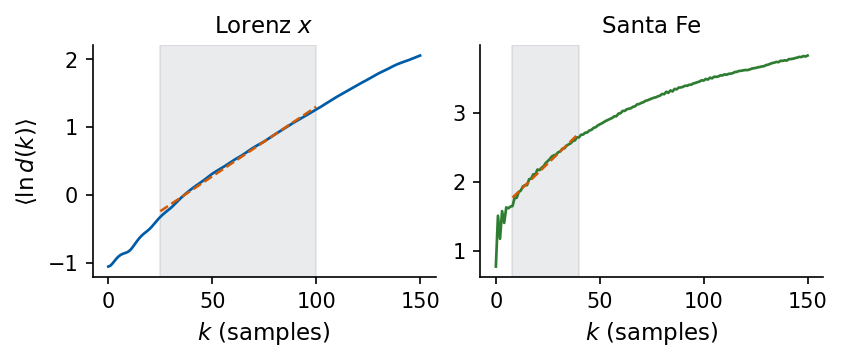

In [48]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    for ax, k, unit in ((axs[0], "lorenz", 0.02), (axs[1], "santafe", 1.0)):
        kk = np.arange(len(ROS[k]))
        ax.plot(kk, ROS[k], color=COL[k])
        k0, k1 = FIT[k]
        b = np.polyfit(np.arange(k0, k1 + 1), ROS[k][k0:k1 + 1], 1)
        ax.plot(np.arange(k0, k1 + 1), np.polyval(b, np.arange(k0, k1 + 1)), "--", color=DSOrange, lw=1.2)
        ax.axvspan(k0, k1, color=UJGray, alpha=0.12)
        ax.set_xlabel("$k$ (samples)"); ax.set_title(LABEL[k])
    axs[0].set_ylabel(r"$\langle\ln d(k)\rangle$")
    save(fig, "fig_rosenstein"); plt.show()

For Lorenz $x$ ($m=4$, $\kappa=10$) the slope over $k=25$–100 samples (0.5 to 2 time units) is 1.03 per time unit, 13% above the Benettin value 0.907, and fits starting at $k=0$ give 1.4 to 1.5. The initial steep part of the curve comes from the alignment of the separation with the unstable direction and from the oscillation of $x$, and it must be excluded. For Santa Fe the curve rises steeply during the first pulsation period (about 8 samples), then grows nearly linearly, and bends over beyond about 40 samples. Over $k=8$–40 we find $\lambda_1=0.029$ per sample, and this slope changes by less than 0.001 when $m$ goes from 3 to 6. The value depends strongly on the fit range. Starting at $k=0$ gives 0.080 for the first 8 samples, and a fit over the first 150 samples, which reach into the saturation, gives 0.0147.

Sano and Sawada estimate the whole spectrum from data [M. Sano and Y. Sawada, Phys. Rev. Lett. **55**, 1082 (1985), [doi:10.1103/PhysRevLett.55.1082](https://doi.org/10.1103/PhysRevLett.55.1082)]. Around each point a matrix $A_i$ is fitted by least squares to the evolution of its $K$ nearest neighbours, $\mathbf y_{j+1}-\mathbf y_{i+1}\approx A_i(\mathbf y_j-\mathbf y_i)$, and the Benettin QR procedure is applied to the product of these local Jacobians. We use $K=63$ neighbours and standardised data, with the embedding $m=4$, $\kappa=2$ and, for comparison, with our embedding of Section 6.

In [49]:
def local_jacobian_spectrum(x, m, lag, K, step=1):
    """Sano-Sawada estimate. For each y_i: least-squares matrix A_i with y_{j+step} - y_{i+step} ~ A_i (y_j - y_i)
    over the K nearest neighbours j; then Benettin QR on the product of the A_i. Data are standardised first.
    Returns the m exponents per sample, sorted."""
    Y = delay_embed((x - x.mean()) / x.std(), m, lag)
    N = len(Y)
    _, nb = cKDTree(Y).query(Y, k=K + 1)
    Q = np.eye(m); acc = np.zeros(m); count = 0
    for i in range(0, N - step - 1, step):
        j = nb[i, 1:]; j = j[j + step < N]
        A = np.linalg.lstsq(Y[j] - Y[i], Y[j + step] - Y[i + step], rcond=None)[0].T
        Q, R = np.linalg.qr(A @ Q)
        acc += np.log(np.abs(np.diag(R))); count += 1
    return np.sort(acc / (count * step))[::-1]

t0 = time.time()
ss_m4 = local_jacobian_spectrum(S["santafe"], 4, 2, 63)
ss_ours = local_jacobian_spectrum(S["santafe"], EMB_M["santafe"], LAG["santafe"], 63)
ss_lor = local_jacobian_spectrum(S["lorenz"], EMB_M["lorenz"], LAG["lorenz"], 63) / DT["lorenz"]
print(f"({time.time()-t0:.1f} s)")
print("Santa Fe, m = 4, κ = 2, K = 63:", np.round(ss_m4, 4))
print(f"Santa Fe, m = {EMB_M['santafe']}, κ = {LAG['santafe']}, K = 63:", np.round(ss_ours, 4))
print(f"Lorenz x, m = {EMB_M['lorenz']}, κ = {LAG['lorenz']}, K = 63 (per time unit):", np.round(ss_lor, 3))
nums["sano_santafe_m4"] = ss_m4.tolist(); nums["sano_santafe_ours"] = ss_ours.tolist(); nums["sano_lorenz"] = ss_lor.tolist()

(1.3 s)
Santa Fe, m = 4, κ = 2, K = 63: [ 0.0651 -0.0044 -0.3822 -1.5587]
Santa Fe, m = 3, κ = 2, K = 63: [ 0.0793 -0.0302 -0.9303]
Lorenz x, m = 4, κ = 10, K = 63 (per time unit): [ 1.012  0.171 -2.189 -6.632]


With $m=4$ and $\kappa=2$ the leading exponent of the laser is $\lambda_1=0.065$ per sample. The same algorithm applied to Lorenz $x$ gives $\lambda_1=1.01$ per time unit (12% high), a spurious second exponent $0.17$ in place of zero, and $\lambda_3=-2.2$ in place of $-14.6$. Strongly contracting directions are almost empty of neighbours and cannot be fitted from 4000 points. For the laser the two methods differ by a factor of two, 0.029 per sample from Rosenstein and 0.065 from the local Jacobians. Both are estimates with method-dependent biases, and we keep the method next to every number.

<hr/>
## 9. Kaplan–Yorke dimension and prediction horizon

The exponents also measure the size of the attractor. The sum $\Sigma_k=\lambda_1+\dots+\lambda_k$ is the growth rate of $k$-dimensional volumes. Let $j$ be the largest index with $\Sigma_j\ge0$. Volumes of dimension $j$ do not shrink and volumes of dimension $j+1$ do, so the attractor has a dimension between $j$ and $j+1$. Kaplan and Yorke interpolated linearly between the two [J. L. Kaplan and J. A. Yorke, Lect. Notes Math. **730**, 204 (1979), [doi:10.1007/BFb0064319](https://doi.org/10.1007/BFb0064319)],
$$
D_{\rm KY}=j+\frac{\Sigma_j}{|\lambda_{j+1}|} ,
$$
the Kaplan–Yorke (KY) or Lyapunov dimension. Exponents that are zero within their statistical error would make the result jump between integers depending on the sign of noise, so we set exponents with $|\lambda_i|$ below three standard errors to zero before applying the formula.

In [50]:
def kaplan_yorke(lams, tol=0.0):
    """D_KY = j + Sigma_j / |lambda_{j+1}|, j the largest index with Sigma_j = lambda_1 + ... + lambda_j >= 0.
    Exponents with |lambda| < tol are set to zero first (they cannot be told apart from zero)."""
    lams = np.where(np.abs(lams) < tol, 0.0, np.sort(lams)[::-1])
    cs = np.cumsum(lams)
    if cs[0] < 0:
        return 0.0
    j = int(np.max(np.nonzero(cs >= 0)[0])) + 1          # number of leading exponents with Sigma_j >= 0
    if j == len(lams):
        return np.nan                                       # not enough exponents computed
    return j + cs[j - 1] / abs(lams[j])

DKY = {"lorenz": kaplan_yorke(lam_lor, tol=3 * err_lor.max())}
for k in ("mg15", "mg25", "mg35"):
    DKY[k] = kaplan_yorke(LYAP_MG[k], tol=3 * ERR_MG[k][:4].max())
DKY["santafe"] = kaplan_yorke(ss_m4)
DKY_raw = {"lorenz": kaplan_yorke(lam_lor), **{k: kaplan_yorke(LYAP_MG[k]) for k in LYAP_MG}}
print(f"Lorenz   D_KY = {DKY['lorenz']:.4f}")
for k, tau in (("mg15", 15), ("mg25", 25), ("mg35", 35)):
    print(f"MG {tau}    D_KY = {DKY[k]:.3f} (tolerance {3*ERR_MG[k][:4].max():.1e}; without tolerance {DKY_raw[k]:.3f})")
print(f"Santa Fe D_KY = {DKY['santafe']:.3f} from the local-Jacobian spectrum with m = 4")
print(f"Santa Fe D_KY with our embedding: {kaplan_yorke(ss_ours):.3f}")
nums["dky"] = {k: float(v) for k, v in DKY.items()}

Lorenz   D_KY = 2.0622
MG 15    D_KY = 1.000 (tolerance 4.7e-05; without tolerance 0.000)
MG 25    D_KY = 3.158 (tolerance 8.4e-04; without tolerance 3.158)
MG 35    D_KY = 3.406 (tolerance 1.1e-03; without tolerance 3.416)
Santa Fe D_KY = 2.159 from the local-Jacobian spectrum with m = 4
Santa Fe D_KY with our embedding: 2.053


Lorenz-63 has $D_{\rm KY}=2.062$, a little more than a surface. The periodic orbit at $\tau_{\rm MG}=15$ has $D_{\rm KY}=1.000$, a closed curve. For $\tau_{\rm MG}=25$ we find 3.158 and for $\tau_{\rm MG}=35$ 3.41, so the attractor of the delay system grows with the delay even though $\lambda_1$ decreases. At $\tau_{\rm MG}=35$ the value is sensitive to $\lambda_1$, which enters $\Sigma_3$ and has a standard error of 0.0004. For the laser the local-Jacobian spectrum gives $D_{\rm KY}=2.16$ with $m=4$ and 2.05 with our $m=3$.

The leading exponent sets the prediction horizon. An initial error $\delta_0$ grows on average as $\delta(t)\approx\delta_0e^{\lambda_1t}$, and it reaches a tolerance $\Delta$ after
$$
T_{\rm pred}=\frac{1}{\lambda_1}\ln\frac{\Delta}{\delta_0} .
$$
The Lyapunov time $T_\lambda=1/\lambda_1$ is the time for an $e$-fold growth. A thousand times better initial data extend the horizon by only $\ln(1000)\,T_\lambda\approx6.9\,T_\lambda$. We test the formula on Lorenz-63 with 200 pairs of trajectories that start at points of the attractor and differ by $|\delta_0|=10^{-8}$ in a random direction.

one pair: slope of ln|delta| for 2 < t < 15 = 0.930 per time unit (lambda_1 = 0.907); |delta| exceeds 1 at t = 19.5


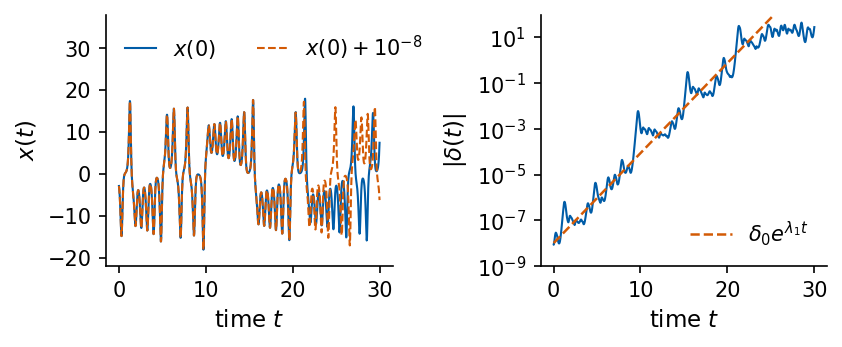

In [51]:
# two Lorenz trajectories that start 1e-8 apart (along x), followed for 30 time units
u_a = jnp.asarray(lor_states[0]); u_b = u_a + jnp.array([1e-8, 0.0, 0.0])
def follow(u, n):
    out = []
    for _ in range(n):
        u = lorenz_map(lorenz_map(u)); out.append(u)
    return np.asarray(jnp.stack(out))
n_tw = 1500
tr_a, tr_b = follow(u_a, n_tw), follow(u_b, n_tw)
t_tw = np.arange(1, n_tw + 1) * 0.02
dist = np.linalg.norm(tr_a - tr_b, axis=1)
fit = (t_tw > 2) & (t_tw < 15)
slope_one = np.polyfit(t_tw[fit], np.log(dist[fit]), 1)[0]
t_apart = t_tw[np.argmax(dist > 1.0)]
print(f"one pair: slope of ln|delta| for 2 < t < 15 = {slope_one:.3f} per time unit (lambda_1 = {lam_lor[0]:.3f});"
      f" |delta| exceeds 1 at t = {t_apart:.1f}")
nums["twin"] = {"slope": float(slope_one), "t_apart": float(t_apart)}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.2), layout="constrained")
    axs[0].plot(t_tw, tr_a[:, 0], color=UJBlue, lw=1.0, label="$x(0)$")
    axs[0].plot(t_tw, tr_b[:, 0], "--", color=DSOrange, lw=1.0, label=r"$x(0)+10^{-8}$")
    axs[0].set_xlabel("time $t$"); axs[0].set_ylabel("$x(t)$"); axs[0].legend(loc="upper left", fontsize=10, ncol=2, handlelength=1.5)
    axs[0].set_ylim(-22, 38)
    axs[1].semilogy(t_tw, dist, color=UJBlue, lw=1.0)
    axs[1].semilogy(t_tw, 1e-8 * np.exp(lam_lor[0] * t_tw), "--", color=DSOrange, lw=1.2, label=r"$\delta_0 e^{\lambda_1 t}$")
    axs[1].set_xlabel("time $t$"); axs[1].set_ylabel(r"$|\delta(t)|$"); axs[1].set_ylim(1e-9, 1e2)
    axs[1].legend(loc="lower right", fontsize=10)
    save(fig, "fig_lorenz_twin"); plt.show()

growth rate of <ln|delta|> for 2 < t < 15: 0.897 per time unit (lambda_1 = 0.907)
<ln|delta|> reaches ln(Delta) for Delta = 1.0 at t = 20.44; T_pred = ln(Delta/delta0)/lambda_1 = 20.31 time units = 1016 samples
saturation level exp<ln|delta|> over the last 5 time units: 12.2


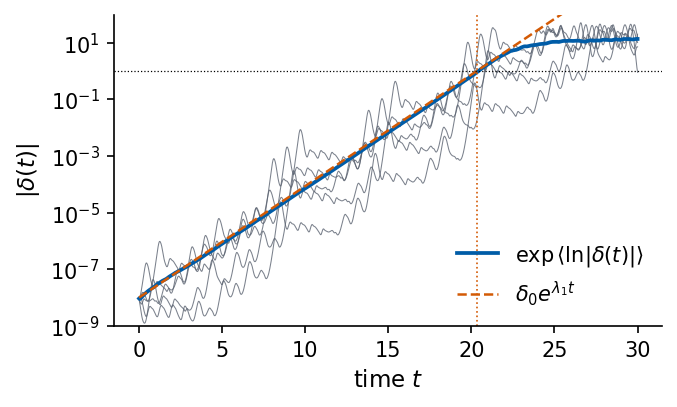

In [52]:
@partial(jax.jit, static_argnums=2)
def twin_separation(u0, d0, n_samples):
    """Two Lorenz trajectories from u0 and u0 + d0 (RK4, h = 0.01); |delta| every 0.02 time units."""
    def one(c, _):
        a, b = c
        for _ in range(2):
            a, b = lorenz_map(a), lorenz_map(b)
        return (a, b), jnp.linalg.norm(a - b)
    return jax.lax.scan(one, (u0, u0 + d0), None, length=n_samples)[1]

DELTA0 = 1e-8
n_pairs, n_t = 200, 1500                                       # 200 starting points, 30 time units
key_dirs = jax.random.normal(jax.random.key(3), (n_pairs, 3))
d0s = DELTA0 * key_dirs / jnp.linalg.norm(key_dirs, axis=1, keepdims=True)    # random directions, |d0| = 1e-8
starts = jnp.asarray(lor_states[::20][:n_pairs])
seps = np.asarray(jax.vmap(twin_separation, in_axes=(0, 0, None))(starts, d0s, n_t))   # (200, 1500)
tt = np.arange(1, n_t + 1) * 0.02
mean_log = np.log(seps).mean(0)
fit_win = (tt > 2) & (tt < 15)
growth = np.polyfit(tt[fit_win], mean_log[fit_win], 1)[0]
DELTA = 1.0
t_cross = tt[np.argmax(mean_log > np.log(DELTA))]
t_pred = np.log(DELTA / DELTA0) / lam_lor[0]
print(f"growth rate of <ln|delta|> for 2 < t < 15: {growth:.3f} per time unit (lambda_1 = {lam_lor[0]:.3f})")
print(f"<ln|delta|> reaches ln(Delta) for Delta = {DELTA} at t = {t_cross:.2f}; "
      f"T_pred = ln(Delta/delta0)/lambda_1 = {t_pred:.2f} time units = {t_pred/0.02:.0f} samples")
print(f"saturation level exp<ln|delta|> over the last 5 time units: {np.exp(mean_log[-250:].mean()):.1f}")
nums["error_growth"] = {"rate": float(growth), "t_cross": float(t_cross), "t_pred": float(t_pred),
                        "delta0": DELTA0, "Delta": DELTA}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.6), layout="constrained")
    for p in range(5):
        ax.semilogy(tt, seps[p], color=UJGray, lw=0.5, alpha=0.8)
    ax.semilogy(tt, np.exp(mean_log), color=UJBlue, lw=1.8, label=r"$\exp\langle\ln|\delta(t)|\rangle$")
    ax.semilogy(tt, DELTA0 * np.exp(lam_lor[0] * tt), "--", color=DSOrange, lw=1.2, label=r"$\delta_0 e^{\lambda_1 t}$")
    ax.axhline(DELTA, color="k", lw=0.6, ls=":"); ax.axvline(t_pred, color=DSOrange, lw=0.8, ls=":")
    ax.set_xlabel("time $t$"); ax.set_ylabel(r"$|\delta(t)|$"); ax.set_ylim(1e-9, 1e2); ax.legend(loc="lower right", fontsize=10)
    save(fig, "fig_error_growth"); plt.show()

Grey lines are five individual pairs, the blue line is $\exp\langle\ln|\delta(t)|\rangle$ over the 200 pairs, and the dashed line is $\delta_0e^{\lambda_1t}$ with the Benettin $\lambda_1$. Single pairs grow irregularly, because the local growth rate varies along the attractor. The average grows at 0.897 per time unit for $2<t<15$, close to $\lambda_1=0.907$, and reaches $\Delta=1$ at $t=20.4$, against $T_{\rm pred}=\ln(10^8)/\lambda_1=20.3$ time units (1016 samples). The error then saturates at the size of the attractor ($\approx12$).

<hr/>
## 10. Signal characteristics

The table collects the characterisation of the five signals. Correlation times and the delay $\kappa$ are in samples. The leading exponent comes from the Benettin algorithm for the model signals and from the Rosenstein fit over $k=8$–40 for Santa Fe, where the local-Jacobian estimate is printed after the table. The Lyapunov time $T_\lambda=1/\lambda_1$ is in samples and set to infinity where $\lambda_1$ is zero within its error. The same table is written as a LaTeX tabular for the slides, where R and SS denote the Rosenstein and Sano–Sawada estimates.

In [53]:
PSD_CHAR = {"lorenz": "broadband", "mg15": "lines", "mg25": "broad peaks", "mg35": "broad peaks", "santafe": "peak + harmonics"}
lam1_sample = {"lorenz": lam_lor[0] * DT["lorenz"], "mg15": LYAP_MG["mg15"][0], "mg25": LYAP_MG["mg25"][0],
               "mg35": LYAP_MG["mg35"][0], "santafe": lam_ros["santafe"]}
METHOD = {"lorenz": "Benettin", "mg15": "Benettin", "mg25": "Benettin", "mg35": "Benettin", "santafe": "Rosenstein"}
rows = []
for k in KEYS:
    l1 = lam1_sample[k]
    chaotic = l1 > 3 * (err_lor[0] * DT["lorenz"] if k == "lorenz" else ERR_MG[k][0] if k in ERR_MG else 0)
    rows.append({"signal": LABEL[k], "ACF zero": CT[k][0], "ACF 1/e": CT[k][1], "PSD": PSD_CHAR[k],
                 "delay κ": LAG[k], "m": EMB_M[k], "lambda_1 per sample": l1,
                 "lambda_1 per time unit": l1 / DT[k] if k != "santafe" else np.nan,
                 "method": METHOD[k], "D_KY": DKY[k], "T_lambda (samples)": 1 / l1 if chaotic else np.inf})
summary = pd.DataFrame(rows).set_index("signal")
display(summary.round(4))
print(f"Santa Fe, local-Jacobian (Sano-Sawada) lambda_1 = {ss_m4[0]:.4f} per sample, T_lambda = {1/ss_m4[0]:.1f} samples")
for k in KEYS:
    print(f"{LABEL[k]:22s} mean error growth over the horizon of {TAU_MAX} steps, exp(lambda_1 * {TAU_MAX}) = {np.exp(lam1_sample[k] * TAU_MAX):.2f}")
print(f"Santa Fe with the local-Jacobian lambda_1: exp(lambda_1 * {TAU_MAX}) = {np.exp(ss_m4[0] * TAU_MAX):.1f}")
nums["summary"] = {k: {c: (v if isinstance(v, str) else float(v)) for c, v in r.items()} for k, r in zip(KEYS, rows)}

Santa Fe, local-Jacobian (Sano-Sawada) lambda_1 = 0.0651 per sample, T_lambda = 15.4 samples
Lorenz $x$             mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 2.48
MG $\tau_{\rm MG}=15$  mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 1.00
MG $\tau_{\rm MG}=25$  mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 1.64
MG $\tau_{\rm MG}=35$  mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 1.16
Santa Fe               mean error growth over the horizon of 50 steps, exp(lambda_1 * 50) = 4.29
Santa Fe with the local-Jacobian lambda_1: exp(lambda_1 * 50) = 26.0


,ACF zero,ACF 1/e,PSD,delay κ,m,lambda_1 per sample,lambda_1 per time unit,method,D_KY,T_lambda (samples)
signal,,,,,,,,,,
Lorenz $x$,89,15,broadband,10,4,0.0181,0.9068,Benettin,2.0622,55.1413
MG $\tau_{\rm MG}=15$,11,9,lines,8,2,-0.0000,-0.0000,Benettin,1.0000,inf
MG $\tau_{\rm MG}=25$,18,12,broad peaks,16,4,0.0099,0.0099,Benettin,3.1576,100.5282
MG $\tau_{\rm MG}=35$,24,15,broad peaks,26,4,0.0029,0.0029,Benettin,3.4058,339.6271
Santa Fe,2,2,peak + harmonics,2,3,0.0291,NaN,Rosenstein,2.1590,34.3358


In [54]:
def tex_num(v, d):
    return "--" if not np.isfinite(v) else f"{v:.{d}f}"
SIGNAL_TEX = {"lorenz": "Lorenz $x$", "mg15": "MG, $\\tau_{\\rm MG}=15$", "mg25": "MG, $\\tau_{\\rm MG}=25$",
              "mg35": "MG, $\\tau_{\\rm MG}=35$", "santafe": "Santa Fe"}
lines = ["\\begin{tabular}{lrrlrrrrr}", "\\toprule",
         "signal & $\\rho=0$ & $\\rho=1/e$ & PSD & $\\kappa$ & $m$ & $\\lambda_1$/sample & $D_{\\rm KY}$ & $T_\\lambda$ \\\\",
         "\\midrule"]
for k in KEYS:
    r = nums["summary"][k]
    l1 = f"{r['lambda_1 per sample']:.4f}" if k != "mg15" else "$\\approx 0$"
    if k == "santafe":
        l1 += f" (R), {ss_m4[0]:.3f} (SS)"
    T = "$\\infty$" if not np.isfinite(r["T_lambda (samples)"]) else f"{r['T_lambda (samples)']:.0f}"
    lines.append(f"{SIGNAL_TEX[k]} & {r['ACF zero']:.0f} & {r['ACF 1/e']:.0f} & {r['PSD']} & {r['delay κ']:.0f} & "
                 f"{r['m']:.0f} & {l1} & {r['D_KY']:.2f} & {T} \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]
with open(f"{OUT}/table_lab033_summary.tex", "w") as fh:
    fh.write("\n".join(lines) + "\n")
print("\n".join(lines))

\begin{tabular}{lrrlrrrrr}
\toprule
signal & $\rho=0$ & $\rho=1/e$ & PSD & $\kappa$ & $m$ & $\lambda_1$/sample & $D_{\rm KY}$ & $T_\lambda$ \\
\midrule
Lorenz $x$ & 89 & 15 & broadband & 10 & 4 & 0.0181 & 2.06 & 55 \\
MG, $\tau_{\rm MG}=15$ & 11 & 9 & lines & 8 & 2 & $\approx 0$ & 1.00 & $\infty$ \\
MG, $\tau_{\rm MG}=25$ & 18 & 12 & broad peaks & 16 & 4 & 0.0099 & 3.16 & 101 \\
MG, $\tau_{\rm MG}=35$ & 24 & 15 & broad peaks & 26 & 4 & 0.0029 & 3.41 & 340 \\
Santa Fe & 2 & 2 & peak + harmonics & 2 & 3 & 0.0291 (R), 0.065 (SS) & 2.16 & 34 \\
\bottomrule
\end{tabular}


<hr/>
## 11. Consequences for forecasting

The forecasting notebooks use horizons of 1 to 50 steps, and the Lyapunov times give the scale against which to read them. For Lorenz $x$ the Lyapunov time is 55 samples, so the longest horizon is about one $T_\lambda$, over which an initial error grows on average by the factor $e^{50/T_\lambda}=2.5$. For $\tau_{\rm MG}=25$ ($T_\lambda\approx100$ samples) and $\tau_{\rm MG}=35$ ($T_\lambda\approx340$ samples) all horizons lie well within one Lyapunov time (error growth by the factors 1.64 and 1.16 over 50 steps), and the limit to forecasting comes from how well a model learns the dynamics. The periodic $\tau_{\rm MG}=15$ has no finite Lyapunov time, and a model that captures its line spectrum can forecast it at all horizons. The laser has the shortest Lyapunov time, 34 samples from the Rosenstein estimate and 15 from the local Jacobians, so the horizon of 50 steps spans 1.5 to 3.2 Lyapunov times and an initial error grows by a factor between 4.3 and 26 over it. Forecasts of the laser must lose skill within the tested range.

The embedding sets the length of the input window. A model that receives the delay vector with $m$ entries at spacing $\kappa$ sees a window of $(m-1)\kappa+1$ samples, 31 samples for Lorenz $x$, 49 for $\tau_{\rm MG}=25$, 79 for $\tau_{\rm MG}=35$ and 5 for Santa Fe. Shorter windows leave states unresolved, and for Mackey–Glass the window must reach back over the delay of the equation.

The exponents and the dimensions point to nonlinear models. All three chaotic signals have a positive leading Lyapunov exponent and attractors with $D_{\rm KY}$ between 2 and 3.5. In the logistic map of Section 7 such sensitivity arises from stretching and folding, and a linear model fitted to these signals can reproduce their spectra, while a linear map cannot fold. Linear autoregressive models are therefore baselines for these signals, and the gain of a nonlinear model, such as the nonlinear vector autoregression or a recurrent network, is expected where the folding acts, at the lobe switches of Lorenz and at the collapses of the laser.

<hr/>
## Predictability of the benchmark signals

We characterised three signals that are used as benchmarks for forecasting. Constant, periodic and quasi-periodic signals are forecast without error from their past, white noise at best by its mean and the random walk by its last value. Chaotic signals are deterministic, and their forecasts are still limited by the exponential growth of small errors. Lorenz-63 is a three-mode model of convection whose two convective fixed points lose stability at $\rho_c=24.737$. Mackey–Glass is a delay equation with an infinite-dimensional state, here periodic at $\tau_{\rm MG}=15$ and chaotic at 25 and 35. The Santa Fe record is the intensity of a chaotic NH$_3$ laser described by the Maxwell–Bloch equations.

The ACF and the PSD are a Fourier pair, which holds also for the finite-sample estimates. The periodogram needs a window against leakage and averaging (Welch) against its large variance. The periodic Mackey–Glass signal has a line spectrum with the strongest line at period $\approx3\tau_{\rm MG}$ and its fundamental at twice that period. The chaotic signals have broadband spectra, Santa Fe with a pulsation peak at 7.26 samples.

Delay vectors $(s_n,s_{n-\kappa},\dots,s_{n-(m-1)\kappa})$ reconstruct the state space (Takens). The mutual information gives the delay $\kappa$ and false nearest neighbours the dimension $m$. Chaos arises from stretching and folding, as the logistic map shows with $\lambda=\ln2$ at $r=4$. The Benettin QR algorithm with JAX derivatives of the integration step gives the Lorenz spectrum $(0.907,0,-14.573)$ whose sum equals the volume contraction rate of the flow, and the Mackey–Glass spectra in state spaces of up to 351 dimensions. From data, Rosenstein and Sano–Sawada estimates of $\lambda_1$ for the laser differ by a factor of two, and the method must be stated with the number. The Kaplan–Yorke dimension turns the spectrum into an attractor dimension, 2.06 for Lorenz and 3.16 and 3.41 for the chaotic Mackey–Glass signals, and the Lyapunov time sets the prediction horizon $T_{\rm pred}=\lambda_1^{-1}\ln(\Delta/\delta_0)$, confirmed by the error growth of nearby Lorenz trajectories.

In [55]:
# Export the numerical results used by the slides and lecture notes.
# Values come from this execution; no previously generated TeX file is read.
def export_py(value):
    if isinstance(value, dict):
        return {str(k): export_py(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [export_py(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value

macros = {}
def export_number(name, value, digits):
    macros[name] = f"{float(value):.{digits}f}"

for name, value, digits in (
    ("LorenzRhoC", nums["lorenz_rho_c"], 2),
    ("LorenzOmega", nums["lorenz_Cplus_eig"][2], 2),
    ("LorenzDiv", nums["lorenz_div"], 3),
    ("LorenzLyapOne", nums["lorenz_lyap"][0], 3),
    ("LorenzLyapTwo", nums["lorenz_lyap"][1], 4),
    ("LorenzLyapThree", nums["lorenz_lyap"][2], 3),
    ("LorenzLyapSum", nums["lorenz_lyap_sum"], 3),
    ("LorenzLyapErr", nums["lorenz_lyap_err"][0], 3),
    ("LorenzRosenstein", nums["rosenstein"]["lorenz_per_time"], 2),
    ("LorenzSanoOne", nums["sano_lorenz"][0], 2),
    ("LorenzTpred", nums["error_growth"]["t_pred"], 1),
    ("LorenzTcross", nums["error_growth"]["t_cross"], 1),
    ("LorenzGrowth", nums["error_growth"]["rate"], 2),
    ("TwinSlope", nums["twin"]["slope"], 2),
    ("TwinApart", nums["twin"]["t_apart"], 0),
    ("LogisticLambdaFour", nums["logistic_lambda_r4"], 4),
    ("LogisticSepN", nums["logistic_sep_n"], 0),
    ("LogisticOnset", nums["logistic_r_onset"], 3),
    ("MGfifteenPeriod", nums["mg15_period"], 1),
    ("SantaFeRosenstein", nums["rosenstein"]["santafe_per_sample"], 3),
    ("SantaFeSanoOne", nums["sano_santafe_m4"][0], 3),
    ("SantaFeLevels", nums["santafe_distinct_levels"], 0),
):
    export_number(name, value, digits)

signal_tags = {"lorenz": "Lorenz", "mg15": "MGfifteen", "mg25": "MGtwentyfive",
               "mg35": "MGthirtyfive", "santafe": "SantaFe"}
for signal, tag in signal_tags.items():
    row = nums["summary"][signal]
    for suffix, field, digits in (("Lag", "delay κ", 0), ("Dim", "m", 0),
                                  ("DKY", "D_KY", 2), ("AcfZero", "ACF zero", 0),
                                  ("AcfE", "ACF 1/e", 0)):
        export_number(tag + suffix, row[field], digits)
    if signal in nums["mg_lyap"]:
        export_number(tag + "LyapOne", nums["mg_lyap"][signal][0], 4)
        export_number(tag + "LyapTwo", nums["mg_lyap"][signal][1], 4)
        if np.isfinite(row["T_lambda (samples)"]):
            export_number(tag + "Tlyap", row["T_lambda (samples)"], 0)

nums["exported_macro_values"] = dict(macros)
with open(f"{OUT}/numbers_lab033.json", "w") as fh:
    json.dump(export_py(nums), fh, indent=1, allow_nan=False)
with open(f"{OUT}/nb_numbers_lab033.tex", "w") as fh:
    for name, value in macros.items():
        assert name.isalpha()
        fh.write(f"\\newcommand{{\\labthreethree{name}}}{{{value}}}\n")
print(f"Exported {len(macros)} current lab033 macros and numbers_lab033.json")


Exported 55 current lab033 macros and numbers_lab033.json
